# 🛠️ Ball-Bearing Prognostics from Run-to-Failure Data
## Early Degradation Detection, Ordinal Machine-Status Classification and Remaining Useful Life (RUL) Estimation
### Exploratory data analysis and modelling on the KAIST NSK 6205 ball-bearing run-to-failure dataset (vibration and temperature)
Organized by the six EDA instructions (Sections 1–6), each followed by its key findings; Section 7 keeps the
machine-learning steps that build the interactive dashboard.

**ISE 518 – Data Analytics for Reliability and Maintenance** · King Fahd University of Petroleum & Minerals · First Semester 2026-27
**Instructor:** Dr. Alaa Khamis · **Group 8**

| Member | Student ID |
|---|---|
| Mohammed Alsulami | 202612840 |
| Bassam Alawam | 202612700 |
| Nasser Alasmari | 201765530 |
| Mohammad Almarhoon | 201914630 |

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alsulami412-arch/ISE518-Bearing-RUL/blob/main/ISE518_G8_Bearing_EDA_RUL_V3.ipynb)

> **Project goal.** Detect bearing degradation as early as possible, classify the **machine status on an ordinal scale**
> (✅ Operational → 🔻 Degraded → ⚠️ At risk → ❌ Fault detected) and estimate how many hours of useful life remain,
> using the vibration and temperature signals of a ball bearing that was run until it failed. We also built an
> **interactive dashboard for the evening- and night-shift DCS operators**: it shows the machine status, explains every 👁 watch
> and 🔔 alarm, and gives the highest load that still reaches the next planned stop, so the operators can control the failure
> until maintenance replaces the bearing ([open the dashboard](https://raw.githack.com/alsulami412-arch/ISE518-Bearing-RUL/main/dashboard/bearing_dashboard.html), Section 7.11).



---
## 1️⃣ 1. Setup and Data Loading

### 1.1 Setup: libraries and constants
Libraries are grouped by role. Everything used here is pre-installed in this code.

In [ ]:
# --- core data handling --------------------------------------------------------------
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd

# --- visualization -------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML, Markdown

# --- statistics and signal processing ----------------------------------------------------
from scipy import stats, signal
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, ccf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.miscmodels.ordinal_model import OrderedModel      # ordinal (proportional-odds) logistic regression

# --- machine learning ----------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import (IsolationForest, RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingRegressor)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             f1_score, cohen_kappa_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.labelsize": 10, "legend.fontsize": 9})
RNG = 42                      # one random seed for every stochastic step (reproducibility)
np.random.seed(RNG)
print("pandas", pd.__version__, "| numpy", np.__version__, "| statsmodels", sm.__version__)

pandas 2.2.3 | numpy 2.4.6 | statsmodels 0.15.0


In [ ]:
# --- where the data lives -----------------------------------------------------------------
# The raw dataset (129 CSV files, 18.5 GB) was aggregated by pipeline/build_features.py.
# The resulting tables are stored in this project's GitHub repository and read by URL.
REPO_RAW = "https://raw.githubusercontent.com/alsulami412-arch/ISE518-Bearing-RUL/main/"
DATA_URL = REPO_RAW + "data/processed/"
LOCAL_DATA = Path("data/processed")          # used automatically when running from a local clone

def load_csv(name, **kwargs):
    """Read a processed table from a local clone if available, otherwise from GitHub."""
    local = LOCAL_DATA / name
    return pd.read_csv(local if local.exists() else DATA_URL + name, **kwargs)

# --- test and bearing constants (Jung et al., Data in Brief 54, 2024) -------------------------
FS = 25_600                     # sampling rate [Hz]
G = 9.80665                     # 1 g in m/s^2
TEST_START = pd.Timestamp("2022-06-20 17:00")
FAIL_TEMP_C = 85.0              # stop criterion: bearing temperature [degC] ...
FAIL_VIB_MS2 = 9.0              # ... and vibration [m/s^2] (ISO 10816 based, from the article)

# --- consistent colors -------------------------------------------------------------------------
STAGE_ORDER = ["Run-in", "Healthy", "Degrading", "Failure"]          # physical stages (rule-based, Section 3.7)
STAGE_COLORS = {"Run-in": "#8d99ae", "Healthy": "#2a9d8f", "Degrading": "#e9a03b", "Failure": "#d1495b"}
AXIS_COLORS = {"x": "#3d5a80", "y": "#ee6c4d"}

# --- the ordinal response Y(t): machine status (Section 1.2) -----------------------------------
STATUS_ORDER = ["Operational", "Degraded", "At risk", "Fault detected"]   # Y = 0 < 1 < 2 < 3
STATUS_ICON = {"Operational": "✅", "Degraded": "🔻", "At risk": "⚠️", "Fault detected": "❌"}
STATUS_COLORS = {"Operational": "#2a9d8f", "Degraded": "#e9c46a", "At risk": "#f4a261", "Fault detected": "#d1495b"}
STATUS_ACTION = {"Operational": "any load up to high; continue normal monitoring",
                 "Degraded": "limit to medium load; plan the replacement",
                 "At risk": "limit to low load; replace at the next opportunity",
                 "Fault detected": "STOP the machine and replace the bearing"}
STATUS_CUTS = (12, 6, 3)      # hours to end of life where the status steps up (3 h = stop criterion met, checked in 3.7)

# --- load scenarios for the DCS: fraction of the tested radial and axial loads (Sections 1.6 and 7.2) ------------
LOAD_SCENARIOS = {"High": 1.00, "Medium": 0.75, "Low": 0.50}
LOAD_COLORS = {"High": "#d1495b", "Medium": "#e9a03b", "Low": "#2a9d8f"}

---
### 1.2 Background: the problem (Step 1 of the 7-step procedure)
Before touching the data we define the problem, the physics that
creates the signals, and what a useful answer looks like.

#### 1.2.1 Why bearings, and why early detection?
Rolling-element bearings carry the shaft in almost every rotating machine – electric motors, pumps, compressors, fans,
blowers and gearboxes – and they are one of the most frequent failure locations in all of them. Electric motors are the
best-documented case: large motor-reliability surveys attribute about **41–44 %** of motor failures to bearings (EPRI utility
study; IEEE-IAS industrial survey), and later compilations report about **51 %** [5–7]. A bearing rarely fails without warning. A fatigue crack below the raceway
surface grows until material flakes off (*spalling*); every time a ball rolls over the spall it produces an impact,
and those impacts show up as **vibration** long before the bearing seizes or overheats.

This is the **P–F curve**:

* **P (potential failure)** – the first moment degradation is detectable by condition monitoring;
* **F (functional failure)** – the bearing can no longer do its job (here: the test was stopped);
* **P–F interval** – the time available to plan maintenance. *The earlier we find P, the longer this window.*

Our project therefore has two questions: **when** does the bearing start to degrade (early detection), and
**how long** will it last from any given moment (remaining useful life, RUL).

#### 1.2.2 Problem formulation
Following our project proposal (A2, Group 8), with two extensions: the response is a **four-level ordinal machine status**
instead of a binary healthy / failed flag, and we add RUL estimation.

| Symbol | Meaning |
|---|---|
| $X(t) = [V_x(t),\, V_y(t),\, T(t),\, S(t),\, T_a(t)]$ | input vector: vibration in *x* and *y*, bearing temperature, rotational speed, ambient temperature |
| $Y(t) \in \{0, 1, 2, 3\}$ | **machine status (ordinal):** 0 = ✅ Operational, 1 = 🔻 Degraded, 2 = ⚠️ At risk, 3 = ❌ Fault detected |
| $RUL(t) = t_{EOL} - t$ | remaining useful life in hours, $t_{EOL}$ = end of life (last record of the test) |
| $\hat{Y}(t) = f(X(t))$ | ordinal classification model: which machine status applies at time $t$ |
| $\widehat{RUL}(t) = g(X(\tau \le t))$ | prognostic model that may only use data observed up to time $t$ |

#### The machine status $Y(t)$: four ordered levels, and what each one means for the DCS
The remaining life depends on how hard the machine is driven, so it is given for three **load scenarios** that the DCS
operator can choose: **high** = the tested load (5.88 kN radial, 2.94 kN axial), **medium** = 75 % and **low** = 50 % of it.

| $Y$ | Machine status | Condition of the bearing | Remaining life at **high** load (as tested) | at **medium** load (75 %) | at **low** load (50 %) | DCS action |
|:-:|---|---|---|---|---|---|
| **0** | ✅ **Operational** | normal operation | more than 12 h | more than 25 h | more than 73 h | any load up to high; continue normal monitoring |
| **1** | 🔻 **Degraded** | degradation has started: the bearing is inside the P–F interval | 6 – 12 h | 13 – 25 h | 36 – 73 h | limit to medium load; plan the replacement |
| **2** | ⚠️ **At risk** | failure is imminent | 3 – 6 h | 6 – 13 h | 18 – 36 h | limit to low load; replace at the next opportunity |
| **3** | ❌ **Fault detected** | functional failure: the stop criterion is met (T > 85 °C and vibration > 9 m/s²) | 3 h or less | – | – | stop the machine and replace the bearing |

* **Why ordinal?** Lecture 9 classifies *machine status* (Operational, Degraded, At risk, Fault detected) as an **ordinal**
  categorical feature: the levels have a natural order, but the distances between them are not defined. Lecture 10 recommends
  **label (ordinal) encoding** for ordered categories and for the target variable, so we encode the status as 0 < 1 < 2 < 3.
  The order changes how errors are judged: calling a failed bearing *Operational* (3 levels off) is far worse than calling
  it *At risk* (1 level off), and our metrics take this into account (Section 7.3).
* **How the levels are set.** Each level is defined by how many hours of life the bearing has left (its RUL, at the load used
  in the test), and each boundary matches a maintenance decision:
  * **more than 12 h left → ✅ Operational:** normal monitoring;
  * **12 h or less → 🔻 Degraded:** 12 h is about the time needed to plan and schedule the replacement (order the bearing,
    book the crew, arrange the stop);
  * **6 h or less → ⚠️ At risk:** half of that time, so the replacement has to be done within the current shift;
  * **3 h or less → ❌ Fault detected:** the test's stop criterion (bearing temperature above 85 °C and vibration above
    9 m/s²) was met at hour 125, 3 h before the end of the test at hour 128, so the machine must be stopped (Section 2.7).

  The labels come only from the time left until the end of the test, never from a sensor value. The models therefore have to
  learn the status from the signals; they cannot simply rediscover a rule that was used to create the labels (this is what
  "no label leakage" means).
* **Why the remaining life changes with load.** Bearing fatigue life follows the ISO 281 load–life law, $L_{10} = (C/P)^3$ for
  ball bearings: halving the load multiplies the life by about eight. Recomputing the equivalent load $P$ for each scenario gives
  a life factor of **×2.1 at medium** and **×6.1 at low load** (Sections 1.2.6 and 7.10); less than (1/0.5)³ = 8 because the axial
  factor $Y$ of a deep-groove bearing grows as the axial load falls. Only the high load was tested, so the medium and low
  columns are **engineering extrapolations**, not measurements.
* **The last 3 hours are not usable life.** The ❌ *Fault detected* window (3 h at high load, ≈ 6 h at medium, ≈ 18 h at low)
  ends in functional failure, so the machine must be stopped before it. The DCS load advisor (Section 7.10) keeps this window
  in reserve when it computes the highest load that still reaches a planned stop.

**Analytics questions.** Q1: When does degradation become detectable (where is P)? Q2: Which signals reveal it first?
Q3: How accurately, and how early, can RUL be estimated? Q4: How reliably can the four-level machine status be recognized?

#### 1.2.3 P-diagram of the early-detection and RUL model
The P-diagram (Lectures 7 and 16) separates what we control, what we measure, what disturbs the measurements
and how the model can fail.

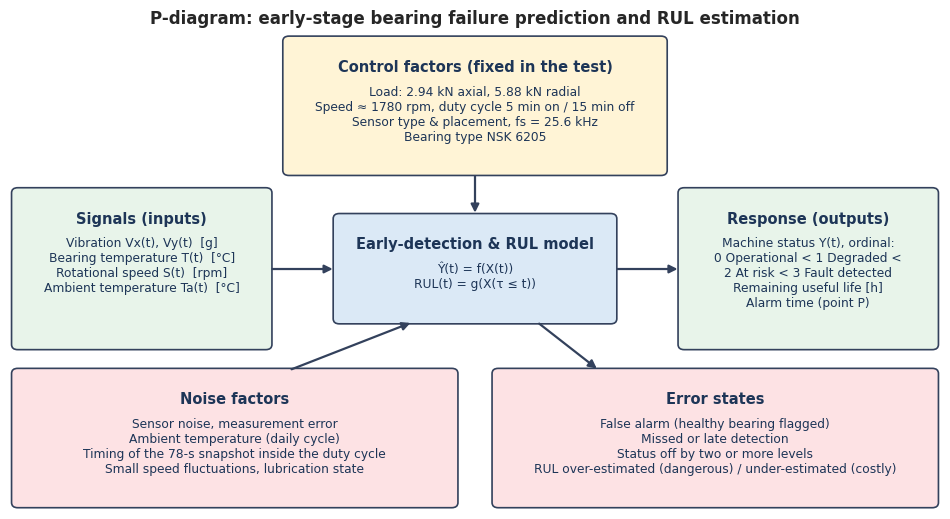

In [ ]:
def draw_p_diagram():
    """P-diagram of the bearing early-detection / RUL model (Lectures 7 and 16)."""
    fig, ax = plt.subplots(figsize=(12, 6.2))
    ax.set_xlim(0, 12); ax.set_ylim(0, 7.4); ax.axis("off")
    def box(x, y, w, h, title, lines, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="#33415c", lw=1.2))
        ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="top", fontsize=10.5, weight="bold", color="#1d3557")
        ax.text(x + w / 2, y + h - 0.68, "\n".join(lines), ha="center", va="top", fontsize=8.8, color="#1d3557")
    box(4.25, 2.95, 3.5, 1.55, "Early-detection & RUL model", ["Ŷ(t) = f(X(t))", "RUL(t) = g(X(τ ≤ t))"], "#dbe9f6")
    box(0.1, 2.55, 3.2, 2.35, "Signals (inputs)", ["Vibration Vx(t), Vy(t)  [g]", "Bearing temperature T(t)  [°C]",
                                                   "Rotational speed S(t)  [rpm]", "Ambient temperature Ta(t)  [°C]"], "#e8f4ea")
    box(8.7, 2.55, 3.2, 2.35, "Response (outputs)", ["Machine status Y(t), ordinal:", "0 Operational < 1 Degraded <",
                                                       "2 At risk < 3 Fault detected", "Remaining useful life [h]",
                                                       "Alarm time (point P)"], "#e8f4ea")
    box(3.6, 5.25, 4.8, 2.0, "Control factors (fixed in the test)", ["Load: 2.94 kN axial, 5.88 kN radial",
                                                                         "Speed ≈ 1780 rpm, duty cycle 5 min on / 15 min off",
                                                                         "Sensor type & placement, fs = 25.6 kHz", "Bearing type NSK 6205"], "#fff4d6")
    box(0.1, 0.1, 5.6, 2.0, "Noise factors", ["Sensor noise, measurement error", "Ambient temperature (daily cycle)",
                                              "Timing of the 78-s snapshot inside the duty cycle",
                                              "Small speed fluctuations, lubrication state"], "#fde2e4")
    box(6.3, 0.1, 5.6, 2.0, "Error states", ["False alarm (healthy bearing flagged)", "Missed or late detection",
                                              "Status off by two or more levels",
                                              "RUL over-estimated (dangerous) / under-estimated (costly)"], "#fde2e4")
    arrow = dict(arrowstyle="-|>", lw=1.6, color="#33415c")
    ax.annotate("", (4.2, 3.72), (3.35, 3.72), arrowprops=arrow)
    ax.annotate("", (8.65, 3.72), (7.8, 3.72), arrowprops=arrow)
    ax.annotate("", (6.0, 4.55), (6.0, 5.2), arrowprops=arrow)
    ax.annotate("", (5.2, 2.9), (3.6, 2.15), arrowprops=arrow)
    ax.annotate("", (7.6, 2.15), (6.8, 2.9), arrowprops=arrow)
    ax.set_title("P-diagram: early-stage bearing failure prediction and RUL estimation", fontsize=12)
    plt.show()

draw_p_diagram()

#### 1.2.4 Does machine learning make sense here?
Lecture 16 lists three requirements for data-driven ML:

* ✅ **A pattern exists.** Spalls create periodic impacts at characteristic *defect frequencies* and add friction heat.
* ✅ **No tractable closed-form model.** Crack initiation and growth depend on lubrication, contamination, load and
  material defects; bearing life is famously scattered (the rating life $L_{10}$ is the life that only 90 % of bearings reach).
* ⚠️ **Data is available, but scarce.** One bearing was run to failure. We get rich data about *one* life, which is
  enough to explore degradation and build a monitoring method, but it limits how far any model can be shown to generalize.
  We keep this limitation in view in every step.

#### 1.2.5 Bearing kinematics: where to look in the spectrum
A defect on a bearing component is struck at a rate fixed by the geometry and the shaft frequency $f_r$
(NSK 6205: $N = 9$ balls, ball diameter $d = 7.90$ mm, pitch diameter $D = 38.5$ mm, contact angle $\theta = 0°$):

$$BPFO = \tfrac{N}{2} f_r \left(1 - \tfrac{d}{D}\cos\theta\right), \quad
BPFI = \tfrac{N}{2} f_r \left(1 + \tfrac{d}{D}\cos\theta\right), \quad
BSF = \tfrac{D}{2d} f_r \left(1 - \left(\tfrac{d}{D}\cos\theta\right)^2\right), \quad
FTF = \tfrac{1}{2} f_r \left(1 - \tfrac{d}{D}\cos\theta\right)$$

In [ ]:
N_BALLS, BALL_D, PITCH_D, THETA = 9, 7.90, 38.5, 0.0      # NSK 6205 geometry [mm]
ratio = BALL_D / PITCH_D * np.cos(np.radians(THETA))
FAULT_COEF = {                                            # defect frequency / shaft frequency
    "FTF (cage)":        0.5 * (1 - ratio),
    "BSF (ball spin)":   PITCH_D / (2 * BALL_D) * (1 - ratio ** 2),
    "BPFO (outer race)": N_BALLS / 2 * (1 - ratio),
    "BPFI (inner race)": N_BALLS / 2 * (1 + ratio),
}
fr_nominal = 1780 / 60
kinematics = pd.DataFrame({"order (× shaft speed)": FAULT_COEF,
                           "frequency at 1780 rpm [Hz]": {k: v * fr_nominal for k, v in FAULT_COEF.items()}})
kinematics.loc["1× shaft speed"] = [1.0, fr_nominal]
kinematics.round(3)

,order (× shaft speed),frequency at 1780 rpm [Hz]
FTF (cage),0.397,11.79
BSF (ball spin),2.334,69.25
BPFO (outer race),3.577,106.1
BPFI (inner race),5.423,160.9
1× shaft speed,1,29.67


#### 1.2.6 Engineering sanity check: rated life versus observed life (ISO 281)
How "accelerated" was this test? The basic rating life of a ball bearing is $L_{10} = (C/P)^3$ million revolutions,
where $C$ is the dynamic load rating and $P$ the equivalent dynamic load $P = X F_r + Y F_a$ (Lecture 5 connects this
to the Weibull model of bearing life). Calculation factors for deep-groove ball bearings follow the ISO 281 table.

In [ ]:
Fr, Fa = 5.88, 2.94            # radial and axial load [kN] (600 kg and 300 kg)
C, C0, f0 = 14.0, 7.95, 14.0   # NSK 6205 dynamic / static load rating [kN] (article); geometry factor f0
rpm = 1780

# ISO 281 factors for deep-groove ball bearings (normal clearance)
f0FaC0 = np.array([0.172, 0.345, 0.689, 1.03, 1.38, 2.07, 3.45, 5.17, 6.89])
e_tab = np.array([0.19, 0.22, 0.26, 0.28, 0.30, 0.34, 0.38, 0.42, 0.44])
Y_tab = np.array([2.30, 1.99, 1.71, 1.55, 1.45, 1.31, 1.15, 1.04, 1.00])

def equivalent_load(Fr, Fa):
    """ISO 281 equivalent dynamic load P = X·Fr + Y·Fa of a deep-groove ball bearing; returns (P, X, Y, e)."""
    x_rel = f0 * Fa / C0
    e_, Y_ = np.interp(x_rel, f0FaC0, e_tab), np.interp(x_rel, f0FaC0, Y_tab)
    X_, Y_ = (0.56, Y_) if Fa / Fr > e_ else (1.0, 0.0)
    return X_ * Fr + Y_ * Fa, X_, Y_, e_

P, X_fac, Y_fac, e = equivalent_load(Fr, Fa)
P_TEST = P

def life_factor(load_fraction):
    """Life multiplier when the radial and axial loads are scaled by `load_fraction` (ISO 281: life ∝ P^-3)."""
    return (P_TEST / equivalent_load(load_fraction * Fr, load_fraction * Fa)[0]) ** 3

L10_rev = (C / P) ** 3 * 1e6
L10_h = L10_rev / (rpm * 60)

# the bearing turned 5 min out of every 20 min, so 128 test hours = 32 hours of rotation
test_hours, duty = 128, 5 / 20
observed_rev = test_hours * duty * 60 * rpm
life_check = pd.Series({
    "Fa/Fr": Fa / Fr, "e (ISO 281)": e, "X": X_fac, "Y": Y_fac, "equivalent load P [kN]": P, "C/P": C / P,
    "L10 [million revolutions]": L10_rev / 1e6, "L10 [hours of continuous rotation]": L10_h,
    "observed life [million revolutions]": observed_rev / 1e6, "observed / L10": observed_rev / L10_rev})
# probability that a bearing fails this early (Weibull life model, ISO 281 slope 10/9 for ball bearings)
beta = 10 / 9
life_check["P(failure before observed life)"] = 1 - 0.9 ** ((observed_rev / L10_rev) ** beta)
print("Life factor for the DCS load scenarios (ISO 281):",
      {name: round(float(life_factor(k)), 2) for name, k in LOAD_SCENARIOS.items()})
life_check.round(3).to_frame("value")

Life factor for the DCS load scenarios (ISO 281): {'High': 1.0, 'Medium': 2.12, 'Low': 6.06}


,value
Fa/Fr,0.5
e (ISO 281),0.42
X,0.56
Y,1.04
equivalent load P [kN],6.35
C/P,2.205
L10 [million revolutions],10.72
L10 [hours of continuous rotation],100.3
observed life [million revolutions],3.418
observed / L10,0.319


#### 🔎 Key findings – rated life vs observed life
* The equivalent load is **P ≈ 6.4 kN**, i.e. P ≈ 0.45·C. Bearing catalogues already call P > 0.1·C a *heavy* load, so this
  test is genuinely accelerated.
* ISO 281 still predicts **L10 ≈ 10.7 million revolutions** (≈ 100 h of continuous rotation). Because the shaft only turned
  5 minutes in every 20, the 128-hour test equals ≈ 32 h of rotation, or **3.4 million revolutions – about one third of L10**.
* Under the Weibull life model behind ISO 281, only **≈ 3 %** of bearings would fail this early. Either this specimen sits in the
  early tail of the life distribution, or factors outside the basic rating (lubrication, contamination, thermal cycling caused by
  the start–stop duty cycle) shortened its life. One specimen cannot tell which.
* **Implication:** population statistics could not have predicted *when this bearing* would fail. That is exactly the gap
  condition monitoring and RUL estimation are meant to close.

#### 1.2.7 Key challenges (from our proposal) and how this notebook addresses them

| Challenge (A2 proposal) | What it means here | How we handle it |
|---|---|---|
| **Early failure / start-up behaviour** | the first hours of a test (run-in) can look abnormal and would mislead a detector | inspect the start-up period explicitly and exclude it from the "healthy baseline" (Sections 3–7) |
| **Large data volume** | 129 files × 2 million rows × 4 channels ≈ 258 million rows (18.5 GB) | aggregation into 1-second condition indicators and hourly summaries (Section 2.5) |
| **Operating conditions** | speed, load and the room temperature affect the signals | estimate speed $S(t)$ from the spectrum; use the temperature *rise* above ambient (Section 2.7) |
| **Data noise** | sensor noise and snapshot timing blur trends | robust statistics, window-level averaging, smoothing of the health indicator (Sections 3–7) |

#### 1.2.8 What would count as success? (target performance, Lecture 16)
* **Early detection:** an alarm many hours before functional failure, with **no false alarms** during healthy operation.
* **Ordinal status classification:** no failed bearing reported as *Operational*, few errors of two or more levels, high recall
  of the non-operational statuses at a low false-warning rate, judged with ordinal metrics (quadratic-weighted kappa,
  mean absolute error in levels) rather than accuracy.
* **RUL:** small MAE / RMSE in hours, predictions inside a ±20 % accuracy cone (α–λ metric), and *conservative*
  rather than optimistic errors near the end of life.

#### 🔎 Section 1.2 takeaways
* We formulated three outputs: **detect degradation early** (where is P on the P–F curve?), report the **machine status on a
  four-level ordinal scale** (✅ Operational → 🔻 Degraded → ⚠️ At risk → ❌ Fault detected, each level tied to a maintenance
  action) and **estimate the remaining life**.
* Physics tells us where to look: periodic impacts at defect frequencies (BPFO ≈ 106 Hz, BPFI ≈ 161 Hz, BSF ≈ 69 Hz at
  1780 rpm), rising friction heat, and – because an induction motor slows under extra torque – a small drop in speed.
* The P-diagram lists the main threats to a good model: operating-condition noise (room temperature, duty-cycle timing) and the
  costly error states (missed or late detection, a status two or more levels off, optimistic RUL).
* Only one bearing was run to failure, so every result must be validated carefully in time order and read as evidence from one life.

---
### 1.3 The dataset (Step 2 of the 7-step procedure)
*"Collect data."* We use the public **Ball Bearing Vibration and Temperature Run-to-Failure Dataset** collected at
KAIST (Korea) and published with a Data-in-Brief article [1, 2].


#### 1.3.1 How the data was generated: an accelerated life test
| Item | Value |
|---|---|
| Bearing | NSK 6205 deep-groove ball bearing (steel), 9 balls |
| Load | 300 kg (2.94 kN) axial + 600 kg (5.88 kN) vertical/radial, applied with static loaders |
| Speed | 1770–1780 rpm (shaft frequency ≈ 29.6 Hz), three-phase induction motor |
| Duty cycle | 5 min running, 15 min rest, repeated until failure |
| Sensors | two PCB 352C34 accelerometers on the housing (*x* and *y*), K-type thermocouple on the bearing, ambient thermocouple |
| Acquisition | NI 9234 (vibration) and NI 9211 (temperature), **25.6 kHz** |
| Records | one **78.125 s** snapshot per hour → **129 CSV files** (hour 0 … hour 128), 2,000,000 rows × 4 columns each |
| Stop criterion | bearing temperature > 85 °C **and** vibration > 9 m/s² (≈ 0.92 g) |
| Post-mortem | spalls on the inner and outer races, a crack in the outer race and a damaged ball (microscope/X-ray) |

**Seen as a design of experiment (Lectures 7 and 16):** every control factor (load, speed, bearing type, sensors) was
held at one level and the test was run once ($r = 1$, $N = 1$ run). That is ideal for studying *how one bearing degrades*,
but it gives a single failure time: it cannot tell us how lives scatter between bearings or how load and speed change the result.

### 1.4 Load a raw-signal sample from URL (EDA brief, step 1)
The raw files are 18.5 GB, too large for a notebook or a GitHub repository. Our pipeline kept the **first second of
raw signal from 18 selected hours** so the original measurements can still be inspected directly.

In [ ]:
raw = load_csv("raw_excerpts.csv.gz")
print(f"Raw excerpt: {raw.shape[0]:,} rows x {raw.shape[1]} columns, "
      f"{raw['hour'].nunique()} hours x {raw.groupby('hour').size().iloc[0]:,} samples (1 s at 25.6 kHz)")
display(raw.head())
raw.info()

Raw excerpt: 460,800 rows x 6 columns, 18 hours x 25,600 samples (1 s at 25.6 kHz)


,hour,t_s,vib_x,vib_y,temp_bearing,temp_ambient
0,0,0,0.04858,-0.06382,41.61,24.82
1,0,3.906e-05,-0.1176,-0.3782,41.61,24.82
2,0,7.813e-05,-0.1258,-0.4478,41.61,24.82
3,0,0.0001172,0.1747,-0.2014,41.61,24.82
4,0,0.0001563,0.2987,-0.09386,41.61,24.82


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460800 entries, 0 to 460799
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   hour          460800 non-null  int64  
 1   t_s           460800 non-null  float64
 2   vib_x         460800 non-null  float64
 3   vib_y         460800 non-null  float64
 4   temp_bearing  460800 non-null  float64
 5   temp_ambient  460800 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 21.1 MB


In [ ]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
hour,4.608e+05,86,44.55,0,48,108,124,128
t_s,4.608e+05,0.5,0.2887,0,0.25,0.5,0.75,1
vib_x,4.608e+05,-0.01087,0.6937,-28.38,-0.2456,0.01097,0.2509,5.573
vib_y,4.608e+05,0.006288,0.8703,-10,-0.3997,0.01076,0.4192,6.682
temp_bearing,4.608e+05,54.15,22.04,34.32,41.19,43.86,58.77,99.19
temp_ambient,4.608e+05,25.85,0.6426,24.69,25.48,25.8,26.44,26.73


### 1.5 Load the aggregated tables (Gold layer)
`pipeline/build_features.py` read all 129 raw files and produced the tables below (Section 1.6 explains how).

In [8]:
import pandas as pd
from pathlib import Path

# Redefine fallback loading parameters in case setup was cleared
REPO_RAW = "https://raw.githubusercontent.com/alsulami412-arch/ISE518-Bearing-RUL/main/"
DATA_URL = REPO_RAW + "data/processed/"
LOCAL_DATA = Path("data/processed")

def load_csv_fallback(name, **kwargs):
    local = LOCAL_DATA / name
    return pd.read_csv(local if local.exists() else DATA_URL + name, **kwargs)

try:
    feat = load_csv_fallback("window_features.csv.gz")
    meta = load_csv_fallback("file_metadata.csv", parse_dates=["timestamp"])
    quality = load_csv_fallback("file_quality_report.csv")
    psd = load_csv_fallback("psd_hourly.csv.gz")
    envspec = load_csv_fallback("envelope_spectra_hourly.csv.gz")
    print("Successfully reloaded all analysis tables!")
except Exception as e:
    print(f"Error loading data: {e}")

Successfully reloaded all analysis tables!


In [13]:
import numpy as np
import pandas as pd

# Recreate the hourly table and all engineered features
FEATURES = [c for c in feat.columns if c not in ("hour", "window", "t_in_file_s", "shaft_hz")]
hourly = feat.groupby("hour")[FEATURES].mean()
hourly = hourly.join(meta.set_index("hour")[["timestamp", "rpm"]])

T_EOL = int(hourly.index.max())
RUN_IN = 8
BASE_HOURS = (RUN_IN, 100)

hourly["RUL_h"] = T_EOL - hourly.index
hourly["life_frac"] = hourly.index / T_EOL
hourly["test_day"] = "Day " + (hourly.index // 24 + 1).astype(str)
hourly["temp_rise"] = hourly["temp_bearing"] - hourly["temp_ambient"]
hourly["vel_rms"] = hourly[["x_vel_rms", "y_vel_rms"]].max(axis=1)

# Define robust z-score helper
def robust_z(s, base=BASE_HOURS):
    ref = s.loc[base[0]:base[1]]
    return (s - ref.median()) / (1.4826 * (ref - ref.median()).abs().median())

hourly["z_temp_rise"] = robust_z(hourly["temp_rise"])
hourly["z_speed_drop"] = -robust_z(hourly["rpm"])
hourly["friction_index"] = hourly[["z_temp_rise", "z_speed_drop"]].mean(axis=1)

def first_persistent(mask, start=RUN_IN, persist=2):
    m = mask.loc[start:].astype(int)
    run = m.groupby((m == 0).cumsum()).cumsum()
    hit = run[run >= persist]
    return int(hit.index[0]) - persist + 1 if len(hit) else None

P_HOUR = first_persistent(hourly["friction_index"] > 3)
stop = (hourly["temp_bearing"] > 85.0) & (hourly[["x_rms", "y_rms"]].max(axis=1) * 9.80665 > 9.0)
F_HOUR = int(stop.idxmax())

# Recreate stage labels
STAGE_ORDER = ["Run-in", "Healthy", "Degrading", "Failure"]
idx = hourly.index.to_numpy()
hourly["stage"] = pd.Categorical(np.select([idx < RUN_IN, idx < P_HOUR, idx < F_HOUR], STAGE_ORDER[:3], STAGE_ORDER[3]),
                                 categories=STAGE_ORDER, ordered=True)

# Recreate machine status
STATUS_ORDER = ["Operational", "Degraded", "At risk", "Fault detected"]
STATUS_CUTS = (12, 6, 3)
hourly["status_code"] = np.select([hourly["RUL_h"] <= STATUS_CUTS[2], hourly["RUL_h"] <= STATUS_CUTS[1], hourly["RUL_h"] <= STATUS_CUTS[0]], [3, 2, 1], default=0)
hourly["machine_status"] = pd.Categorical.from_codes(hourly["status_code"], categories=STATUS_ORDER, ordered=True)

print(f"Redefined hourly DataFrame with shape: {hourly.shape}")

Redefined hourly DataFrame with shape: (129, 73)


In [1]:
feat    = load_csv("window_features.csv.gz")                       # 1-second condition indicators
meta    = load_csv("file_metadata.csv", parse_dates=["timestamp"])  # one row per raw file
quality = load_csv("file_quality_report.csv")                       # data-quality checks per raw file
psd     = load_csv("psd_hourly.csv.gz")                             # power spectral density per hour
envspec = load_csv("envelope_spectra_hourly.csv.gz")                # envelope spectrum per hour

inventory = pd.DataFrame({name: {"rows": t.shape[0], "columns": t.shape[1],
                                 "memory [MB]": t.memory_usage(deep=True).sum() / 1e6}
                          for name, t in {"window features": feat, "file metadata": meta,
                                          "quality report": quality, "hourly PSD": psd,
                                          "envelope spectra": envspec}.items()}).T
display(inventory.round(2))
feat.head()

NameError: name 'load_csv' is not defined

In [ ]:
feat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10062 entries, 0 to 10061
Data columns (total 64 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   hour             10062 non-null  int64  
 1   window           10062 non-null  int64  
 2   t_in_file_s      10062 non-null  int64  
 3   x_mean           10062 non-null  float64
 4   x_rms            10062 non-null  float64
 5   x_peak           10062 non-null  float64
 6   x_p2p            10062 non-null  float64
 7   x_crest          10062 non-null  float64
 8   x_kurtosis       10062 non-null  float64
 9   x_skewness       10062 non-null  float64
 10  x_shape          10062 non-null  float64
 11  x_impulse        10062 non-null  float64
 12  x_clearance      10062 non-null  float64
 13  x_b1_rms         10062 non-null  float64
 14  x_b2_rms         10062 non-null  float64
 15  x_b3_rms         10062 non-null  float64
 16  x_b4_rms         10062 non-null  float64
 17  x_b5_rms    

In [ ]:
KEY = ["x_rms", "y_rms", "x_kurtosis", "y_kurtosis", "x_crest", "x_vel_rms", "x_b3_rms",
       "x_env_bpfo", "x_env_bpfi", "x_env_bsf", "temp_bearing", "temp_ambient"]
feat[KEY].describe().T

,count,mean,std,min,25%,50%,75%,max
x_rms,1.006e+04,0.362,0.2018,0.2222,0.3099,0.3321,0.3588,10.87
y_rms,1.006e+04,0.6315,0.1679,0.395,0.5329,0.6183,0.6867,1.895
x_kurtosis,1.006e+04,4.978,31.51,2.728,3.752,4.009,4.287,"2,081"
y_kurtosis,1.006e+04,5.202,5.295,2.835,4.086,5.231,5.979,299.6
x_crest,1.006e+04,5.211,1.942,3.436,4.765,5.04,5.354,61.63
x_vel_rms,1.006e+04,3.607,2.497,0.6499,1.935,3.218,4.478,87.16
x_b3_rms,1.006e+04,0.2642,0.03853,0.1624,0.2396,0.2671,0.2887,1.219
x_env_bpfo,1.006e+04,0.03554,0.01256,0.01118,0.02848,0.03435,0.04093,0.5187
x_env_bpfi,1.006e+04,0.02242,0.008732,0.006924,0.01791,0.02127,0.02514,0.3014
x_env_bsf,1.006e+04,0.05152,0.01394,0.02032,0.04317,0.0501,0.05776,0.3661


#### 🔎 Key findings – setup and data loading (EDA instruction 1)
* **Two levels of data were loaded with `pandas` from the project's GitHub URL:** a raw-signal excerpt (460,800 rows × 6 columns:
  18 hours × 1 s at 25.6 kHz, two vibration axes and two temperatures) and the aggregated window table (10,062 one-second windows ×
  64 condition indicators), plus file metadata, quality report and spectrum tables.
* **`df.info()`:** every column is numeric (`float64`, with `int64` time keys) and has no null values, so there is no text to convert
  and nothing missing to fill (confirmed in Section 2.2).
* **`df.describe()`:** the medians sit close to the quartiles, but the maxima are far away: x RMS median 0.33 g versus maximum
  10.9 g, x kurtosis 4.0 versus 2,081, bearing temperature 39.7 °C versus 108.8 °C. The distributions are strongly right-skewed,
  and the extreme values belong to the final hours of the failure, not to sensor errors (Section 2.3).
* **Implication:** robust statistics (median, MAD) and log scales are needed in the next steps; the mean and the standard deviation
  alone would be dominated by the last few hours.

### 1.6 From 18.5 GB to a few megabytes: the data pipeline
The pipeline follows the **Medallion architecture** of Lecture 8. It ran in the cloud with GitHub Actions
(`.github/workflows/build-features.yml`), and the same script can be re-run in Colab with the switch below.

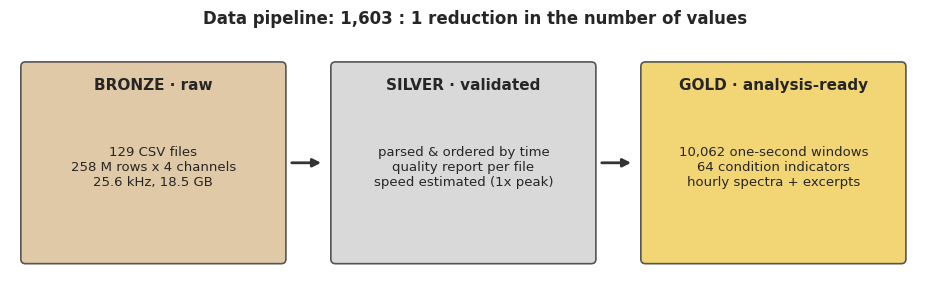

In [ ]:
n_raw_rows = int(quality["n_rows"].sum())
fig, ax = plt.subplots(figsize=(12, 3.3)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 3.3)
layers = [("BRONZE · raw", f"{len(quality)} CSV files\n{n_raw_rows/1e6:,.0f} M rows x 4 channels\n25.6 kHz, 18.5 GB", "#e0c9a6"),
          ("SILVER · validated", "parsed & ordered by time\nquality report per file\nspeed estimated (1x peak)", "#d9d9d9"),
          ("GOLD · analysis-ready", f"{len(feat):,} one-second windows\n{feat.shape[1]} condition indicators\nhourly spectra + excerpts", "#f2d675")]
for i, (title, body, color) in enumerate(layers):
    x0 = 0.2 + i * 4.0
    ax.add_patch(FancyBboxPatch((x0, 0.35), 3.3, 2.5, boxstyle="round,pad=0.06", fc=color, ec="#555", lw=1.2))
    ax.text(x0 + 1.65, 2.55, title, ha="center", weight="bold", fontsize=11)
    ax.text(x0 + 1.65, 1.55, body, ha="center", va="center", fontsize=9.5)
    if i < 2:
        ax.annotate("", (x0 + 3.85, 1.6), (x0 + 3.4, 1.6), arrowprops=dict(arrowstyle="-|>", lw=2, color="#333"))
ax.set_title(f"Data pipeline: {n_raw_rows * 4 / len(feat) / feat.shape[1]:,.0f} : 1 reduction in the number of values",
             fontsize=12)
plt.show()

RUN_FULL_PIPELINE = False    # True = rebuild data/processed from the raw Mendeley files (~20 min, ~25 GB disk)
if RUN_FULL_PIPELINE:
    import subprocess
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/alsulami412-arch/ISE518-Bearing-RUL.git", "repo"], check=True)
    subprocess.run(["python", "repo/pipeline/build_features.py", "--download", "--out", "data/processed"], check=True)

### 1.7 Data dictionary: what each condition indicator measures
Each 1-second window (25,600 samples) of each accelerometer axis (`x_…`, `y_…`) is summarized by:

| Family | Columns | Definition / meaning |
|---|---|---|
| Energy | `rms`, `p2p`, `peak` | $RMS=\sqrt{\tfrac1n\sum x_i^2}$ – overall vibration energy; peak and peak-to-peak amplitude |
| Shape (impulsiveness) | `kurtosis`, `crest`, `impulse`, `clearance`, `shape`, `skewness` | kurtosis $=E[(x-\mu)^4]/\sigma^4$ (3 for Gaussian noise), crest = peak/RMS; rise when sharp impacts appear |
| Frequency bands | `b1_rms` … `b5_rms` | RMS in 10–1k, 1–3k, 3–6k, 6–10k, 10–12 kHz; defects excite structural resonances (kHz range) |
| Spectral shape | `spec_centroid`, `spec_entropy` | centre of gravity and flatness of the spectrum |
| Severity (ISO 10816) | `vel_rms` | velocity RMS 10–1000 Hz in mm/s (acceleration integrated in the frequency domain) |
| Shaft components | `1x`, `2x` | amplitude at 1× and 2× running speed (unbalance, misalignment, looseness) |
| Bearing defects | `env_bpfo`, `env_bpfi`, `env_bsf`, `env_ftf` (+ `_snr`) | envelope-spectrum amplitude at the defect frequency and its first two harmonics; `_snr` = ratio to the envelope noise floor |
| Demodulated energy | `env_rms` | RMS of the envelope of the 1–11 kHz band |
| Temperatures | `temp_bearing`, `temp_ambient` | mean of the window [°C] |
| Speed | `shaft_hz` | shaft frequency estimated from the 1× spectral peak of each file |

### 1.8 The rotational speed $S(t)$
Our proposal lists the rotational speed $S(t)$ as an input. The dataset has no tachometer channel, so the pipeline
estimated it from the 1× peak of a high-resolution spectrum of each file (with sub-bin interpolation).

In [ ]:
meta["rpm"].describe().to_frame("rotational speed S(t) [rpm]").T.round(2)

,count,mean,std,min,25%,50%,75%,max
rotational speed S(t) [rpm],129,"1,791",2.85,"1,769","1,791","1,792","1,793","1,794"


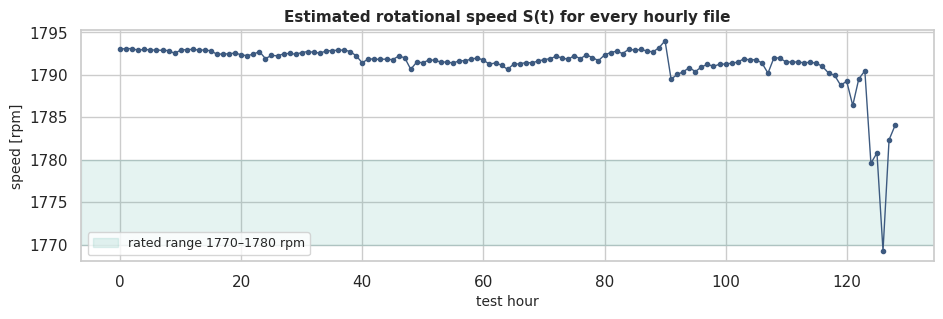

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(meta["hour"], meta["rpm"], marker="o", ms=3, lw=1, color="#3d5a80")
ax.axhspan(1770, 1780, color="#2a9d8f", alpha=0.12, label="rated range 1770–1780 rpm")
ax.set(xlabel="test hour", ylabel="speed [rpm]", title="Estimated rotational speed S(t) for every hourly file")
ax.legend(loc="lower left"); plt.show()

#### 🔎 Section 1 key findings
* **Structure.** Every raw file holds four numeric channels with no header: two vibration axes in *g* and two temperatures in °C.
  The excerpt alone already spans −28 g to +6 g and 34–99 °C, because it includes the failure hours.
* **Volume.** 129 files × 2 million rows were aggregated into **10,062 one-second windows × 64 condition indicators** – about a
  1,600 : 1 reduction in the number of values, while keeping the physics (spectra, envelope, statistics).
* **Speed $S(t)$.** The shaft turned at **1791 ± 3 rpm** (29.9 Hz), slightly above the nominal 1770–1780 rpm, which is plausible
  for a lightly loaded 4-pole motor running close to its 1800 rpm synchronous speed. Speed was very stable for 115 hours and then
  **dropped by up to ≈ 23 rpm in the last hours**: extra friction torque makes the motor slip more. Speed therefore becomes a useful
  input even though no tachometer was installed.

---
## 2️⃣ 2. Data Cleaning and Preparation
*"Massage your data."* We audit the quality of all raw measurements, clean what needs cleaning, and then aggregate and
engineer the variables used in the rest of the notebook.


### 2.1 Data-quality audit of every raw sample
The pipeline checked all 129 raw files (≈ 258 million rows) against the data-quality dimensions and imperfection aspects of
Lecture 8. The table summarizes the result; the figure shows the per-file checks over the life of the bearing.

In [ ]:
ts_gaps = meta["timestamp"].diff().dropna()
per_file = quality[["vib_x_missing", "temp_bearing_missing", "duplicate_rows"]].value_counts().head(3)
audit = pd.DataFrame([
    ["Completeness", "missing samples (4 channels, all files)",
     f"{int(quality.filter(like='_missing').sum().sum()):,} of {4 * n_raw_rows:,} ({quality.filter(like='_missing').sum().sum() / (4 * n_raw_rows):.4%})"],
    ["Uniqueness", "rows duplicated exactly (all 4 channels)", f"{int(quality['duplicate_rows'].sum()):,}"],
    ["Validity", "rows per file (78.125 s x 25.6 kHz = 2,000,000)",
     ", ".join(f"{n:,} rows in {c} files" for n, c in quality["n_rows"].value_counts().items())],
    ["Validity", "samples at the ±50 g sensor limit (clipping)", f"{int(quality.filter(like='_clipped').sum().sum()):,}"],
    ["Consistency", "consecutive files exactly 1 h apart", f"{int((ts_gaps == pd.Timedelta(hours=1)).sum())} / {len(ts_gaps)}"],
    ["Consistency", "column layout detected / mapping", f"{quality['n_columns_raw'].mode()[0]} columns, {quality['column_mapping'].mode()[0]}"],
    ["Accuracy", "longest run of identical consecutive values (stuck sensor)", f"{int(quality.filter(like='max_flat_run').max().max())} samples"],
    ["Outliers", "vibration samples with |z| > 5 within their file", f"{int(quality.filter(like='_z_gt5').sum().sum()):,}"],
], columns=["dimension (Lecture 8)", "check", "result"])
display(audit)
print("Most common per-file pattern (missing vibration samples, missing temperature samples, duplicated rows):")
per_file.to_frame("number of files")

,dimension (Lecture 8),check,result
0,Completeness,"missing samples (4 channels, all files)","33,874 of 1,032,000,516 (0.0033%)"
1,Uniqueness,rows duplicated exactly (all 4 channels),"6,253"
2,Validity,"rows per file (78.125 s x 25.6 kHz = 2,000,000)","2,000,001 rows in 129 files"
3,Validity,samples at the ±50 g sensor limit (clipping),4
4,Consistency,consecutive files exactly 1 h apart,124 / 128
5,Consistency,column layout detected / mapping,"4 columns, positional"
6,Accuracy,longest run of identical consecutive values (s...,2 samples
7,Outliers,vibration samples with |z| > 5 within their file,"96,899"


Most common per-file pattern (missing vibration samples, missing temperature samples, duplicated rows):


,,,number of files
vib_x_missing,temp_bearing_missing,duplicate_rows,
40,82,39,88
80,82,78,27
40,82,40,10


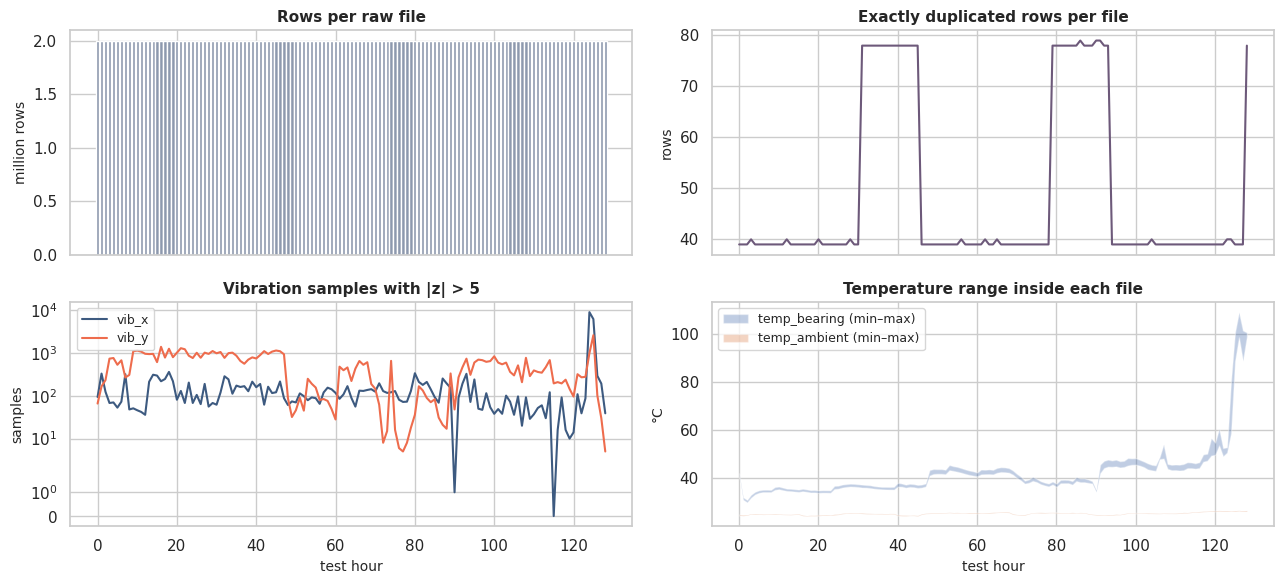

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
axes[0, 0].bar(quality["hour"], quality["n_rows"] / 1e6, color="#8d99ae")
axes[0, 0].set(ylabel="million rows", title="Rows per raw file")
axes[0, 1].plot(quality["hour"], quality["duplicate_rows"], color="#6d597a")
axes[0, 1].set(ylabel="rows", title="Exactly duplicated rows per file")
for c, ax in (("vib_x", axes[1, 0]), ("vib_y", axes[1, 0])):
    ax.plot(quality["hour"], quality[f"{c}_z_gt5"], label=c, color=AXIS_COLORS[c[-1]])
axes[1, 0].set(ylabel="samples", title="Vibration samples with |z| > 5", yscale="symlog"); axes[1, 0].legend()
for c in ("temp_bearing", "temp_ambient"):
    axes[1, 1].fill_between(quality["hour"], quality[f"{c}_min"], quality[f"{c}_max"], alpha=0.35, label=f"{c} (min–max)")
axes[1, 1].set(ylabel="°C", title="Temperature range inside each file"); axes[1, 1].legend()
for ax in axes[1]: ax.set_xlabel("test hour")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – data-quality audit (258 million raw rows)
* **Completeness:** 33,874 missing values out of ≈ 1.03 billion (**0.003 %**). The pattern is systematic: most files miss exactly
  40 vibration and 82 temperature samples, i.e. an acquisition artefact (incomplete rows at the edges of the logging buffer), not
  sensor dropouts. The pipeline filled them by linear interpolation.
* **Uniqueness:** 6,253 exactly duplicated rows, 39–79 per file, closely matching the number of empty rows in each file – the
  "duplicates" are essentially those empty rows. In a 25.6 kHz signal there is no record ID, so repeated values are not duplicate records.
* **Validity:** every file has 2,000,001 rows (one more than 78.125 s × 25.6 kHz). Only **4 samples** reached the ±50 g sensor limit,
  all during the violent event at hour 124: the sensor saturated once, in the failure itself.
* **Consistency:** 124 of 128 file gaps are exactly 1 h; the others differ by minutes (logger start-time drift), which is harmless at
  hourly resolution. No stuck sensor: the longest run of identical values is 2 samples.
* **Implication:** the raw data is of high quality. The only cleaning needed is interpolation of the few empty samples; the real
  challenges are volume and operating conditions, not dirt.

### 2.2 Missing values and duplicates in the analysis tables (EDA brief, step 2)

In [ ]:
print("Missing values per column (window features) - total:", int(feat.isnull().sum().sum()))
missing = feat.isnull().sum()
display(missing[missing > 0].to_frame("missing") if missing.any() else "no missing values in any column")
print("Duplicated rows (window features):", int(feat.duplicated().sum()))
print("Duplicated (hour, window) keys    :", int(feat.duplicated(subset=["hour", "window"]).sum()))
print("Missing values (raw excerpt)      :", int(raw.isnull().sum().sum()))
print("Duplicated rows (raw excerpt)     :", int(raw.duplicated().sum()))

Missing values per column (window features) - total: 0


'no missing values in any column'

Duplicated rows (window features): 0
Duplicated (hour, window) keys    : 0
Missing values (raw excerpt)      : 0
Duplicated rows (raw excerpt)     : 0


#### 🔎 Key findings – missing values and duplicates (EDA instruction 2)
* `df.isnull().sum()` finds **no missing values** in any column of the window table or the raw excerpt, and `df.duplicated()` finds
  **no duplicated rows** and no duplicated (hour, window) keys.
* No imputation or removal is therefore needed in the analysis tables. Section 2.4 still contains the handling step (median
  imputation and duplicate removal, applied only if any exist), so the notebook stays correct if the data change. In the raw
  signals, the pipeline filled the few empty samples by linear interpolation (Section 2.1).
* **Implication:** all 10,062 windows can be used in the analysis and in the models.

### 2.3 Outlier detection with `scipy.stats.zscore` (EDA brief, step 2)
A z-score flags a value more than three standard deviations from the column mean. In run-to-failure data the question is
not only *whether* there are outliers but *when* they occur.

1,302 of 10,062 windows (12.9%) have at least one |z| > 3


,x_spec_centroid,temp_bearing,shaft_hz,y_spec_centroid,y_2x,x_b1_rms,x_b2_rms,x_rms,y_b2_rms,y_rms,y_b1_rms,y_b4_rms
windows with |z| > 3,339,324,312,278,272,268,268,261,252,249,242,242


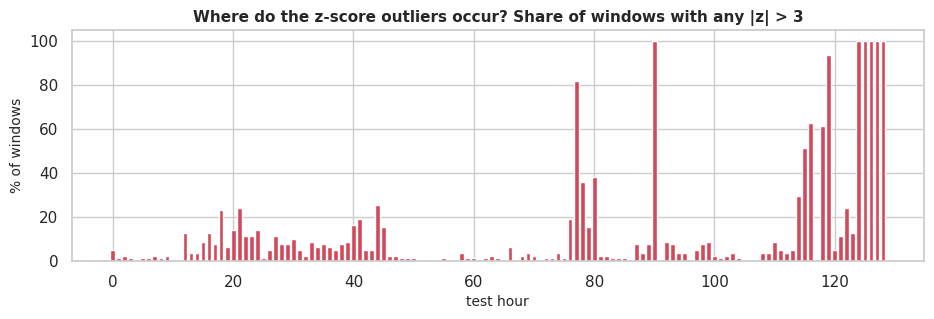

In [ ]:
NUM = [c for c in feat.columns if c not in ("hour", "window", "t_in_file_s")]
z = pd.DataFrame(np.abs(stats.zscore(feat[NUM], nan_policy="omit")), columns=NUM, index=feat.index)
out = (z > 3)
top = out.sum().sort_values(ascending=False)
print(f"{int(out.any(axis=1).sum()):,} of {len(feat):,} windows ({out.any(axis=1).mean():.1%}) have at least one |z| > 3")
display(top.head(12).to_frame("windows with |z| > 3").T)

share_by_hour = out.any(axis=1).groupby(feat["hour"]).mean()
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(share_by_hour.index, share_by_hour.values * 100, color="#d1495b")
ax.set(xlabel="test hour", ylabel="% of windows", title="Where do the z-score outliers occur? Share of windows with any |z| > 3")
plt.show()

In [ ]:
# Three outlier rules of Lecture 12 applied to the hourly mean RMS of the x-axis
s = feat.groupby("hour")["x_rms"].mean()
q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
mad = np.median(np.abs(s - s.median()))
rules = {"Z-score (|z| > 3)": np.abs(stats.zscore(s)) > 3,
         "IQR (outside 1.5·IQR)": (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr),
         "MAD (modified z > 3.5)": 0.6745 * np.abs(s - s.median()) / mad > 3.5}
rules = {k: np.asarray(v, dtype=bool) for k, v in rules.items()}
pd.DataFrame({name: {"hours flagged": int(f.sum()),
                     "first flagged hour": int(s.index[f].min()) if f.any() else None,
                     "robust to outliers?": "no" if name.startswith("Z") else "yes"}
              for name, f in rules.items()}).T

,hours flagged,first flagged hour,robust to outliers?
Z-score (|z| > 3),4,125,no
IQR (outside 1.5·IQR),5,124,yes
MAD (modified z > 3.5),5,124,yes


#### 🔎 Key findings – outliers
* 1,302 windows (12.9 %) contain at least one |z| > 3 value. The share jumps to almost 100 % in the final hours, while the scattered
  outliers earlier in life follow operating-condition changes (Section 5.1).
* On the hourly RMS, the z-score rule flags 4 hours (first at hour 125); the robust IQR and MAD rules flag 5 hours (first at hour
  124). All three agree: **the statistical outliers are the failure.**
* The z-score rule is the least sensitive because the extreme failure values inflate the mean and the standard deviation it relies
  on (Lecture 12). This is why the detection rules later in the notebook use the robust median/MAD version.
* **Implication:** in run-to-failure data, deleting outliers would delete the event we want to predict. We keep them, flag them, and
  use robust statistics and log scales instead.

### 2.4 Cleaning decisions

In [ ]:
# Missing values: impute with the column median (robust to outliers), only if any exist.
n_missing = int(feat[NUM].isnull().sum().sum())
if n_missing:
    feat[NUM] = feat[NUM].fillna(feat[NUM].median())
# Duplicates: drop exact duplicate records, only if any exist.
n_dup = int(feat.duplicated().sum())
if n_dup:
    feat = feat.drop_duplicates().reset_index(drop=True)
# Outliers: FLAG, do not delete - late-life extremes are the degradation signal we want to detect.
feat["outlier_flag"] = out.any(axis=1).to_numpy()
print(f"imputed values: {n_missing} | dropped duplicates: {n_dup} | windows flagged as outliers (kept): {feat['outlier_flag'].sum():,}")

imputed values: 0 | dropped duplicates: 0 | windows flagged as outliers (kept): 1,302


| Issue | Decision | Reason |
|---|---|---|
| Missing values | median imputation (window table), linear interpolation (raw signals, inside the pipeline) | keeps the time base of the signals intact |
| Duplicated values in raw signals | **kept** | repeated sample values are legitimate readings of a quantized signal; deleting rows would break the 25.6 kHz time axis |
| Duplicated records (window table) | drop if any | a record is a (hour, window) pair and must be unique |
| Outliers | **flagged, not removed** | they concentrate at the end of life (Section 2.3); removing them would delete the failure signature itself |

### 2.5 Aggregation: is it needed, and which type?
**Yes, aggregation is essential.** One hour of data holds 2 million samples per channel, and individual samples carry no
meaning on their own (a vibration sample is just a point on a wave). Information lives in *statistics of many samples*.
We therefore use two kinds of aggregation (Lecture 16: *data aggregation*; Lecture 12: *time-series summarization*):

1. **Temporal window aggregation (feature extraction).** Each 78-s record is cut into 78 one-second windows and every
   window is summarized by statistical aggregates (RMS, peak, kurtosis, …) and spectral aggregates (band energies,
   envelope amplitudes at the defect frequencies). This is **not additive** aggregation (summing vibration samples would
   cancel positive and negative values); we use non-additive statistics such as RMS, maxima and moments.
2. **Time-interval summarization.** The windows of each hour are summarized again with `groupby` (mean, median, max),
   which gives one row per test hour for trend and time-series analysis.

The cell below repeats the first aggregation by hand on one raw second, to show what the pipeline computed.

In [ ]:
def condition_indicators(x):
    """Statistical aggregation of one raw window (DC removed)."""
    x = x - x.mean()
    rms, peak = np.sqrt(np.mean(x ** 2)), np.max(np.abs(x))
    return {"RMS [g]": rms, "peak [g]": peak, "crest factor": peak / rms,
            "kurtosis": stats.kurtosis(x, fisher=False), "skewness": stats.skew(x)}

h_first, h_last = int(raw["hour"].min()), int(raw["hour"].max())
manual = pd.DataFrame({f"hour {h} (by hand)": condition_indicators(raw.loc[raw["hour"] == h, "vib_x"].to_numpy())
                       for h in (h_first, h_last)})
pipe = feat[(feat["window"] == 0) & feat["hour"].isin([h_first, h_last])].set_index("hour")
manual[f"hour {h_first} (pipeline)"] = pipe.loc[h_first, ["x_rms", "x_peak", "x_crest", "x_kurtosis", "x_skewness"]].to_numpy()
manual[f"hour {h_last} (pipeline)"] = pipe.loc[h_last, ["x_rms", "x_peak", "x_crest", "x_kurtosis", "x_skewness"]].to_numpy()
manual.round(4)

,hour 0 (by hand),hour 128 (by hand),hour 0 (pipeline),hour 128 (pipeline)
RMS [g],0.3722,1.411,0.3722,1.411
peak [g],1.884,5.674,1.884,5.674
crest factor,5.064,4.023,5.064,4.023
kurtosis,4.022,3.08,4.022,3.08
skewness,-0.2373,-0.0061,-0.2373,-0.006143


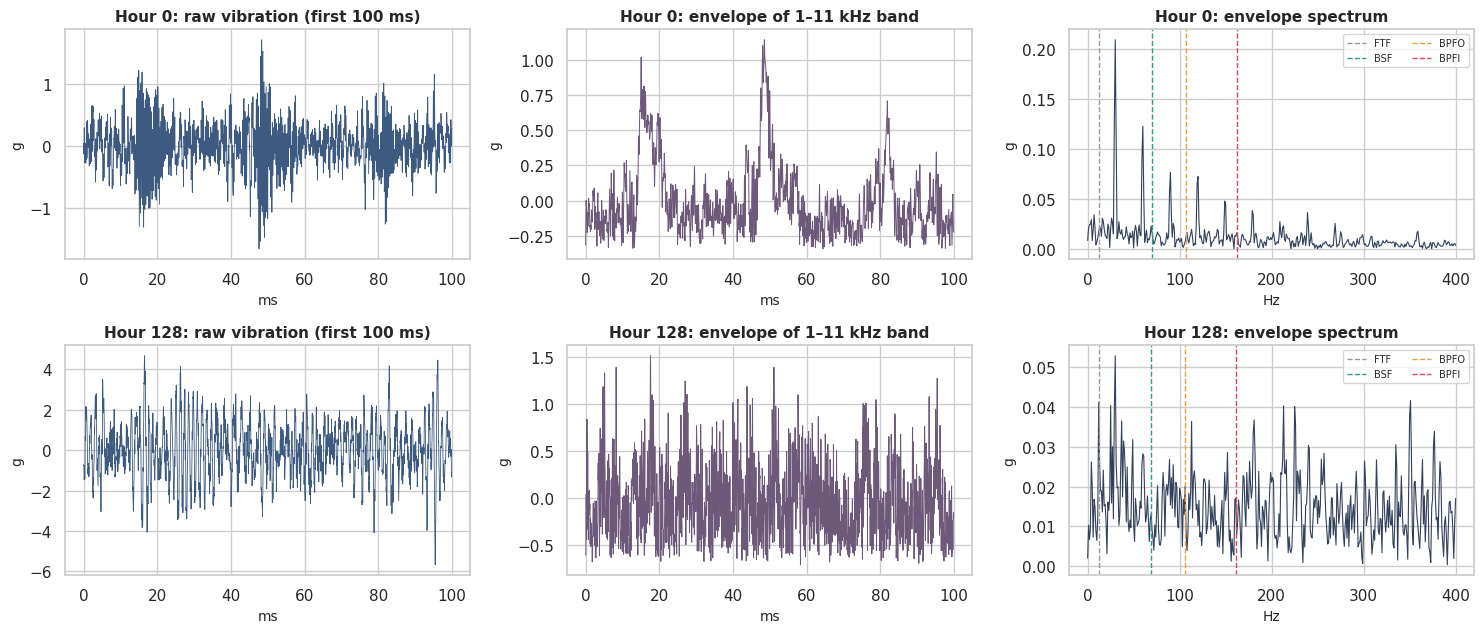

In [ ]:
def envelope_spectrum(x, band=(1000, 11000)):
    """Band-pass -> Hilbert envelope -> amplitude spectrum (the demodulation used for bearing defects)."""
    sos = signal.butter(4, band, btype="bandpass", fs=FS, output="sos")
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    env = env - env.mean()
    w = np.hanning(len(env))
    amp = np.abs(np.fft.rfft(env * w)) * 2 / w.sum()
    return np.fft.rfftfreq(len(env), 1 / FS), amp, env

fr_by_hour = meta.set_index("hour")["shaft_hz"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for row, h in enumerate((h_first, h_last)):
    x = raw.loc[raw["hour"] == h, "vib_x"].to_numpy()
    t = np.arange(len(x)) / FS
    f, amp, env = envelope_spectrum(x)
    axes[row, 0].plot(t[:2560] * 1000, x[:2560], lw=0.6, color=AXIS_COLORS["x"])
    axes[row, 0].set(title=f"Hour {h}: raw vibration (first 100 ms)", xlabel="ms", ylabel="g")
    axes[row, 1].plot(t[:2560] * 1000, env[:2560], lw=0.7, color="#6d597a")
    axes[row, 1].set(title=f"Hour {h}: envelope of 1–11 kHz band", xlabel="ms", ylabel="g")
    m = f <= 400
    axes[row, 2].plot(f[m], amp[m], lw=0.8, color="#33415c")
    fr = fr_by_hour.get(h, fr_nominal)
    for (name, coef), col in zip(FAULT_COEF.items(), ["#999", "#2a9d8f", "#e9a03b", "#d1495b"]):
        axes[row, 2].axvline(coef * fr, ls="--", lw=1, color=col, label=name.split()[0])
    axes[row, 2].set(title=f"Hour {h}: envelope spectrum", xlabel="Hz", ylabel="g")
    axes[row, 2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

#### 🔎 Key findings – aggregation
* The hand-computed indicators match the pipeline values exactly, which validates the 18.5 GB → 10 k-window aggregation.
* **Hour 0:** the raw signal shows bursts about every 33 ms, i.e. **once per shaft revolution** (29.9 Hz). The envelope spectrum
  therefore peaks at 1×, 2× and 3× shaft speed, not at the bearing defect frequencies. Something shaft-synchronous (such as the
  loading arrangement or a small misalignment) excites the housing from the very first hour.
* **Hour 128:** RMS is 3.8 times higher (1.41 g), but kurtosis is ≈ 3 and the crest factor is ≈ 4, the values of Gaussian noise.
  Late-stage damage spread over the raceways and a ball produces **broadband, non-impulsive** vibration, so impulsiveness
  indicators (kurtosis, crest) are *not* reliable late-stage alarms on this bearing.
* **Implication:** aggregation must keep several families of statistics (energy, shape, spectral). No single aggregate tells the
  whole story.

### 2.6 Time-interval summarization: one row per test hour

In [ ]:
FEATURES = [c for c in NUM if c not in ("shaft_hz",)]
hourly = feat.groupby("hour")[FEATURES].mean()                 # mean of the 78 windows of each hour
hourly_spread = feat.groupby("hour")[["x_rms", "x_kurtosis", "temp_bearing"]].agg(["median", "std", "max"])
hourly = hourly.join(meta.set_index("hour")[["timestamp", "rpm"]])
print("hourly table:", hourly.shape)
hourly_spread.head()

hourly table: (129, 62)


x_rms                 x_kurtosis              temp_bearing             
     median      std    max     median    std   max       median    std   max
hour                                                                         
0    0.3697 0.007603 0.3917      3.843  0.138 4.156        41.81 0.1294 42.03
1    0.3642  0.01248  0.399      4.292 0.2161 4.719        31.69 0.2762 32.14
2    0.3615   0.0129 0.4083       3.96 0.1942  4.44        30.63 0.2836 31.07
3    0.3849 0.007636 0.4053      4.004 0.1617 4.412        32.67  0.342 33.21
4    0.3724  0.01249 0.4349      3.945 0.1915 4.426        33.94 0.3052 34.43

### 2.7 Feature engineering and labels
New variables used later (Lectures 9–10):

* **Temporal features** – timestamp, test day, day/night, life fraction and the **RUL target**. The dataset documents the
  end of life at the last record (hour 128), so $RUL(t) = 128 - t$.
* **Temperature rise** $\Delta T = T_{bearing} - T_{ambient}$ – removes the room-temperature effect (an operating-condition
  challenge from our proposal).
* **Friction index** – a physics-informed feature. A damaged bearing adds friction torque, which (i) heats the bearing and
  (ii) slows the induction motor (more slip). We combine the robust z-scores of the temperature rise and of the speed drop,
  both measured against the healthy baseline.
* **Binning** (Lecture 10) – bearing-temperature band and ISO 10816-1 vibration-severity zone (class I: 0.71 / 1.8 / 4.5 mm/s).
* **Health stage** – rule-based expert labels that *describe* what happened physically: *Run-in* (start-up thermal transient),
  *Healthy*, *Degrading* (from the first sustained friction rise, point P) and *Failure* (from the first hour that meets the
  dataset's stop criterion: T > 85 °C **and** vibration > 9 m/s²). Used to colour the EDA.
* **Machine status $Y(t)$** – the **ordinal target** the models must *predict* (Section 1.2.2): ✅ Operational, 🔻 Degraded,
  ⚠️ At risk, ❌ Fault detected, label-encoded as 0 < 1 < 2 < 3 and stored as an *ordered* pandas `Categorical`.
  It is set from the remaining life only (thresholds 12 / 6 / 3 h), so it does not depend on any input feature.

In [ ]:
T_EOL = int(hourly.index.max())             # end of life = last record (hour 128, dataset documentation)
RUN_IN = 8                                  # hours 0-7: start-up thermal transient (Section 2, temperature at the start)
BASE_HOURS = (RUN_IN, 100)                  # healthy baseline: after run-in, covering all normal operating regimes

hourly["RUL_h"] = T_EOL - hourly.index
hourly["life_frac"] = hourly.index / T_EOL
hourly["test_day"] = "Day " + (hourly.index // 24 + 1).astype(str)
hourly["time_of_day"] = np.where(hourly["timestamp"].dt.hour.between(6, 17), "Day 06–18", "Night 18–06")
hourly["temp_rise"] = hourly["temp_bearing"] - hourly["temp_ambient"]
hourly["vel_rms"] = hourly[["x_vel_rms", "y_vel_rms"]].max(axis=1)
hourly["temp_band"] = pd.cut(hourly["temp_bearing"], [-np.inf, 40, 60, 85, np.inf],
                             labels=["< 40 °C", "40–60 °C", "60–85 °C", "> 85 °C"])
hourly["iso_zone"] = pd.cut(hourly["vel_rms"], [0, 0.71, 1.8, 4.5, np.inf],
                            labels=["A good", "B acceptable", "C unsatisfactory", "D unacceptable"])

def robust_z(s, base=BASE_HOURS):
    """(x - median) / (1.4826 * MAD), statistics taken from the healthy baseline hours."""
    ref = s.loc[base[0]:base[1]]
    return (s - ref.median()) / (1.4826 * (ref - ref.median()).abs().median())

hourly["z_temp_rise"] = robust_z(hourly["temp_rise"])
hourly["z_speed_drop"] = -robust_z(hourly["rpm"])
hourly["friction_index"] = hourly[["z_temp_rise", "z_speed_drop"]].mean(axis=1)

def first_persistent(mask, start=RUN_IN, persist=2):
    """First hour >= start from which `mask` is True for `persist` consecutive hours."""
    m = mask.loc[start:].astype(int)
    run = m.groupby((m == 0).cumsum()).cumsum()
    hit = run[run >= persist]
    return int(hit.index[0]) - persist + 1 if len(hit) else None

P_HOUR = first_persistent(hourly["friction_index"] > 3)                          # point P (potential failure)
stop = (hourly["temp_bearing"] > FAIL_TEMP_C) & (hourly[["x_rms", "y_rms"]].max(axis=1) * G > FAIL_VIB_MS2)
F_HOUR = int(stop.idxmax())                                                       # point F (stop criterion met)
idx = hourly.index.to_numpy()
hourly["stage"] = pd.Categorical(np.select([idx < RUN_IN, idx < P_HOUR, idx < F_HOUR], STAGE_ORDER[:3], STAGE_ORDER[3]),
                                 categories=STAGE_ORDER, ordered=True)
stage_start = hourly.reset_index().groupby("stage", observed=False)["hour"].min()

# ordinal machine status Y(t): label (ordinal) encoding 0 < 1 < 2 < 3 from the remaining life (thresholds of Section 1.2)
assert T_EOL - F_HOUR == STATUS_CUTS[2], "the 'Fault detected' threshold should coincide with the stop criterion"
rul_h = hourly["RUL_h"]
hourly["status_code"] = np.select([rul_h <= STATUS_CUTS[2], rul_h <= STATUS_CUTS[1], rul_h <= STATUS_CUTS[0]], [3, 2, 1], default=0)
hourly["machine_status"] = pd.Categorical.from_codes(hourly["status_code"], categories=STATUS_ORDER, ordered=True)

# bring the hourly labels to the window table
cols_to_map = ["RUL_h", "life_frac", "test_day", "time_of_day", "temp_band", "iso_zone", "stage", "machine_status",
               "status_code", "timestamp", "friction_index", "rpm"]
feat = feat.drop(columns=[c for c in cols_to_map if c in feat.columns]).merge(hourly[cols_to_map], left_on="hour", right_index=True)
feat["temp_rise"] = feat["temp_bearing"] - feat["temp_ambient"]
print(f"P (sustained friction rise) = hour {P_HOUR} | F (stop criterion first met) = hour {F_HOUR} | end of life = hour {T_EOL}")
print("Stage start hours:", stage_start.to_dict())
print("Machine status - first hour of each level:",
      hourly.reset_index().groupby("machine_status", observed=False)["hour"].min().to_dict())
print("dtype of the target:", hourly["machine_status"].dtype, "| ordered:", hourly["machine_status"].cat.ordered)
hourly[["timestamp", "test_day", "x_rms", "temp_rise", "rpm", "friction_index", "RUL_h", "temp_band", "iso_zone", "stage",
        "machine_status", "status_code"]].iloc[[0, 4, 8, 24, 48, 72, 96, 112, P_HOUR - 2, P_HOUR, F_HOUR - 1, F_HOUR, T_EOL]]

P (sustained friction rise) = hour 119 | F (stop criterion first met) = hour 125 | end of life = hour 128
Stage start hours: {'Run-in': 0, 'Healthy': 8, 'Degrading': 119, 'Failure': 125}
Machine status - first hour of each level: {'Operational': 0, 'Degraded': 116, 'At risk': 122, 'Fault detected': 125}
dtype of the target: category | ordered: True


,timestamp,test_day,x_rms,temp_rise,rpm,friction_index,RUL_h,temp_band,iso_zone,stage,machine_status,status_code
hour,,,,,,,,,,,,
0,2022-06-20 17:00:00,Day 1,0.371,16.98,"1,793",0.1077,128,40–60 °C,C unsatisfactory,Run-in,Operational,0
4,2022-06-20 21:00:00,Day 1,0.3757,8.65,"1,793",-1.176,124,< 40 °C,C unsatisfactory,Run-in,Operational,0
8,2022-06-21 01:00:00,Day 1,0.3735,9.568,"1,793",-0.9479,120,< 40 °C,C unsatisfactory,Healthy,Operational,0
24,2022-06-21 17:00:00,Day 2,0.3642,11.29,"1,792",-0.1388,104,< 40 °C,D unacceptable,Healthy,Operational,0
48,2022-06-22 17:01:00,Day 3,0.3122,16.79,"1,791",1.433,80,40–60 °C,D unacceptable,Healthy,Operational,0
72,2022-06-23 17:01:00,Day 4,0.3372,13.58,"1,792",0.06216,56,< 40 °C,D unacceptable,Healthy,Operational,0
96,2022-06-24 17:02:00,Day 5,0.3052,20.89,"1,791",1.914,32,40–60 °C,D unacceptable,Healthy,Operational,0
112,2022-06-25 09:02:00,Day 5,0.2812,18.96,"1,792",1.283,16,40–60 °C,D unacceptable,Healthy,Operational,0
117,2022-06-25 14:02:00,Day 5,0.2778,22.18,"1,790",2.52,11,40–60 °C,D unacceptable,Healthy,Degraded,1


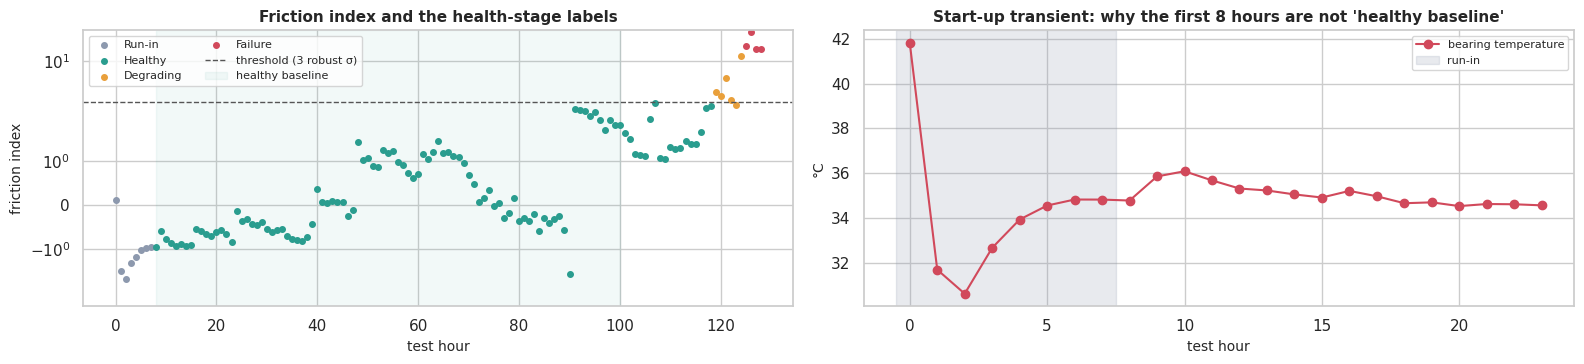

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for st, col in STAGE_COLORS.items():
    seg = hourly[hourly["stage"] == st]
    axes[0].scatter(seg.index, seg["friction_index"], color=col, s=16, label=st)
axes[0].axhline(3, ls="--", color="#555", lw=1, label="threshold (3 robust σ)")
axes[0].axvspan(*BASE_HOURS, color="#2a9d8f", alpha=0.06, label="healthy baseline")
axes[0].set_yscale("symlog"); axes[0].set(xlabel="test hour", ylabel="friction index", title="Friction index and the health-stage labels")
axes[0].legend(fontsize=8, ncol=2)
axes[1].plot(hourly.index[:24], hourly["temp_bearing"].iloc[:24], "o-", color="#d1495b", label="bearing temperature")
axes[1].axvspan(-0.5, RUN_IN - 0.5, color=STAGE_COLORS["Run-in"], alpha=0.2, label="run-in")
axes[1].set(xlabel="test hour", ylabel="°C", title="Start-up transient: why the first 8 hours are not 'healthy baseline'")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Feature vector → label: one record per machine status
The same view as the motor example of Lecture 9 (*features → label / machine status*), built from our data: one hourly record
for each level of $Y(t)$, with the vibration expressed as an ISO 10816 velocity in mm/s. The *condition summary* is generated
from the numbers in the row (deviation from the healthy baseline and the stop-criterion limits), like a monitoring log entry.

In [ ]:
base_med = hourly.loc[BASE_HOURS[0]:BASE_HOURS[1], ["rpm", "x_rms"]].median()

def condition_summary(r):
    """A short, log-style description of one hourly record, generated from its values."""
    notes = [f"ΔT {r['temp_rise']:.1f} °C ({r['z_temp_rise']:+.1f} σ vs baseline)",
             f"speed {r['rpm'] - base_med['rpm']:+.0f} rpm", f"RMS × {r['x_rms'] / base_med['x_rms']:.1f}"]
    if r["temp_bearing"] > FAIL_TEMP_C:
        notes.append("T > 85 °C limit")
    if max(r["x_rms"], r["y_rms"]) * G > FAIL_VIB_MS2:
        notes.append("vibration > 9 m/s² limit")
    return "; ".join(notes)

after_runin = hourly.loc[RUN_IN:].reset_index()
example_hours = after_runin.groupby("machine_status", observed=False)["hour"].median().astype(int)
examples = hourly.loc[example_hours.to_numpy()].copy()
feature_label = pd.DataFrame({
    "bearing temperature [°C]": examples["temp_bearing"].round(1),
    "vibration velocity RMS [mm/s]": examples["vel_rms"].round(2),
    "speed [rpm]": examples["rpm"].round(0),
    "condition summary (generated)": examples.apply(condition_summary, axis=1),
    "machine status Y(t)": [f"{STATUS_ICON[s]} {s} ({c})" for s, c in zip(examples["machine_status"], examples["status_code"])],
    "recommended action": [STATUS_ACTION[s] for s in examples["machine_status"]]}, index=examples.index.rename("hour"))
with pd.option_context("display.max_colwidth", None):     # show the full condition summary
    display(feature_label)

,bearing temperature [°C],vibration velocity RMS [mm/s],speed [rpm],condition summary (generated),machine status Y(t),recommended action
hour,,,,,,
61,42.7,6.52,"1,791",ΔT 17.1 °C (+1.4 σ vs baseline); speed -1 rpm; RMS × 1.0,✅ Operational (0),any load up to high; continue normal monitoring
118,48.8,6.51,"1,790",ΔT 22.4 °C (+3.0 σ vs baseline); speed -2 rpm; RMS × 0.9,🔻 Degraded (1),limit to medium load; plan the replacement
123,51.6,5.28,"1,790",ΔT 25.0 °C (+3.8 σ vs baseline); speed -2 rpm; RMS × 0.8,⚠️ At risk (2),limit to low load; replace at the next opportunity
126,103.1,8.16,"1,769",ΔT 76.4 °C (+19.8 σ vs baseline); speed -23 rpm; RMS × 3.6; T > 85 °C limit; vibration > 9 m/s² limit,❌ Fault detected (3),STOP the machine and replace the bearing


### 2.8 Splitting and scaling strategy (decided now, used in Section 7)
* **No random splits.** Windows of the same hour are nearly identical, so a random train/test split would leak future
  information into training and give over-optimistic scores. All model validation uses **time-ordered blocks**.
* **Scaling is fitted on the healthy baseline only** (z-score normalization, Lecture 10), so that the test data cannot
  influence the scaler.

#### 🔎 Section 2 key findings
* Data quality is excellent; cleaning was limited to interpolating 0.003 % empty samples. Outliers were **kept and flagged**.
* Aggregation (1-s windows → hourly summaries) answers the "large data volume" challenge of our proposal.
* Two engineered variables matter most later: the **temperature rise** ΔT (removes room temperature) and the **friction index**
  (temperature rise + speed drop, as robust z-scores against the healthy baseline).
* **Labels:** run-in = hours 0–7 (the bearing started warm at 41.8 °C, dropped to 30.6 °C and settled by hour 8 – the start-up effect
  our proposal warned about); **P = hour 119** (sustained friction rise); **F = hour 125** (stop criterion met: 95 °C and 9.6 m/s²);
  end of life = hour 128.
* **Ordinal target:** the machine status is label-encoded 0–3 from the remaining life and stored as an ordered `Categorical`:
  ✅ Operational until hour 115, 🔻 Degraded 116–121, ⚠️ At risk 122–124, ❌ Fault detected 125–128. The 3-h threshold coincides with
  the stop criterion (F = hour 125), and the generated feature → label table shows how the records of each level differ.
* The healthy baseline (hours 8–100) deliberately spans several operating regimes, so that normal variability is not mistaken for damage.

---
## 3️⃣ 3. Univariate Analysis
*"Know your enemy."* Univariate and multivariate analyses tell us about the separability, linearity and monotonicity of the
data (Lecture 16) – exactly what the models in Section 7 will rely on. We analyse two granularities:
the **window table** (10,062 one-second windows, good for distributions) and the **hourly table** (129 rows, good for trends).

> (dashboard-style figure).

In [ ]:
EDA = ["x_rms", "y_rms", "x_kurtosis", "y_kurtosis", "x_crest", "x_b3_rms", "x_vel_rms",
       "x_env_bpfo", "x_env_bpfi", "x_env_bsf", "x_env_rms", "temp_bearing", "temp_ambient", "temp_rise"]
_desc = {"rms": ("RMS", "g"), "peak": ("peak", "g"), "p2p": ("peak-to-peak", "g"), "crest": ("crest factor", ""),
         "kurtosis": ("kurtosis", ""), "skewness": ("skewness", ""), "shape": ("shape factor", ""),
         "impulse": ("impulse factor", ""), "clearance": ("clearance factor", ""), "b1_rms": ("10 Hz–1 kHz band RMS", "g"),
         "b2_rms": ("1–3 kHz band RMS", "g"), "b3_rms": ("3–6 kHz band RMS", "g"), "b4_rms": ("6–10 kHz band RMS", "g"),
         "b5_rms": ("10–12 kHz band RMS", "g"), "spec_centroid": ("spectral centroid", "Hz"),
         "spec_entropy": ("spectral entropy", ""), "vel_rms": ("velocity RMS", "mm/s"), "1x": ("1× amplitude", "g"),
         "2x": ("2× amplitude", "g"), "env_rms": ("envelope RMS", "g"), "mean": ("mean (DC)", "g")}
for k in ("ftf", "bpfo", "bpfi", "bsf"):
    _desc[f"env_{k}"], _desc[f"env_{k}_snr"] = (f"envelope {k.upper()}", "g"), (f"envelope {k.upper()} SNR", "")
LABELS = {f"{a}_{k}": f"{name} {a}" + (f" [{u}]" if u else "") for a in "xy" for k, (name, u) in _desc.items()}
LABELS.update({"temp_bearing": "bearing temperature [°C]", "temp_ambient": "ambient temperature [°C]",
               "temp_rise": "temperature rise ΔT [°C]", "rpm": "speed S(t) [rpm]", "hour": "test hour", "RUL_h": "RUL [h]",
               "z_temp_rise": "temperature rise (robust z)", "z_speed_drop": "speed drop (robust z)"})

def shade_stages(ax, alpha=0.10, label=True):
    """Shade the health stages on a time axis (hours)."""
    edges = list(stage_start.dropna().astype(int)) + [T_EOL + 1]
    for (stage, start), end in zip(stage_start.dropna().items(), edges[1:]):
        ax.axvspan(start - 0.5, end - 0.5, color=STAGE_COLORS[stage], alpha=alpha, lw=0,
                   label=stage if label else None)

### 3.1 Univariate analysis – numerical variables (EDA brief, step 3)
Summary statistics with `pandas` and `scipy.stats`: central tendency, spread and shape (Lecture 11), plus a normality test.

In [ ]:
num_summary = pd.DataFrame({
    "mean": feat[EDA].mean(), "median": feat[EDA].median(), "std": feat[EDA].std(),
    "min": feat[EDA].min(), "max": feat[EDA].max(),
    "skewness": feat[EDA].apply(lambda c: stats.skew(c)),
    "excess kurtosis": feat[EDA].apply(lambda c: stats.kurtosis(c)),
    "max / median": feat[EDA].max() / feat[EDA].median(),
    "normality p (D'Agostino)": feat[EDA].apply(lambda c: stats.normaltest(c).pvalue)})
num_summary.rename(index=LABELS)

,mean,median,std,min,max,skewness,excess kurtosis,max / median,normality p (D'Agostino)
RMS x [g],0.362,0.3321,0.2018,0.2222,10.87,17.59,749,32.74,0
RMS y [g],0.6315,0.6183,0.1679,0.395,1.895,3.459,17.02,3.064,0
kurtosis x,4.978,4.009,31.51,2.728,"2,081",49.94,"2,796",519,0
kurtosis y,5.202,5.231,5.295,2.835,299.6,42.98,"2,144",57.29,0
crest factor x,5.211,5.04,1.942,3.436,61.63,16.97,373.1,12.23,0
3–6 kHz band RMS x [g],0.2642,0.2671,0.03853,0.1624,1.219,2.472,48.64,4.564,0
velocity RMS x [mm/s],3.607,3.218,2.497,0.6499,87.16,7.784,195.8,27.08,0
envelope BPFO x [g],0.03554,0.03435,0.01256,0.01118,0.5187,9.043,261.8,15.1,0
envelope BPFI x [g],0.02242,0.02127,0.008732,0.006924,0.3014,7.998,162.5,14.17,0
envelope BSF x [g],0.05152,0.0501,0.01394,0.02032,0.3661,5.022,80.51,7.306,0


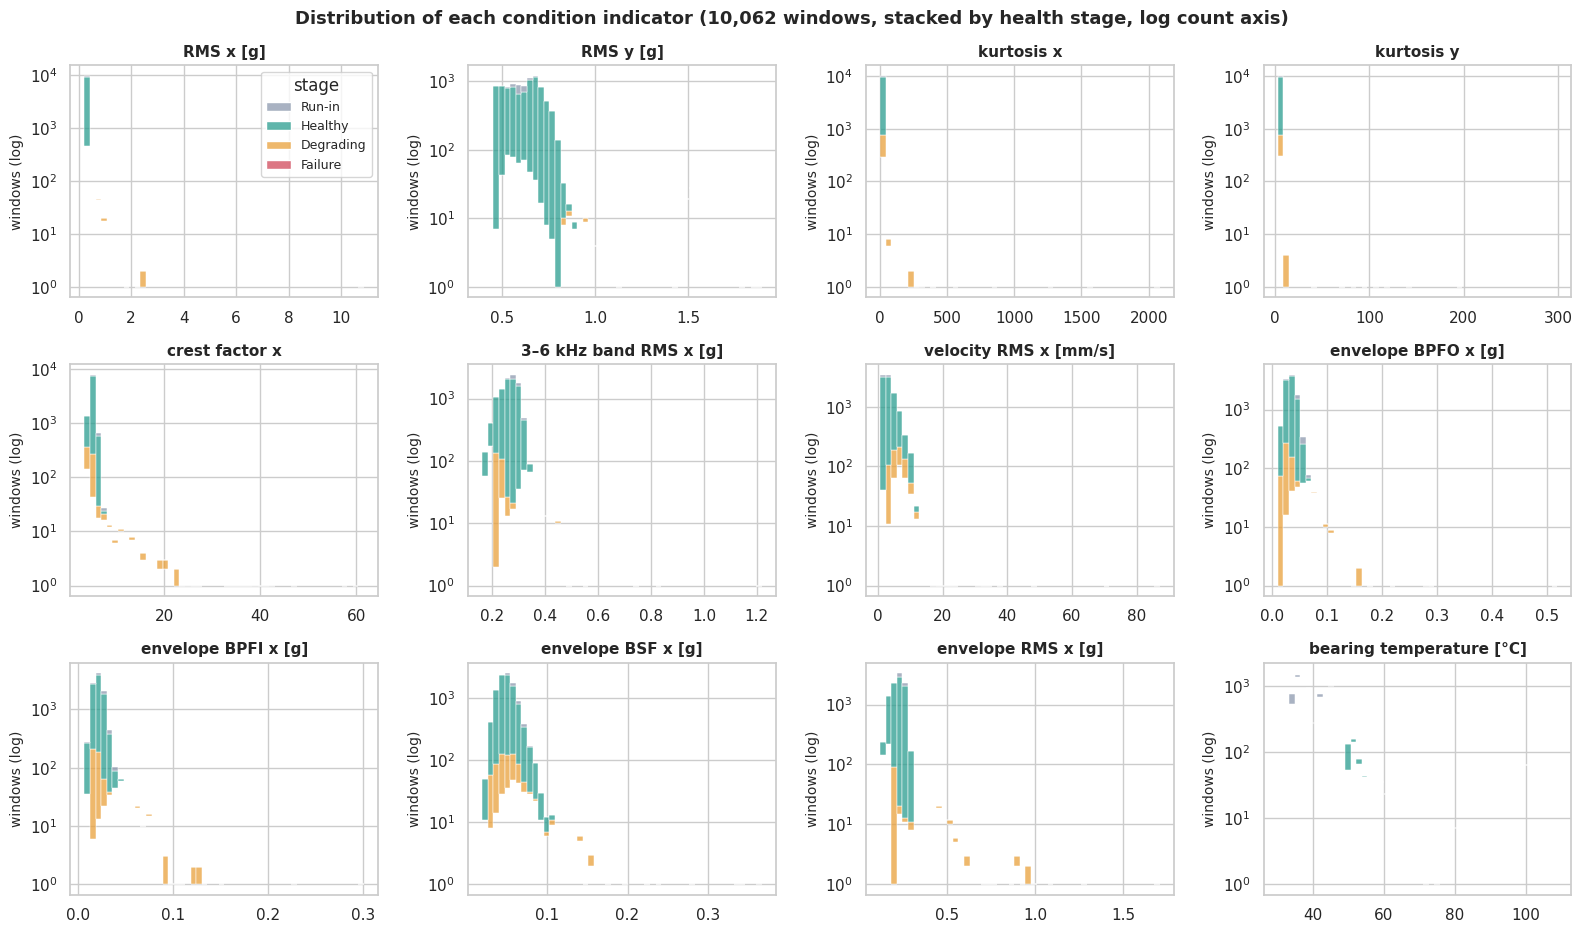

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, col in zip(axes.flat, EDA[:12]):
    sns.histplot(data=feat, x=col, hue="stage", hue_order=STAGE_ORDER, palette=STAGE_COLORS, bins=50,
                 multiple="stack", ax=ax, legend=(col == EDA[0]), log_scale=(False, True), edgecolor=None)
    ax.set(title=LABELS[col], xlabel="", ylabel="windows (log)")
fig.suptitle("Distribution of each condition indicator (10,062 windows, stacked by health stage, log count axis)",
             fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

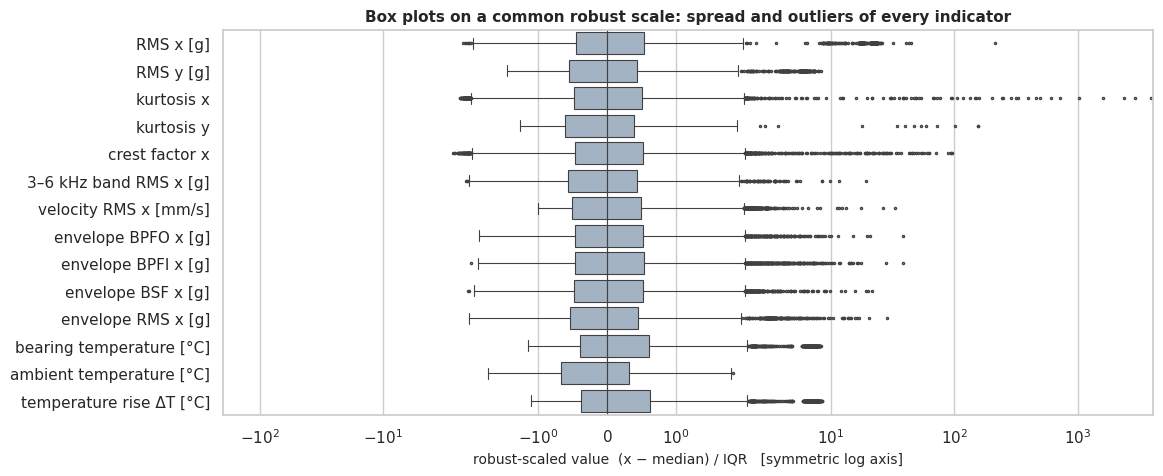

In [ ]:
robust = (feat[EDA] - feat[EDA].median()) / (feat[EDA].quantile(0.75) - feat[EDA].quantile(0.25))
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=robust.rename(columns=LABELS), orient="h", ax=ax, color="#9fb3c8", fliersize=1.5, linewidth=0.8)
ax.set_xscale("symlog"); ax.axvline(0, color="#444", lw=0.8)
ax.set(xlabel="robust-scaled value  (x − median) / IQR   [symmetric log axis]",
       title="Box plots on a common robust scale: spread and outliers of every indicator")
plt.show()

#### 🔎 Key findings – univariate (numerical)
* **Every indicator is strongly right-skewed** and normality is rejected for all of them (p < 10⁻²⁹). The maximum of the RMS is
  33 times its median, kurtosis reaches 2,081 against a median of 4.0, and the temperature rise reaches 82 °C against a median of
  14 °C. The stacked histograms show that **the long tails are made of the Degrading and Failure windows**: the distributions are
  mixtures of a healthy population and a small failure population.
* Ambient temperature is the only nearly symmetric variable (skewness 0.19, range 24.4–26.8 °C), as expected for a laboratory.
* The box plots on a common robust scale show spreads that differ by orders of magnitude between indicators.
* **Implication:** use log transforms, robust (median/MAD) scaling and non-parametric statistics. Means, standard deviations and
  Pearson correlations are distorted by a handful of failure hours.

### 3.2 Univariate analysis – categorical variables (EDA brief, step 3)
The engineered categories from Section 2.7, counted per test hour with `value_counts()`. The first one is our **ordinal
target**, the machine status $Y(t)$.

In [ ]:
CATS = {"machine_status": "Machine status Y(t) (ordinal target)", "stage": "Health stage (rule-based)",
        "temp_band": "Bearing-temperature band", "iso_zone": "ISO 10816 severity zone",
        "test_day": "Test day", "time_of_day": "Time of day"}
counts = {c: hourly[c].value_counts(sort=False) for c in CATS}
for c, title in CATS.items():
    print(f"{title}:", counts[c].to_dict())
status_table = pd.DataFrame({"Y": range(4), "icon": [STATUS_ICON[s] for s in STATUS_ORDER],
                             "hours": counts["machine_status"].reindex(STATUS_ORDER).to_numpy(),
                             "windows": feat["machine_status"].value_counts().reindex(STATUS_ORDER).to_numpy()},
                            index=pd.Index(STATUS_ORDER, name="machine status"))
status_table["% of windows"] = (100 * status_table["windows"] / status_table["windows"].sum()).round(1)
status_table

Machine status Y(t) (ordinal target): {'Operational': 116, 'Degraded': 6, 'At risk': 3, 'Fault detected': 4}
Health stage (rule-based): {'Run-in': 8, 'Healthy': 111, 'Degrading': 6, 'Failure': 4}
Bearing-temperature band: {'< 40 °C': 66, '40–60 °C': 58, '60–85 °C': 1, '> 85 °C': 4}
ISO 10816 severity zone: {'A good': 0, 'B acceptable': 0, 'C unsatisfactory': 10, 'D unacceptable': 119}
Test day: {'Day 1': 24, 'Day 2': 24, 'Day 3': 24, 'Day 4': 24, 'Day 5': 24, 'Day 6': 9}
Time of day: {'Day 06–18': 61, 'Night 18–06': 68}


,Y,icon,hours,windows,% of windows
machine status,,,,,
Operational,0,✅,116,9048,89.9
Degraded,1,🔻,6,468,4.7
At risk,2,⚠️,3,234,2.3
Fault detected,3,❌,4,312,3.1


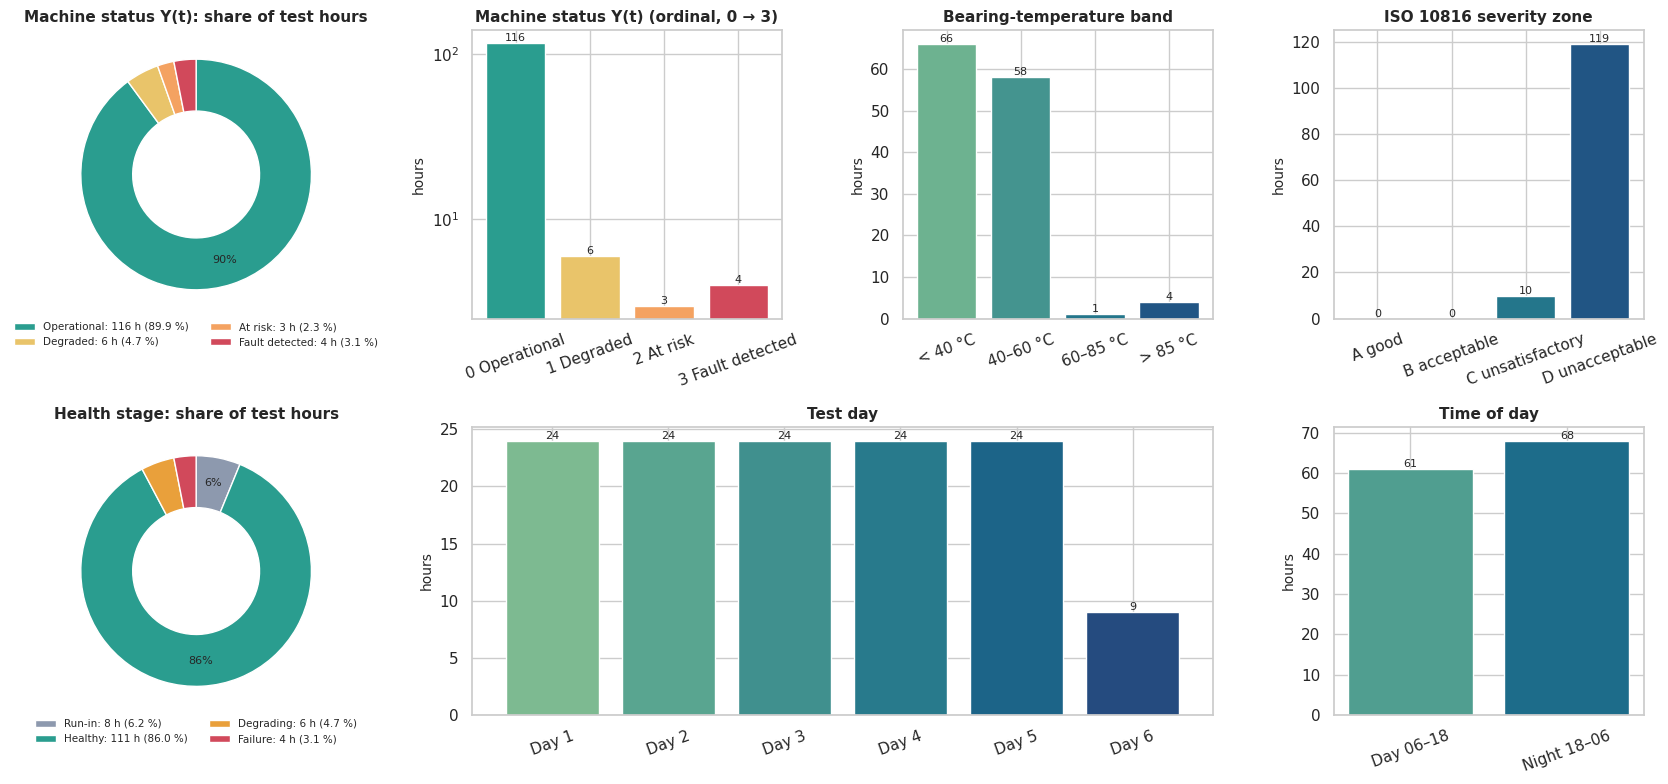

In [ ]:
fig = plt.figure(figsize=(17, 8))
gs = gridspec.GridSpec(2, 4, figure=fig)
for row, (col, order, colors, title) in enumerate([
        ("machine_status", STATUS_ORDER, STATUS_COLORS, "Machine status Y(t): share of test hours"),
        ("stage", STAGE_ORDER, STAGE_COLORS, "Health stage: share of test hours")]):
    ax_pie = fig.add_subplot(gs[row, 0])
    vc = counts[col].reindex(order)
    ax_pie.pie(vc, colors=[colors[s] for s in order], autopct=lambda p: f"{p:.0f}%" if p > 5 else "", startangle=90,
               counterclock=False, wedgeprops=dict(width=0.45, edgecolor="white"), pctdistance=0.78, textprops={"fontsize": 8})
    ax_pie.legend([f"{s}: {n} h ({100 * n / vc.sum():.1f} %)" for s, n in vc.items()], loc="upper center",
                  bbox_to_anchor=(0.5, 0.02), ncol=2, fontsize=7.5, frameon=False)
    ax_pie.set_title(title)
ax = fig.add_subplot(gs[0, 1])
vc = counts["machine_status"].reindex(STATUS_ORDER)
ax.bar([f"{i} {s}" for i, s in enumerate(STATUS_ORDER)], vc.values, color=[STATUS_COLORS[s] for s in STATUS_ORDER])
for i, v in enumerate(vc.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set(title="Machine status Y(t) (ordinal, 0 → 3)", ylabel="hours", yscale="log"); ax.tick_params(axis="x", rotation=20)
for c, pos in zip(["temp_band", "iso_zone", "test_day", "time_of_day"], [gs[0, 2], gs[0, 3], gs[1, 1:3], gs[1, 3]]):
    ax = fig.add_subplot(pos)
    vc = counts[c]
    ax.bar(vc.index.astype(str), vc.values, color=sns.color_palette("crest", len(vc)))
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
    ax.set(title=CATS[c], ylabel="hours"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

#### 🔎 Key findings – univariate (categorical)
* **Machine status Y(t)** (the ordinal target): ✅ Operational 116 h (89.9 % of the windows), 🔻 Degraded 6 h (4.7 %),
  ⚠️ At risk 3 h (2.3 %), ❌ Fault detected 4 h (3.1 %). The three warning levels cover only **13 hours (10 % of the windows)** and
  the shortest one just 3 hours – a severely **imbalanced** target (Lecture 8), so accuracy would be a misleading metric.
* **Health stage:** Healthy 111 h (86 %), Run-in 8 h (6 %), Degrading 6 h (5 %), Failure 4 h (3 %). The stages *describe* what happened
  (points P and F); the status is what the models must *predict*. Both agree on the last 4 hours, but the status warns 3 hours earlier
  than the Degrading stage because it is set from the remaining life, not from a detector.
* **Temperature band:** 66 h below 40 °C, 58 h at 40–60 °C, only 1 h at 60–85 °C and 4 h above 85 °C. The bearing goes from "warm" to
  "over the limit" within about two hours.
* **ISO 10816 zone:** 0 h in zones A/B, 10 h in C and **119 h in D ("unacceptable")** – almost from the start. Generic absolute
  severity limits do not fit this heavily loaded test rig; thresholds must be **relative to the machine's own baseline**.
* Test days 1–5 contain 24 h each (day 6: 9 h); day and night hours are balanced (61 / 68), so time of day cannot bias comparisons.

---
## 4️⃣ 4. Multivariate Analysis
Correlation and its statistical significance, numerical versus categorical variables, the multivariate structure and a simple linear regression with `statsmodels`.


### 4.1 Multivariate analysis – correlation (EDA brief, step 4)
Pearson measures *linear* association; Spearman measures *monotonic* association (Lecture 14). For degradation, Spearman is
usually the more honest measure because the indicators grow non-linearly near the end of life.

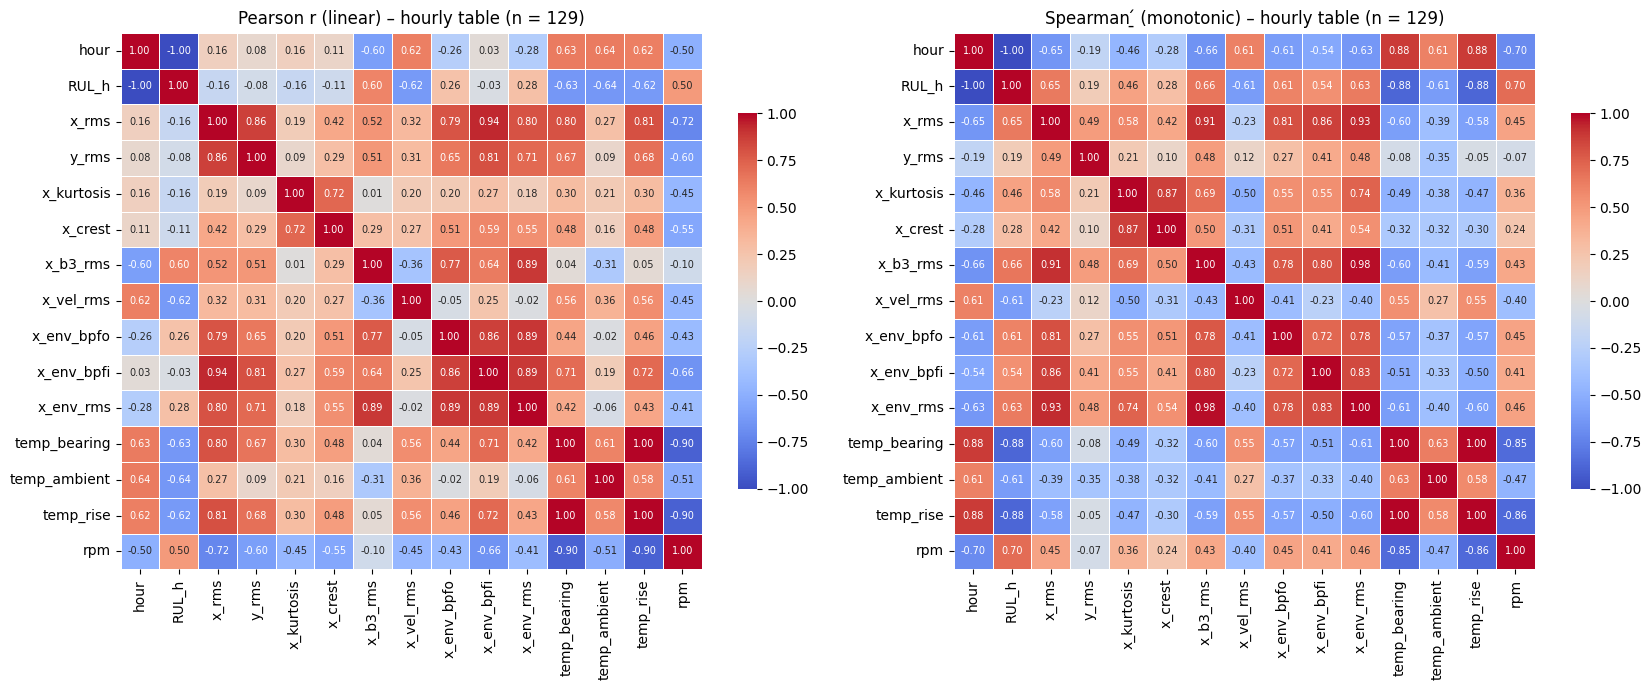

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

CORR = ["hour", "RUL_h", "x_rms", "y_rms", "x_kurtosis", "x_crest", "x_b3_rms", "x_vel_rms",
        "x_env_bpfo", "x_env_bpfi", "x_env_rms", "temp_bearing", "temp_ambient", "temp_rise", "rpm"]
H = hourly.reset_index()                                   # 'hour' as a column for correlation work
pear, spear = H[CORR].corr("pearson"), H[CORR].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, mat, name in zip(axes, (pear, spear), ("Pearson r (linear)", "Spearman ̱́ (monotonic)")):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7},
                cbar_kws={"shrink": 0.7}, linewidths=0.4)
    ax.set_title(f"{name} – hourly table (n = {len(hourly)})")
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for col in [c for c in CORR if c not in ("hour", "RUL_h")]:
    r, p_r = stats.pearsonr(H[col], H["RUL_h"])
    rho, p_rho = stats.spearmanr(H[col], H["RUL_h"])
    rows.append({"variable": LABELS.get(col, col), "Pearson r": r, "p (Pearson)": p_r,
                 "Spearman ρ": rho, "p (Spearman)": p_rho})
sig = pd.DataFrame(rows).set_index("variable").sort_values("Spearman ρ", key=np.abs, ascending=False)
sig["significant at 5 %"] = np.where(sig["p (Spearman)"] < 0.05, "yes", "no")
print("Correlation of each variable with the remaining useful life (hourly data, n = 129):")
sig

In [ ]:
def partial_corr(df, x, y, controls):
    """Correlation of x and y after removing the linear effect of the control variables (Lecture 14)."""
    Z = sm.add_constant(df[controls])
    rx = sm.OLS(df[x], Z).fit().resid
    ry = sm.OLS(df[y], Z).fit().resid
    return stats.pearsonr(rx, ry)

pairs = [("temp_bearing", "x_rms", ["temp_ambient"]), ("temp_bearing", "hour", ["temp_ambient"]),
         ("x_rms", "y_rms", []), ("temp_bearing", "temp_ambient", ["hour"])]
pc = []
for x, y, ctrl in pairs:
    raw_r, raw_p = stats.pearsonr(H[x], H[y])
    part = partial_corr(H, x, y, ctrl) if ctrl else (raw_r, raw_p)
    pc.append({"pair": f"{x} ~ {y}", "controls": ", ".join(ctrl) or "–", "r": raw_r, "partial r": part[0], "p (partial)": part[1]})
pd.DataFrame(pc).set_index("pair")

#### 🔎 Key findings – correlation
* **Temperatures track the remaining life best:** Spearman ρ = −0.88 for bearing temperature and for the temperature rise, then
  **speed (ρ = +0.70)**: the bearing gets hotter and the motor slower as the end approaches.
* **Vibration energy correlates *positively* with RUL** (RMS x ρ = +0.65, 3–6 kHz band +0.66, envelope RMS +0.63): vibration slowly
  *decreased* over the life and only exploded in the final hours. Its Pearson correlation with RUL is weak and not significant
  (r = −0.16, p = 0.06), because a few extreme hours dominate a linear measure.
* Strong **redundancy**: RMS x and RMS y correlate at r = 0.86, and the two temperatures and ΔT are almost interchangeable.
* Partial correlation: bearing temperature vs RMS x stays at r = 0.83 after removing ambient temperature, but that link is driven by the
  final hours, when heat and vibration explode together. Correlation alone cannot say which causes which (Lecture 14).
* *Caveat:* the p-values assume independent hours, but consecutive hours are strongly autocorrelated (Section 5.1), so the true
  significance is weaker than printed.

### 4.2 Multivariate analysis – numerical vs categorical (EDA brief, step 4)
Box and violin plots of the main indicators per health stage, followed by non-parametric tests (the distributions are far
from normal, Section 3.1): **Kruskal–Wallis** across all stages and **Mann–Whitney U** for Healthy vs Degrading.

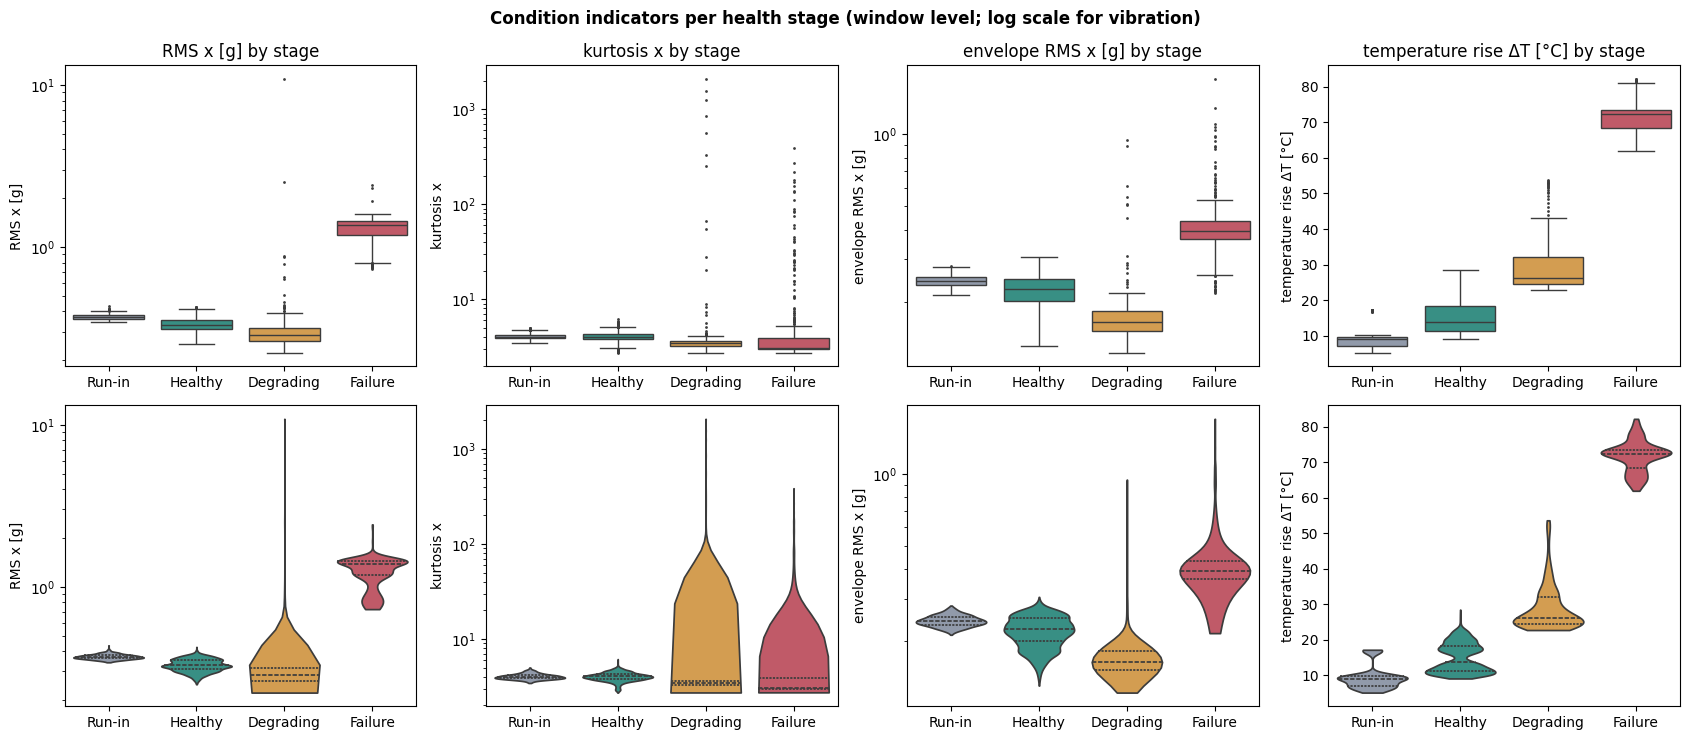

In [23]:
# Locally define configurations to ensure self-contained execution
STAGE_ORDER = ["Run-in", "Healthy", "Degrading", "Failure"]
STAGE_COLORS = {"Run-in": "#8d99ae", "Healthy": "#2a9d8f", "Degrading": "#e9a03b", "Failure": "#d1495b"}

LABELS = {
    "x_rms": "RMS x [g]",
    "x_kurtosis": "kurtosis x",
    "x_env_rms": "envelope RMS x [g]",
    "temp_rise": "temperature rise \u0394T [\u00b0C]"
}

# Ensure 'stage' and 'temp_rise' exist in feat
if "stage" not in feat.columns:
    feat = feat.merge(hourly[["stage"]], left_on="hour", right_index=True, how="left")

feat["temp_rise"] = feat["temp_bearing"] - feat["temp_ambient"]

SHOW = ["x_rms", "x_kurtosis", "x_env_rms", "temp_rise"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for j, col in enumerate(SHOW):
    sns.boxplot(data=feat, x="stage", y=col, hue="stage", order=STAGE_ORDER, palette=STAGE_COLORS,
                ax=axes[0, j], fliersize=1, legend=False)
    sns.violinplot(data=feat, x="stage", y=col, hue="stage", order=STAGE_ORDER, palette=STAGE_COLORS,
                   ax=axes[1, j], cut=0, inner="quartile", legend=False, density_norm="width")
    for i in range(2):
        axes[i, j].set(xlabel="", ylabel=LABELS.get(col, col))
        if col != "temp_rise":
            axes[i, j].set_yscale("log")
    axes[0, j].set_title(f"{LABELS.get(col, col)} by stage")
plt.suptitle("Condition indicators per health stage (window level; log scale for vibration)", weight="bold")
plt.tight_layout(); plt.show()

In [32]:
import scipy.stats as stats
import pandas as pd

EDA = ["x_rms", "y_rms", "x_kurtosis", "y_kurtosis", "x_crest", "x_b3_rms", "x_vel_rms",
       "x_env_bpfo", "x_env_bpfi", "x_env_bsf", "x_env_rms", "temp_bearing", "temp_ambient", "temp_rise"]
STAGE_ORDER = ["Run-in", "Healthy", "Degrading", "Failure"]

# Local fallback dictionary for labels mapping - fixed null byte characters
_desc = {"rms": ("RMS", "g"), "peak": ("peak", "g"), "p2p": ("peak-to-peak", "g"), "crest": ("crest factor", ""),
         "kurtosis": ("kurtosis", ""), "skewness": ("skewness", ""), "shape": ("shape factor", ""),
         "impulse": ("impulse factor", ""), "clearance": ("clearance factor", ""), "b1_rms": ("10 Hz-1 kHz band RMS", "g"),
         "b2_rms": ("1-3 kHz band RMS", "g"), "b3_rms": ("3-6 kHz band RMS", "g"), "b4_rms": ("6-10 kHz band RMS", "g"),
         "b5_rms": ("10-12 kHz band RMS", "g"), "spec_centroid": ("spectral centroid", "Hz"),
         "spec_entropy": ("spectral entropy", ""), "vel_rms": ("velocity RMS", "mm/s"), "1x": ("1% amplitude", "g"),
         "2x": ("2% amplitude", "g"), "env_rms": ("envelope RMS", "g"), "mean": ("mean (DC)", "g")}
for k in ("ftf", "bpfo", "bpfi", "bsf"):
    _desc[f"env_{k}"], _desc[f"env_{k}_snr"] = (f"envelope {k.upper()}", "g"), (f"envelope {k.upper()} SNR", "")
LABELS = {f"{a}_{k}": f"{name} {a}" + (f" [{u}]" if u else "") for a in "xy" for k, (name, u) in _desc.items()}
LABELS.update({"temp_bearing": "bearing temperature [degC]", "temp_ambient": "ambient temperature [degC]",
               "temp_rise": "temperature rise Delta T [degC]", "rpm": "speed S(t) [rpm]", "hour": "test hour", "RUL_h": "RUL [h]",
               "z_temp_rise": "temperature rise (robust z)", "z_speed_drop": "speed drop (robust z)"})

tests = []
for col in EDA:
    groups = {s: feat.loc[feat["stage"] == s, col] for s in STAGE_ORDER if (feat["stage"] == s).any()}
    H, p_kw = stats.kruskal(*groups.values())
    h_, d_ = groups["Healthy"], groups["Degrading"]
    U, p_mw = stats.mannwhitneyu(d_, h_, alternative="two-sided")
    tests.append({"indicator": LABELS.get(col, col), "Kruskal-Wallis H": H, "p (KW)": p_kw,
                  "Mann-Whitney p (Degrading vs Healthy)": p_mw,
                  "effect size (rank-biserial)": 2 * U / (len(h_) * len(d_)) - 1,
                  **{f"median {s}": g.median() for s, g in groups.items()}})
pd.DataFrame(tests).set_index("indicator").sort_values("Kruskal-Wallis H", ascending=False)

,Kruskal-Wallis H,p (KW),Mann-Whitney p (Degrading vs Healthy),effect size (rank-biserial),median Run-in,median Healthy,median Degrading,median Failure
indicator,,,,,,,,
temperature rise Delta T [degC],3156.588838,0.000000e+00,1.809182e-288,0.994584,9.027800,13.705500,26.231400,72.439350
bearing temperature [degC],3149.527833,0.000000e+00,1.535676e-289,0.996443,34.251450,39.311650,52.775900,98.983650
ambient temperature [degC],2546.971623,0.000000e+00,2.561227e-291,0.999521,25.140300,25.550450,26.544000,26.513200
RMS x [g],2276.602438,0.000000e+00,2.785476e-98,-0.576542,0.368885,0.329156,0.285624,1.373270
envelope RMS x [g],1902.698318,0.000000e+00,2.393345e-191,-0.808511,0.243639,0.225359,0.163959,0.394595
3-6 kHz band RMS x [g],1706.547514,0.000000e+00,7.011028e-200,-0.826536,0.284494,0.265829,0.204818,0.328804
envelope BPFO x [g],1289.708439,2.517056e-279,2.748968e-51,-0.412803,0.042885,0.033812,0.027716,0.060887
velocity RMS x [mm/s],1072.119351,4.071056e-232,6.757573e-89,0.547747,2.562495,3.100770,5.568305,7.021470
envelope BPFI x [g],1017.489289,2.891608e-220,3.109579e-23,-0.272072,0.024008,0.020998,0.018478,0.045274


In [ ]:
# categorical vs categorical: health stage x temperature band and x ISO zone (hours), chi-square test of independence
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
chi_rows = []
for ax, other in zip(axes, ["temp_band", "iso_zone"]):
    ct = pd.crosstab(hourly["stage"], hourly[other])
    ct = ct.loc[:, ct.sum() > 0]
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))) if min(ct.shape) > 1 else np.nan
    chi_rows.append({"table": f"stage x {other}", "chi2": chi2, "dof": dof, "p": p, "Cramér's V": cramers_v})
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", ax=ax, cbar=False)
    ax.set(title=f"Hours per stage and {CATS[other].lower()}", xlabel=CATS[other], ylabel="health stage")
plt.tight_layout(); plt.show()
pd.DataFrame(chi_rows).set_index("table")

#### Indicators versus the ordinal target $Y(t)$
How do the indicators move across the four machine statuses? For an **ordinal** variable the appropriate correlation is
**Spearman's ρ** with the level codes 0–3: it uses only the order of the levels, not distances between them (Lecture 14).
Kruskal–Wallis tests whether the indicator differs between the statuses at all. Run-in hours are left out (start-up transient).

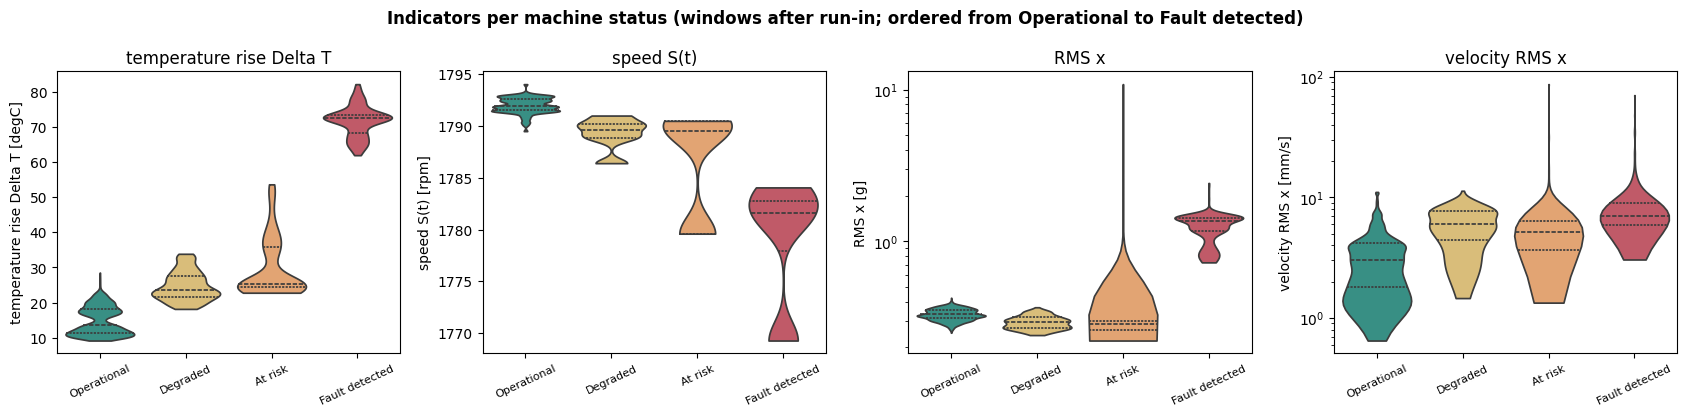

,Spearman H with Y,p (Spearman),Kruskal-Wallis H,p (KW),median ✅ Operational,median ቁ5 Degraded,median ☀️ At risk,median ❀ Fault detected
indicator,,,,,,,,
ambient temperature [degC],0.535404,0.000000e+00,2709.764763,0.000000e+00,25.538000,26.432900,26.554100,26.513200
bearing temperature [degC],0.524336,0.000000e+00,2595.293539,0.000000e+00,39.103900,50.047450,51.748800,98.983650
speed S(t) [rpm],-0.522827,0.000000e+00,2580.783505,0.000000e+00,1791.910000,1789.600000,1789.530000,1781.580000
temperature rise Delta T [degC],0.518251,0.000000e+00,2536.584448,0.000000e+00,13.529450,23.569700,25.244000,72.439350
velocity RMS x [mm/s],0.368101,1.021717e-300,1320.383899,5.557738e-286,3.055035,6.052495,5.133655,7.021470
kurtosis x,-0.353286,1.592679e-275,1250.041668,1.017771e-270,4.048045,3.414070,3.488430,3.071445
kurtosis y,-0.245433,1.672549e-129,707.034239,6.262374e-153,5.435790,4.601150,4.687465,3.216080
crest factor x,-0.189223,8.427517e-77,491.260918,3.737014e-106,5.059975,4.585285,4.736800,4.763095
3-6 kHz band RMS x [g],-0.175378,4.542698e-66,1867.061432,0.000000e+00,0.266726,0.209060,0.203699,0.328804


In [33]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

STATUS_COLORS = {"Operational": "#2a9d8f", "Degraded": "#e9c46a", "At risk": "#f4a261", "Fault detected": "#d1495b"}
STATUS_ORDER = ["Operational", "Degraded", "At risk", "Fault detected"]
STATUS_ICON = {"Operational": "\u2705", "Degraded": "\u12415", "At risk": "\u2600\ufe0f", "Fault detected": "\u2740"}
EDA = ["x_rms", "y_rms", "x_kurtosis", "y_kurtosis", "x_crest", "x_b3_rms", "x_vel_rms",
       "x_env_bpfo", "x_env_bpfi", "x_env_bsf", "x_env_rms", "temp_bearing", "temp_ambient", "temp_rise"]

# Ensure 'machine_status' mapping column and 'rpm' column are joined from 'hourly' onto 'feat'
if "machine_status" not in feat.columns:
    feat = feat.merge(hourly[["machine_status", "status_code"]], left_on="hour", right_index=True, how="left")
if "rpm" not in feat.columns:
    feat = feat.merge(hourly[["rpm"]], left_on="hour", right_index=True, how="left")

after = feat["hour"] >= RUN_IN
ORD_SHOW = ["temp_rise", "rpm", "x_rms", "x_vel_rms"]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, col in zip(axes, ORD_SHOW):
    sns.violinplot(data=feat[after], x="machine_status", y=col, hue="machine_status", order=STATUS_ORDER,
                   palette=STATUS_COLORS, ax=ax, cut=0, inner="quartile", legend=False, density_norm="width")
    ax.set(xlabel="", ylabel=LABELS.get(col, col), title=LABELS.get(col, col).split(" [")[0])
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    if col in ("x_rms", "x_vel_rms"):
        ax.set_yscale("log")
plt.suptitle("Indicators per machine status (windows after run-in; ordered from Operational to Fault detected)", weight="bold")
plt.tight_layout(); plt.show()

ord_rows = []
codes = feat.loc[after, "status_code"]
for col in EDA + ["rpm"]:
    rho, p_rho = stats.spearmanr(feat.loc[after, col], codes)
    groups = [feat.loc[after & (feat["status_code"] == k), col] for k in range(4)]
    H_kw, p_kw = stats.kruskal(*groups)
    ord_rows.append({"indicator": LABELS.get(col, col), "Spearman H with Y": rho, "p (Spearman)": p_rho,
                     "Kruskal-Wallis H": H_kw, "p (KW)": p_kw,
                     **{f"median {STATUS_ICON[s]} {s}": g.median() for s, g in zip(STATUS_ORDER, groups)}})
pd.DataFrame(ord_rows).set_index("indicator").sort_values("Spearman H with Y", key=np.abs, ascending=False)

#### 🔎 Key findings – numerical vs categorical
* Kruskal–Wallis is significant for every indicator, but with ~10,000 windows almost any difference is "significant". The
  **effect size** (rank-biserial, Degrading vs Healthy) is the useful number:
  * temperature rise **+0.99** and bearing temperature **+1.00** – near-perfect separation (median ΔT 13.7 °C healthy vs 26.2 °C degrading);
  * vibration indicators are *lower* in the degrading stage than in healthy operation: 3–6 kHz band −0.83, envelope RMS −0.81,
    kurtosis −0.72, RMS x −0.58 (median 0.33 g → 0.29 g). The degrading bearing ran **hotter and quieter**, until the final event;
  * ambient temperature also separates (+1.00, 25.6 → 26.5 °C): the laboratory warmed up late in the test. This **confounder** is
    why we use the temperature *rise* rather than the raw bearing temperature.
* Chi-square tests confirm that stage is associated with the temperature band (χ² = 158.5, p ≈ 10⁻²⁹, Cramér's V = 0.64) and with the
  ISO zone (χ² = 76.0, p ≈ 10⁻¹⁶, V = 0.77). Several expected counts are below 5, so these tests are indicative only.
* **Across the ordinal machine statuses** (Spearman ρ with Y = 0…3, windows after run-in): the bearing temperature (ρ = 0.52), the
  temperature rise (0.52) and the speed (−0.52) move monotonically with the status – median ΔT 13.5 → 23.6 → 25.2 → 72.4 °C and speed
  1,792 → 1,790 → 1,790 → 1,782 rpm. The ambient temperature scores highest (0.54) only because the laboratory warmed up at the end of
  the test – the same confounder as above.
* Vibration is **not** monotonic in the status: RMS x falls from 0.33 g (Operational) to 0.29 and 0.28 g (Degraded, At risk) before
  jumping to 1.37 g (Fault detected), so its ρ is ≈ 0, and kurtosis even decreases (ρ = −0.35). Velocity RMS x is higher in the warning
  statuses (median 3.1 → 5.1–7.0 mm/s), but similar values already occur in healthy hours 85–115, so it reflects operating regimes
  rather than damage. The envelope BPFO amplitude shows no association at all (ρ = 0.00, p = 0.83).
* **Implication for Q4:** the two physics inputs are the natural candidates for an ordinal status model; vibration alone can only
  recognize the final status.

### 4.3 Multivariate structure: pair plot and the degradation trajectory (PCA)

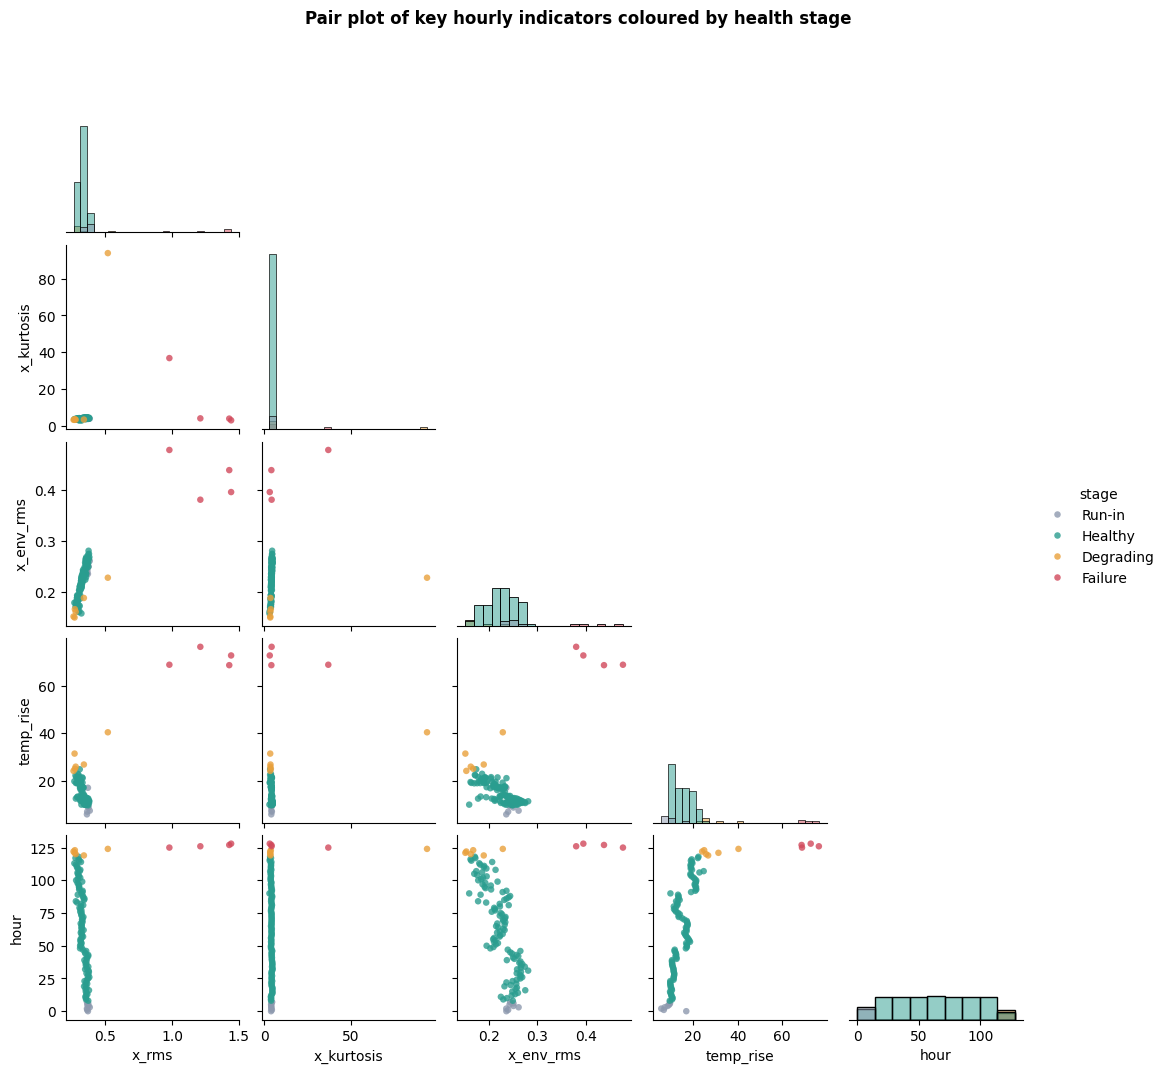

In [34]:
pp = sns.pairplot(hourly.reset_index(), vars=["x_rms", "x_kurtosis", "x_env_rms", "temp_rise", "hour"],
                  hue="stage", hue_order=STAGE_ORDER, palette=STAGE_COLORS, corner=True,
                  plot_kws=dict(s=22, alpha=0.8, edgecolor="none"), diag_kind="hist", height=2.1)
pp.figure.suptitle("Pair plot of key hourly indicators coloured by health stage", y=1.02, weight="bold")
plt.show()

In [ ]:
PCA_FEATS = [c for c in FEATURES if c.startswith(("x_", "y_")) and not c.endswith("_mean")] + ["temp_rise"]
Xp = StandardScaler().fit_transform(hourly[PCA_FEATS])
pca = PCA(n_components=5, random_state=RNG).fit(Xp)
scores = pca.transform(Xp)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(1, 6), pca.explained_variance_ratio_ * 100, color="#3d5a80")
axes[0].plot(range(1, 6), np.cumsum(pca.explained_variance_ratio_) * 100, "o-", color="#d1495b", label="cumulative")
axes[0].set(xlabel="principal component", ylabel="% variance explained",
            title=f"PCA of {len(PCA_FEATS)} standardized indicators"); axes[0].legend()
sc = axes[1].scatter(scores[:, 0], scores[:, 1], c=hourly.index, cmap="viridis", s=28)
axes[1].plot(scores[:, 0], scores[:, 1], lw=0.6, color="#999", zorder=0)
for h in [0, T_EOL]:
    axes[1].annotate(f"hour {h}", (scores[h, 0], scores[h, 1]), xytext=(6, 6), textcoords="offset points", weight="bold")
plt.colorbar(sc, ax=axes[1], label="test hour")
axes[1].set(xlabel="PC1", ylabel="PC2", title="Degradation trajectory in the PC1–PC2 plane")
plt.tight_layout(); plt.show()
loadings = pd.Series(pca.components_[0], index=PCA_FEATS).sort_values(key=np.abs, ascending=False)
print("Largest PC1 loadings:", loadings.head(8).round(3).to_dict())

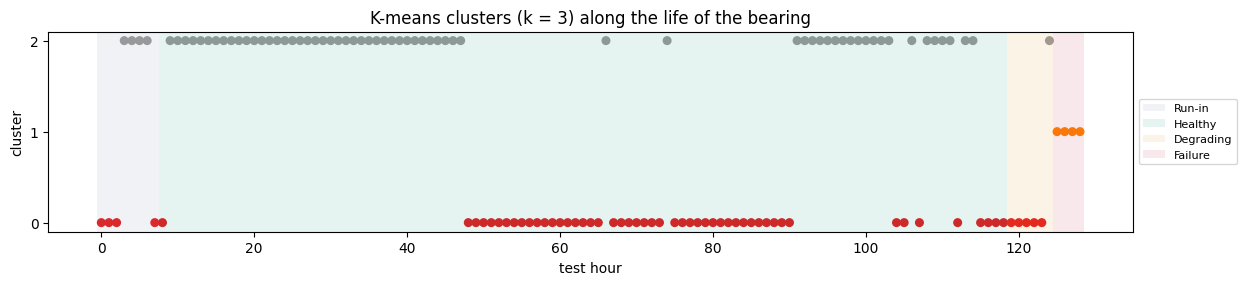

stage,Run-in,Healthy,Degrading,Failure
kmeans_cluster,,,,
0,4,50,5,0
1,0,0,0,4
2,4,61,1,0


In [40]:
# Unsupervised check (Lecture 13): what does K-means find in the hourly indicators?
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd

# Ensure PCA_FEATS, RNG, and helper functions are defined locally
PCA_FEATS = [c for c in FEATURES if c.startswith(("x_", "y_")) and not c.endswith("_mean")] + ["temp_rise"]
RNG = 42

stage_start = hourly.reset_index().groupby("stage", observed=False)["hour"].min()

def shade_stages(ax, alpha=0.10, label=True):
    """Shade the health stages on a time axis (hours)."""
    edges = list(stage_start.dropna().astype(int)) + [T_EOL + 1]
    for (stage, start), end in zip(stage_start.dropna().items(), edges[1:]):
        ax.axvspan(start - 0.5, end - 0.5, color=STAGE_COLORS[stage], alpha=alpha, lw=0,
                   label=stage if label else None)

Zk = StandardScaler().fit_transform(hourly[PCA_FEATS])
km = KMeans(n_clusters=3, n_init=20, random_state=RNG).fit(Zk)
hourly["kmeans_cluster"] = km.labels_
fig, ax = plt.subplots(figsize=(14, 2.6))
ax.scatter(hourly.index, hourly["kmeans_cluster"], c=hourly["kmeans_cluster"], cmap="Set1", s=30)
shade_stages(ax, alpha=0.12)
ax.set(yticks=[0, 1, 2], xlabel="test hour", ylabel="cluster", title="K-means clusters (k = 3) along the life of the bearing")
ax.legend(loc="center left", fontsize=8, bbox_to_anchor=(1, 0.5))
plt.show()
pd.crosstab(hourly["kmeans_cluster"], hourly["stage"])

#### 🔎 Key findings – multivariate structure
* **PCA:** PC1 explains 38 % of the variance and the first two PCs 58 %; PC1 loads on peak and high-frequency (6–12 kHz) energy.
  The healthy hours drift slowly along PC2 (operating regimes); the last five hours shoot out along PC1 – degradation is a
  **sudden excursion**, not a slow walk.
* **K-means (k = 3)** does not recover the health stages. It finds **two operating regimes** – hours 3–47 and 91–113 versus hours 48–90
  and 114–123 – plus the failure hours. The Degrading hours are grouped with a healthy regime.
* **Implication:** unsupervised clustering picks up the largest source of variance, which here is the operating regime, not the
  bearing health. Health labels and detectors must be designed with domain knowledge, and the baseline must contain every regime.

### 4.4 Linear regression with `statsmodels` (EDA brief, step 4)
Two models in the spirit of the brief (*"lifetime as a function of temperature"*):

* **Model A – simple regression:** remaining useful life as a function of the temperature rise, $RUL = \beta_0 + \beta_1\,\Delta T$.
* **Model B – multiple regression (physics check):** does vibration energy heat the bearing once the room temperature is
  accounted for? $T_{bearing} = \beta_0 + \beta_1 T_{ambient} + \beta_2\, RMS_x$.

Hourly observations are serially correlated, which makes ordinary standard errors too small. We therefore also report
**HAC (Newey–West) standard errors** and the Durbin–Watson statistic.

In [43]:
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
import pandas as pd

model_a = smf.ols("RUL_h ~ temp_rise", data=hourly).fit()
model_a_hac = smf.ols("RUL_h ~ temp_rise", data=hourly).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model_a.summary().tables[0])
coef_a = pd.DataFrame({"coef": model_a.params, "std err (OLS)": model_a.bse, "p (OLS)": model_a.pvalues,
                       "std err (HAC)": model_a_hac.bse, "p (HAC)": model_a_hac.pvalues,
                       "95% CI low": model_a.conf_int()[0], "95% CI high": model_a.conf_int()[1]})
display(coef_a)
print(f"R² = {model_a.rsquared:.3f} | Durbin-Watson = {durbin_watson(model_a.resid):.2f} (2 = no autocorrelation)")

                            OLS Regression Results                            
Dep. Variable:                  RUL_h   R-squared:                       0.387
Model:                            OLS   Adj. R-squared:                  0.382
Method:                 Least Squares   F-statistic:                     80.13
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           3.64e-15
Time:                        05:58:04   Log-Likelihood:                -618.13
No. Observations:                 129   AIC:                             1240.
Df Residuals:                     127   BIC:                             1246.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         


,coef,std err (OLS),p (OLS),std err (HAC),p (HAC),95% CI low,95% CI high
Intercept,99.591584,4.743887,4.041461e-43,13.065871,2.492551e-14,90.204287,108.978881
temp_rise,-2.087463,0.233202,3.638336e-15,0.672630,1.912896e-03,-2.548928,-1.625998


R² = 0.387 | Durbin-Watson = 0.06 (2 = no autocorrelation)


,coef,std err (OLS),p (OLS),std err (HAC),p (HAC)
Intercept,-213.207277,23.068748,7.621660e-16,44.096670,1.331475e-06
temp_ambient,9.373045,0.914731,2.718524e-18,1.723727,5.398398e-08
x_rms,46.413069,2.770648,7.488645e-34,3.059940,5.763323e-52


R² = 0.805 | adj. R² = 0.802 | F p-value = 2.09e-45 | Durbin-Watson = 0.32


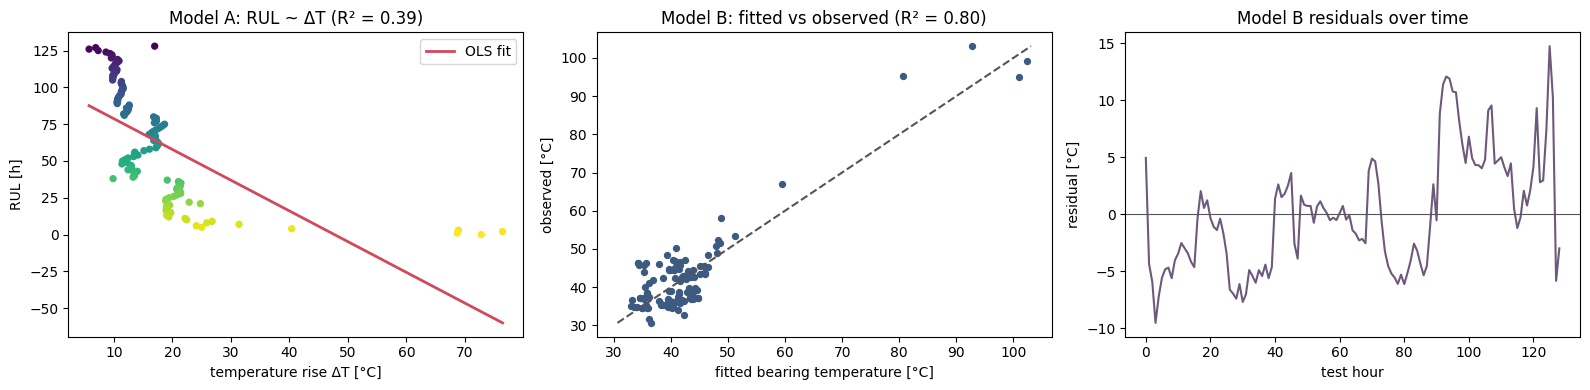

In [44]:
model_b = smf.ols("temp_bearing ~ temp_ambient + x_rms", data=hourly).fit()
model_b_hac = smf.ols("temp_bearing ~ temp_ambient + x_rms", data=hourly).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
coef_b = pd.DataFrame({"coef": model_b.params, "std err (OLS)": model_b.bse, "p (OLS)": model_b.pvalues,
                       "std err (HAC)": model_b_hac.bse, "p (HAC)": model_b_hac.pvalues})
display(coef_b)
print(f"R² = {model_b.rsquared:.3f} | adj. R² = {model_b.rsquared_adj:.3f} | F p-value = {model_b.f_pvalue:.2e} | "
      f"Durbin-Watson = {durbin_watson(model_b.resid):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(hourly["temp_rise"], hourly["RUL_h"], c=hourly.index, cmap="viridis", s=18)
xs = np.linspace(hourly["temp_rise"].min(), hourly["temp_rise"].max(), 50)
axes[0].plot(xs, model_a.params["Intercept"] + model_a.params["temp_rise"] * xs, color="#d1495b", lw=2, label="OLS fit")
axes[0].set(xlabel="temperature rise ΔT [°C]", ylabel="RUL [h]", title=f"Model A: RUL ~ ΔT (R² = {model_a.rsquared:.2f})"); axes[0].legend()
axes[1].scatter(model_b.fittedvalues, hourly["temp_bearing"], s=18, color="#3d5a80")
lims = [hourly["temp_bearing"].min(), hourly["temp_bearing"].max()]
axes[1].plot(lims, lims, "--", color="#555")
axes[1].set(xlabel="fitted bearing temperature [°C]", ylabel="observed [°C]", title=f"Model B: fitted vs observed (R² = {model_b.rsquared:.2f})")
axes[2].plot(hourly.index, model_b.resid, color="#6d597a"); axes[2].axhline(0, color="#555", lw=0.8)
axes[2].set(xlabel="test hour", ylabel="residual [°C]", title="Model B residuals over time")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – regression with statsmodels
* **Model A:** $\widehat{RUL} = 99.6 - 2.09\,\Delta T$. Each extra °C of temperature rise is associated with **2.1 h less remaining
  life**; the slope is significant (p < 0.001 with ordinary SEs, p = 0.002 with HAC SEs). But **R² = 0.39** and the
  **Durbin–Watson statistic is 0.06**: the residuals are heavily autocorrelated and the scatter shows a curve, not a line (ΔT is flat for
  100 hours, then shoots up). A straight line is the wrong functional form for RUL.
* **Model B:** $\hat{T}_{bearing} = -213 + 9.37\,T_{ambient} + 46.4\,RMS_x$ with R² = 0.81. Both slopes are significant, but the
  ambient coefficient (+9.4 °C per °C) is physically implausible – it should be close to 1. Ambient temperature and degradation both
  rose at the end of the test, so the coefficient absorbs the time trend: a textbook **confounding** example (Lecture 14). The RMS
  slope (+46 °C per g) is driven by the failure hours.
* **Implication:** linear regression is useful for *describing* associations, but RUL needs non-linear targets (piecewise-linear),
  time-aware validation and an explicit treatment of confounders.

---
## 5️⃣ 5. Time-Series Summarization and Trend Analysis
Hourly summaries over the test, trend lines and the seasonal decomposition with `statsmodels.tsa`, the trend in the frequency domain, and the anomalies.


### 5.1 Time-series summarization and trend analysis (EDA brief, step 5)
Here the *test hour* plays the role that `lifetime` plays in the brief's example: it is the time-to-event axis.
We summarize per interval with `groupby`, plot the trends, rank the indicators by how well they track degradation,
and look for seasonality with `statsmodels.tsa`.

In [49]:
by_day = hourly.groupby("test_day")[["x_rms", "x_kurtosis", "x_env_rms", "temp_bearing", "temp_ambient", "temp_rise"]].agg(["mean", "max"])
by_stage = hourly.groupby("stage", observed=False)[["x_rms", "x_kurtosis", "x_env_rms", "temp_bearing", "temp_rise", "RUL_h"]].agg(["mean", "min", "max"])
display(by_day.round(3))
by_stage.round(3)

x_rms        x_kurtosis         x_env_rms        temp_bearing  \
           mean    max       mean     max      mean    max         mean   
test_day                                                                  
Day 1     0.362  0.385      4.173   4.740     0.246  0.275       34.817   
Day 2     0.362  0.382      4.335   4.759     0.260  0.281       36.707   
Day 3     0.323  0.339      4.023   4.266     0.219  0.233       42.785   
Day 4     0.319  0.345      4.047   4.477     0.214  0.243       39.933   
Day 5     0.300  0.341      3.683   4.085     0.185  0.217       46.410   
Day 6     0.741  1.443     17.315  93.853     0.284  0.478       74.718   

                  temp_ambient         temp_rise          
              max         mean     max      mean     max  
test_day                                                  
Day 1      41.823       24.969  25.344     9.848  16.977  
Day 2      37.422       25.231  25.658    11.476  12.626  
Day 3      44.523       25.678  26.061    17.107  18.668  
Day 4      46.397       25.460  25.856    14.472  21.467  
Day 5      53.313       25.736  26.525    20.674  26.788  
Day 6     103.091       26.540  26.647    48.178  76.444

x_rms               x_kurtosis                x_env_rms         \
            mean    min    max       mean    min     max      mean    min   
stage                                                                       
Run-in     0.371  0.364  0.385      4.053  3.856   4.459     0.245  0.235   
Healthy    0.331  0.270  0.382      4.057  2.903   4.759     0.224  0.159   
Degrading  0.325  0.263  0.520     18.535  3.354  93.853     0.175  0.151   
Failure    1.266  0.981  1.443     12.033  3.087  36.867     0.423  0.380   

                 temp_bearing                  temp_rise                  \
             max         mean     min      max      mean     min     max   
stage                                                                      
Run-in     0.261       34.362  30.610   41.823     9.287   5.763  16.977   
Healthy    0.281       40.427  34.527   50.353    14.998   9.568  24.785   
Degrading  0.228       55.474  50.650   66.908    28.928  24.101  40.391   
Failure    0.478       98.232  95.143  103.091    71.705  68.696  76.444   

           RUL_h            
            mean  min  max  
stage                       
Run-in     124.5  121  128  
Healthy     65.0   10  120  
Degrading    6.5    4    9  
Failure      1.5    0    3

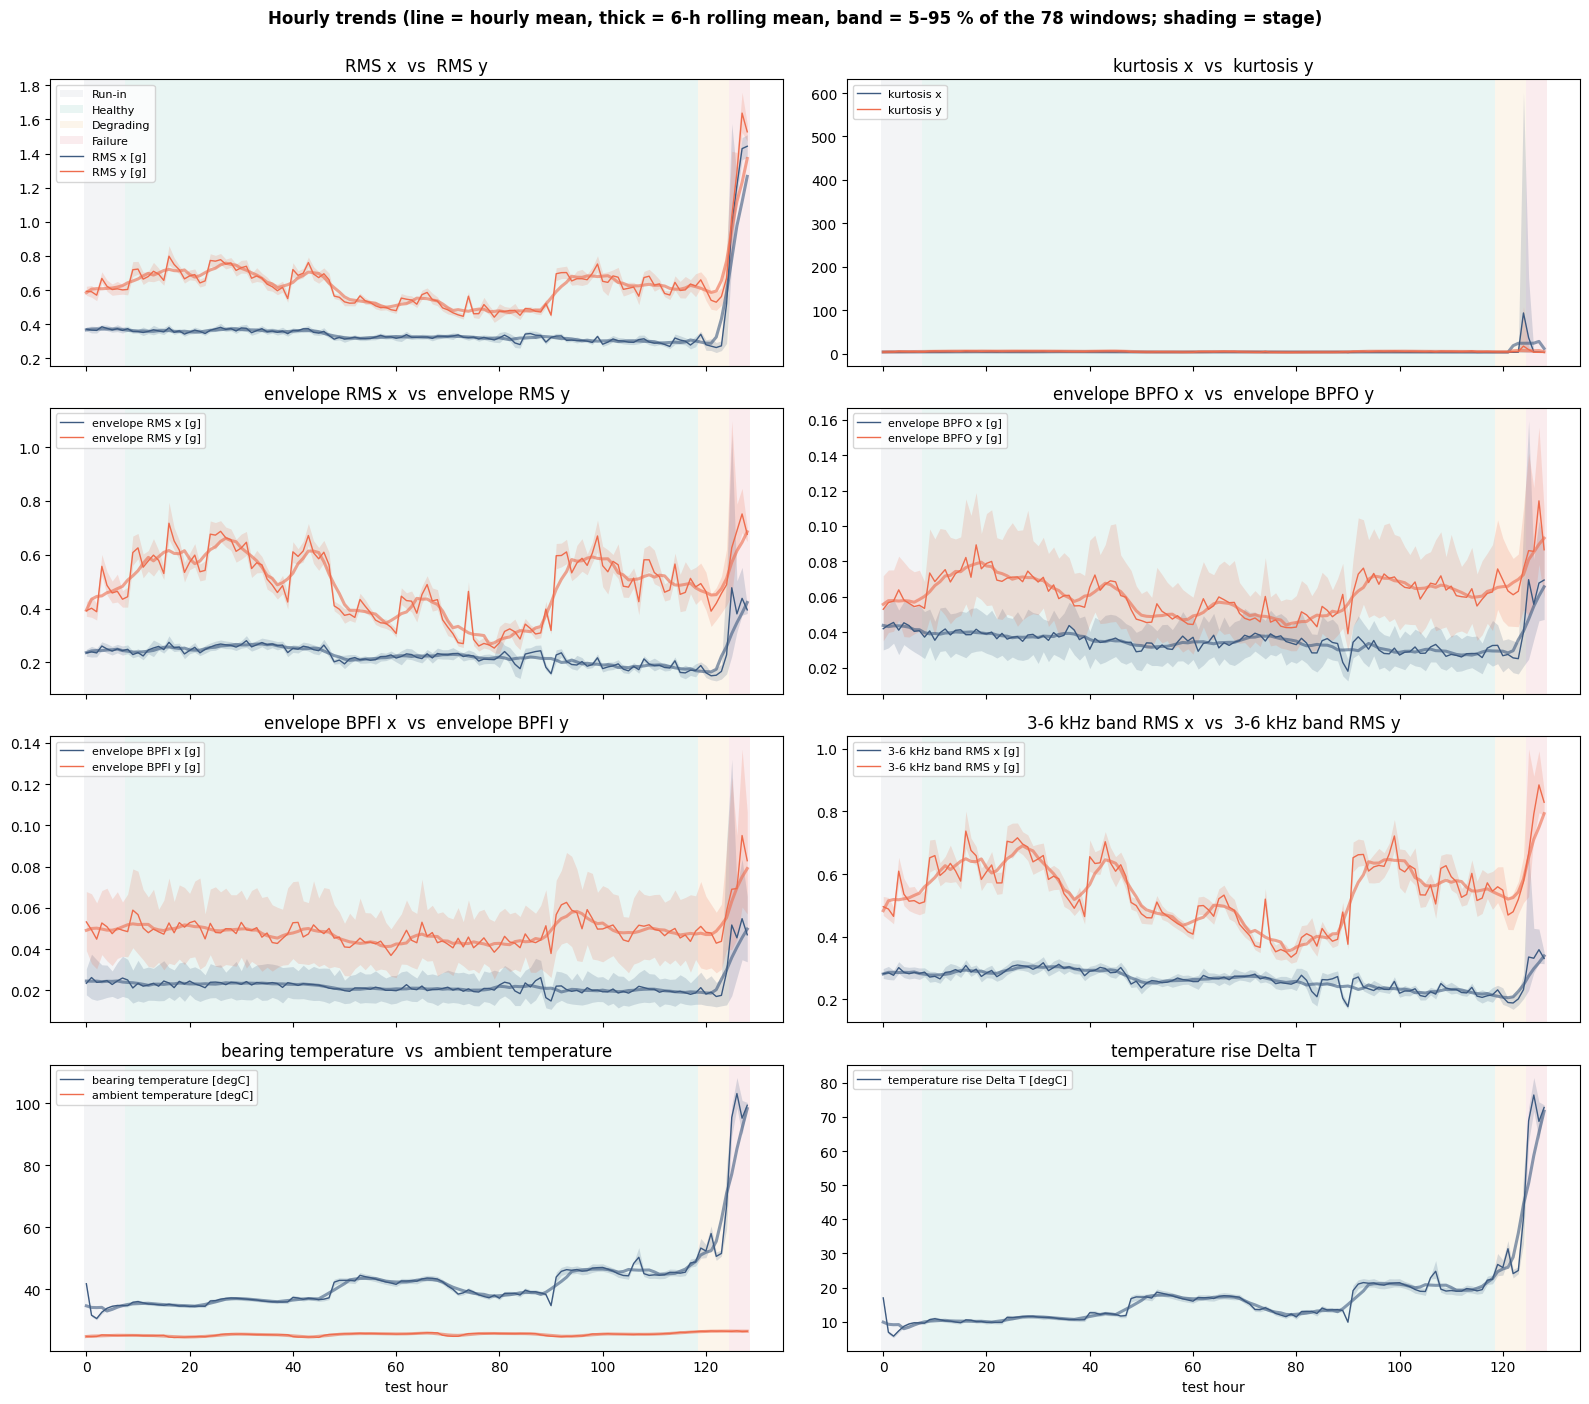

In [50]:
TREND = [("x_rms", "y_rms"), ("x_kurtosis", "y_kurtosis"), ("x_env_rms", "y_env_rms"), ("x_env_bpfo", "y_env_bpfo"),
         ("x_env_bpfi", "y_env_bpfi"), ("x_b3_rms", "y_b3_rms"), ("temp_bearing", "temp_ambient"), ("temp_rise", None)]
q05 = feat.groupby("hour")[[c for pair in TREND for c in pair if c]].quantile(0.05)
q95 = feat.groupby("hour")[[c for pair in TREND for c in pair if c]].quantile(0.95)
fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)
for ax, (a, b) in zip(axes.flat, TREND):
    shade_stages(ax, label=(a == "x_rms"))
    for col, color in ((a, "#3d5a80"), (b, "#ee6c4d")):
        if col is None:
            continue
        ax.fill_between(hourly.index, q05[col], q95[col], color=color, alpha=0.18, lw=0)
        ax.plot(hourly.index, hourly[col], color=color, lw=1, label=LABELS.get(col, col))
        ax.plot(hourly.index, hourly[col].rolling(6, center=True, min_periods=1).mean(), color=color, lw=2.2, alpha=0.6)
    ax.set_title(LABELS.get(a, a).split(" [")[0] + ("" if b is None else f"  vs  {LABELS.get(b, b).split(' [')[0]}"))
    ax.legend(loc="upper left", fontsize=8)
for ax in axes[-1]: ax.set_xlabel("test hour")
fig.suptitle("Hourly trends (line = hourly mean, thick = 6-h rolling mean, band = 5–95 % of the 78 windows; shading = stage)",
             weight="bold", y=1.0)
plt.tight_layout(); plt.show()

**Which indicators are the best degradation trackers?** Prognostics literature scores a candidate health indicator by
**monotonicity** (does it move in one direction?), **trendability** (does it correlate with time?) and **robustness**
(how noisy is it around its trend?). Each score is in [0, 1]; we rank by their mean.

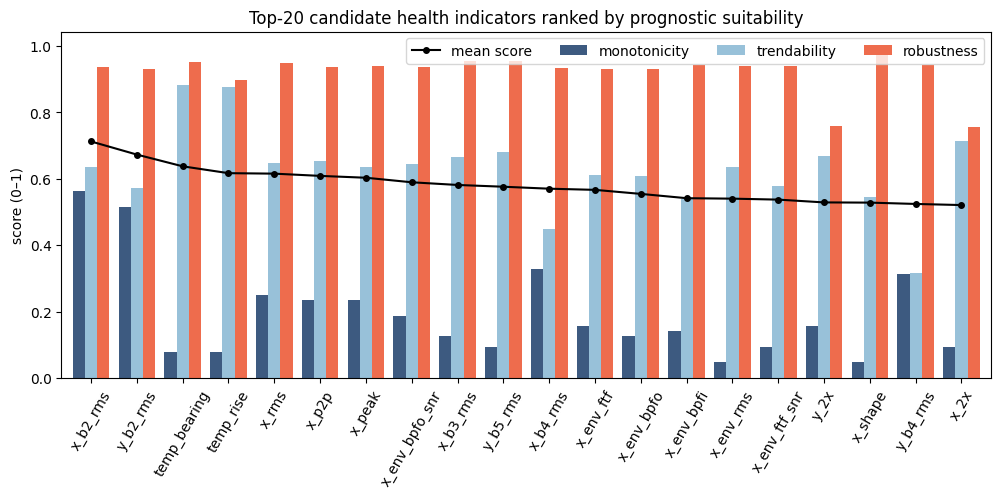

,monotonicity,trendability,robustness,score
x_b2_rms,0.562,0.636,0.937,0.712
y_b2_rms,0.516,0.571,0.931,0.672
temp_bearing,0.078,0.881,0.952,0.637
temp_rise,0.078,0.875,0.896,0.616
x_rms,0.250,0.648,0.947,0.615
x_p2p,0.234,0.654,0.937,0.608
x_peak,0.234,0.635,0.938,0.603
x_env_bpfo_snr,0.188,0.644,0.936,0.589
x_b3_rms,0.125,0.664,0.954,0.581
y_b5_rms,0.094,0.679,0.954,0.576


In [51]:
def prognostic_scores(s, span=12):
    """Monotonicity, trendability and robustness of an hourly series (smoothed with an EMA)."""
    smooth = s.ewm(span=span, adjust=False).mean()
    d = np.diff(smooth.to_numpy())
    mono = abs((d > 0).sum() - (d < 0).sum()) / len(d)
    trend = abs(stats.spearmanr(np.arange(len(s)), s).statistic)
    rob = np.mean(np.exp(-np.abs((s - smooth) / smooth.abs().clip(lower=1e-12))))
    return mono, trend, rob

cand = [c for c in FEATURES if c.startswith(("x_", "y_")) and not c.endswith("_mean")] + ["temp_bearing", "temp_rise"]
ps = pd.DataFrame([prognostic_scores(hourly[c]) for c in cand], index=cand,
                  columns=["monotonicity", "trendability", "robustness"])
ps["score"] = ps.mean(axis=1)
ps = ps.sort_values("score", ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.5))
ps.head(20)[["monotonicity", "trendability", "robustness"]].plot(kind="bar", ax=ax, width=0.8,
                                                                 color=["#3d5a80", "#98c1d9", "#ee6c4d"])
ax.plot(range(20), ps.head(20)["score"], "ko-", ms=4, label="mean score")
ax.set(title="Top-20 candidate health indicators ranked by prognostic suitability", ylabel="score (0–1)")
ax.legend(ncol=4, loc="upper right"); ax.tick_params(axis="x", rotation=60)
plt.show()
ps.head(10).round(3)

NameError: name 'seasonal_decompose' is not defined

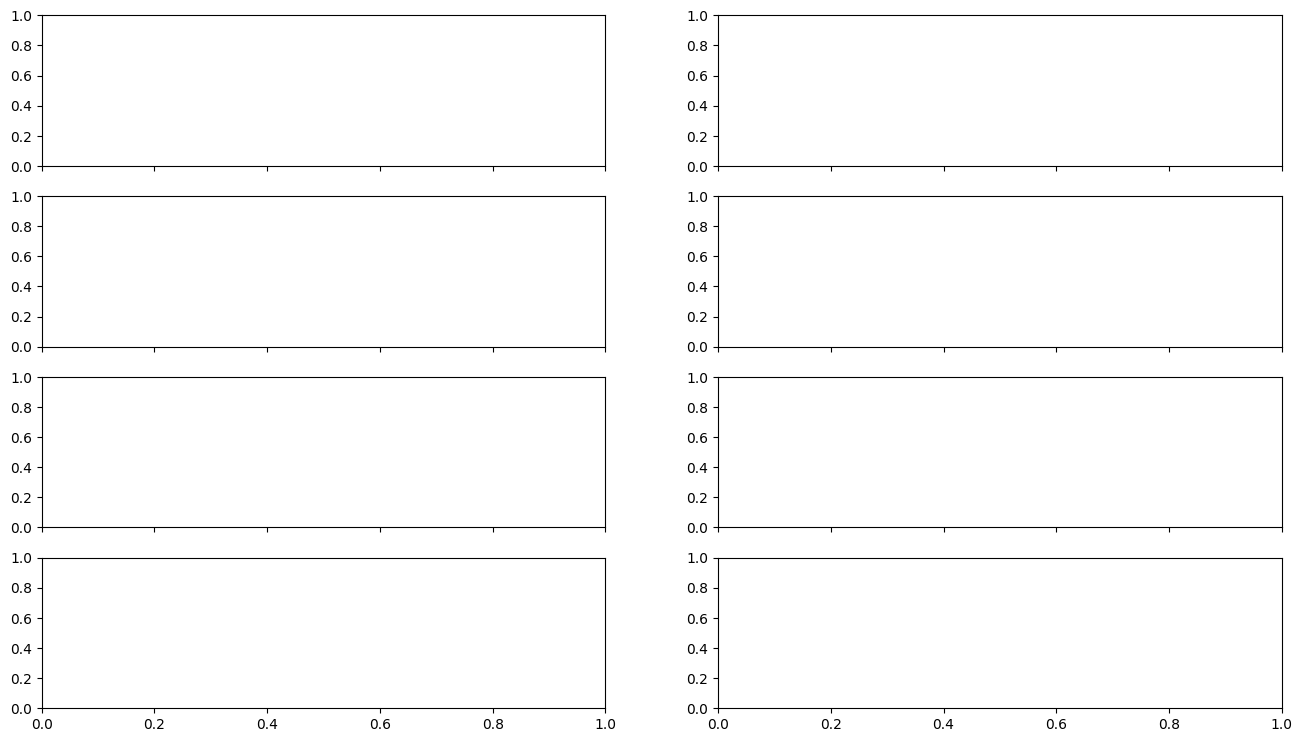

In [52]:
# Seasonality: the room temperature and the bearing temperature with a 24-hour period
ts = hourly.set_index("timestamp")
fig, axes = plt.subplots(4, 2, figsize=(16, 9), sharex=True)
season_share = {}
for j, col in enumerate(["temp_ambient", "temp_bearing"]):
    dec = seasonal_decompose(ts[col], model="additive", period=24, extrapolate_trend="freq")
    for i, (part, name) in enumerate([(dec.observed, "observed"), (dec.trend, "trend"),
                                      (dec.seasonal, "seasonal (24 h)"), (dec.resid, "residual")]):
        axes[i, j].plot(part.index, part.values, lw=1.2, color=["#33415c", "#3d5a80", "#2a9d8f", "#999"][i])
        axes[i, j].set_ylabel(name)
    axes[0, j].set_title(f"seasonal_decompose of {LABELS[col]}")
    season_share[col] = dec.seasonal.var() / dec.observed.var()
plt.tight_layout(); plt.show()
print("Share of variance explained by the daily (24 h) component:", {k: f"{v:.1%}" for k, v in season_share.items()})

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
plot_acf(hourly["x_rms"], lags=36, ax=axes[0], title="ACF – hourly RMS x")
plot_acf(hourly["temp_ambient"], lags=36, ax=axes[1], title="ACF – ambient temperature")
# cross-correlation (Lecture 14) of hour-to-hour CHANGES during healthy operation: do vibration and heat move together?
healthy_h = hourly.loc[RUN_IN:P_HOUR - 1]
dv, dt_ = healthy_h["y_rms"].diff().dropna(), healthy_h["temp_rise"].diff().dropna()
lags = np.arange(-6, 7)
xc = [dv.corr(dt_.shift(-l)) for l in lags]
axes[2].bar(lags, xc, color=np.where(lags == lags[np.nanargmax(np.abs(xc))], "#d1495b", "#98c1d9"))
axes[2].axhline(1.96 / np.sqrt(len(dv)), ls="--", color="#555", lw=0.8); axes[2].axhline(-1.96 / np.sqrt(len(dv)), ls="--", color="#555", lw=0.8)
axes[2].set(xlabel="lag [h]  (positive: vibration change precedes temperature change)", ylabel="correlation",
            title="Cross-correlation of hourly changes, RMS y vs ΔT (healthy stage)")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – time series and trends
* **Daily summaries:** days 1–5 have nearly constant vibration (mean RMS x 0.30–0.36 g, slowly *decreasing*) while the mean bearing
  temperature rises from 34.8 °C to 46.4 °C. Day 6 is the failure: mean RMS 0.74 g (max 1.44 g) and temperature up to 103 °C.
* **Step changes**, not smooth trends, dominate the healthy life: around hours 45, 72 and 93 the vertical (y) vibration and the
  temperature jump together. The cross-correlation of hourly changes is significant **only at lag 0** (r ≈ 0.34): heat and vibration
  change *at the same time*, which points to a common cause such as an operating-condition change, not to damage growth.
* **Prognostic ranking:** the best-scoring indicators are the 1–3 kHz band energies (score ≈ 0.7, a slow monotonic decline) and the
  bearing temperature (trendability 0.88, but low monotonicity because of the steps). No indicator is monotonic *and* robust –
  typical of real run-to-failure data.
* **Seasonality:** the daily (24 h) component explains only 17 % of the ambient and 8 % of the bearing-temperature variance; the steps
  are not daily. The ACF shows that RMS "remembers" only 2–3 hours, while ambient temperature drifts slowly.

### 5.2 Frequency-domain exploration: what kind of damage is it?
Spectra show *where* the energy is. A localized defect produces impacts at its defect frequency; in the **envelope
spectrum** these appear as peaks at BPFO / BPFI / BSF (Section 1.2.5) and their harmonics.

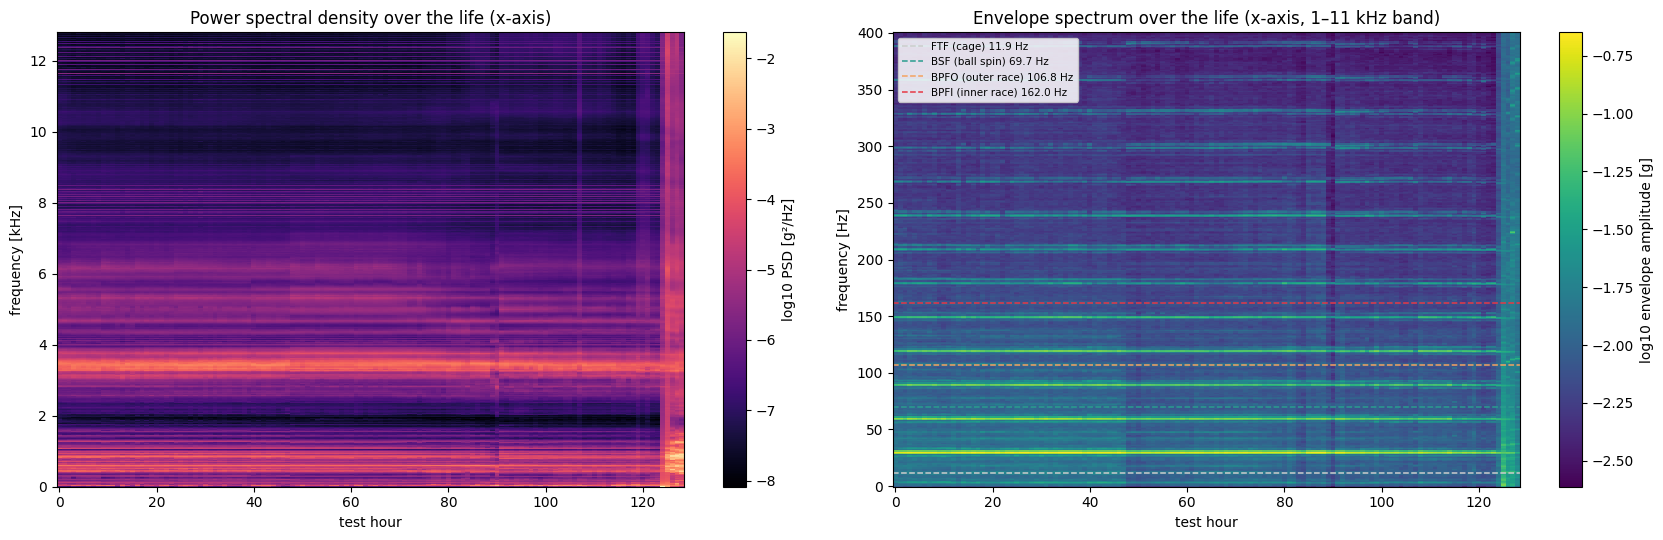

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure bearing defect multipliers are defined
FAULT_COEF = {
    "FTF (cage)":        0.397,
    "BSF (ball spin)":   2.334,
    "BPFO (outer race)": 3.577,
    "BPFI (inner race)": 5.423,
}

psd_x = psd[psd["axis"] == "x"].set_index("hour").drop(columns="axis")
freqs = psd_x.columns.astype(float) + 12.5            # bin centres (25 Hz bins)
env_x = envspec[envspec["axis"] == "x"].set_index("hour").drop(columns="axis")
fenv = env_x.columns.astype(float)
fr_med = meta["shaft_hz"].median()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
im = axes[0].pcolormesh(psd_x.index, freqs / 1000, np.log10(psd_x.T.to_numpy() + 1e-12), shading="nearest", cmap="magma")
plt.colorbar(im, ax=axes[0], label="log10 PSD [g²/Hz]")
axes[0].set(xlabel="test hour", ylabel="frequency [kHz]", title="Power spectral density over the life (x-axis)")
m = fenv <= 400
im2 = axes[1].pcolormesh(env_x.index, fenv[m], np.log10(env_x.loc[:, m].T.to_numpy() + 1e-6), shading="nearest", cmap="viridis")
plt.colorbar(im2, ax=axes[1], label="log10 envelope amplitude [g]")
for (name, coef), col in zip(FAULT_COEF.items(), ["#cccccc", "#2a9d8f", "#f4a261", "#e63946"]):
    axes[1].axhline(coef * fr_med, color=col, ls="--", lw=1.1, label=f"{name} {coef * fr_med:.1f} Hz")
axes[1].set(xlabel="test hour", ylabel="frequency [Hz]", title="Envelope spectrum over the life (x-axis, 1–11 kHz band)")
axes[1].legend(loc="upper left", fontsize=7.5, framealpha=0.85)
plt.tight_layout(); plt.show()

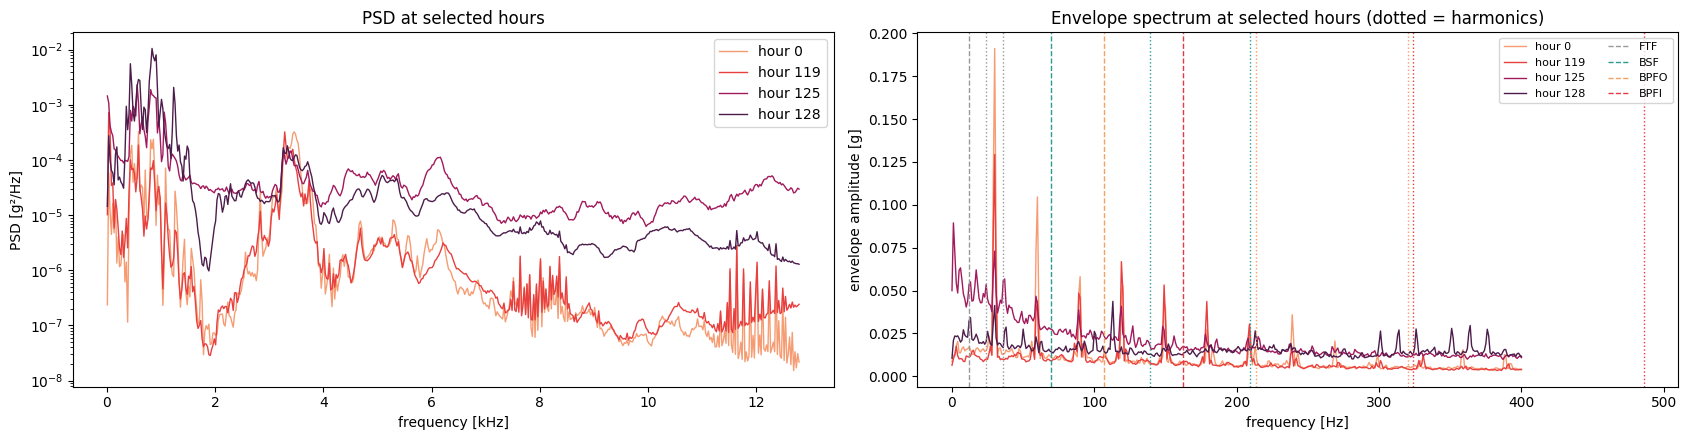

,FTF SNR,BPFO SNR,BPFI SNR,BSF SNR
stage,,,,
Run-in,2.93,2.61,1.69,2.02
Healthy,2.85,2.35,1.57,2.01
Degrading,2.50,2.11,1.60,1.89
Failure,3.67,1.64,1.40,1.90


In [56]:
picks = [0, int(stage_start.get("Degrading", T_EOL // 2)), T_EOL - 3, T_EOL]
picks = sorted(set(min(max(p, 0), T_EOL) for p in picks))
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for h, color in zip(picks, sns.color_palette("rocket_r", len(picks))):
    axes[0].semilogy(freqs / 1000, psd_x.loc[h], lw=1, color=color, label=f"hour {h}")
    axes[1].plot(fenv[m], env_x.loc[h, m], lw=1, color=color, label=f"hour {h}")
for (name, coef), col in zip(FAULT_COEF.items(), ["#999", "#2a9d8f", "#f4a261", "#e63946"]):
    for k in (1, 2, 3):
        axes[1].axvline(k * coef * fr_med, color=col, ls=":" if k > 1 else "--", lw=1,
                        label=name.split()[0] if k == 1 else None)
axes[0].set(xlabel="frequency [kHz]", ylabel="PSD [g²/Hz]", title="PSD at selected hours"); axes[0].legend()
axes[1].set(xlabel="frequency [Hz]", ylabel="envelope amplitude [g]", title="Envelope spectrum at selected hours (dotted = harmonics)")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

# which defect line dominates in each stage? (mean SNR of the fundamental)
snr_cols = [c for c in feat.columns if c.startswith("x_env_") and c.endswith("_snr")]
feat.groupby("stage", observed=False)[snr_cols].mean().rename(columns=lambda c: c.replace("x_env_", "").replace("_snr", "").upper() + " SNR").round(2)

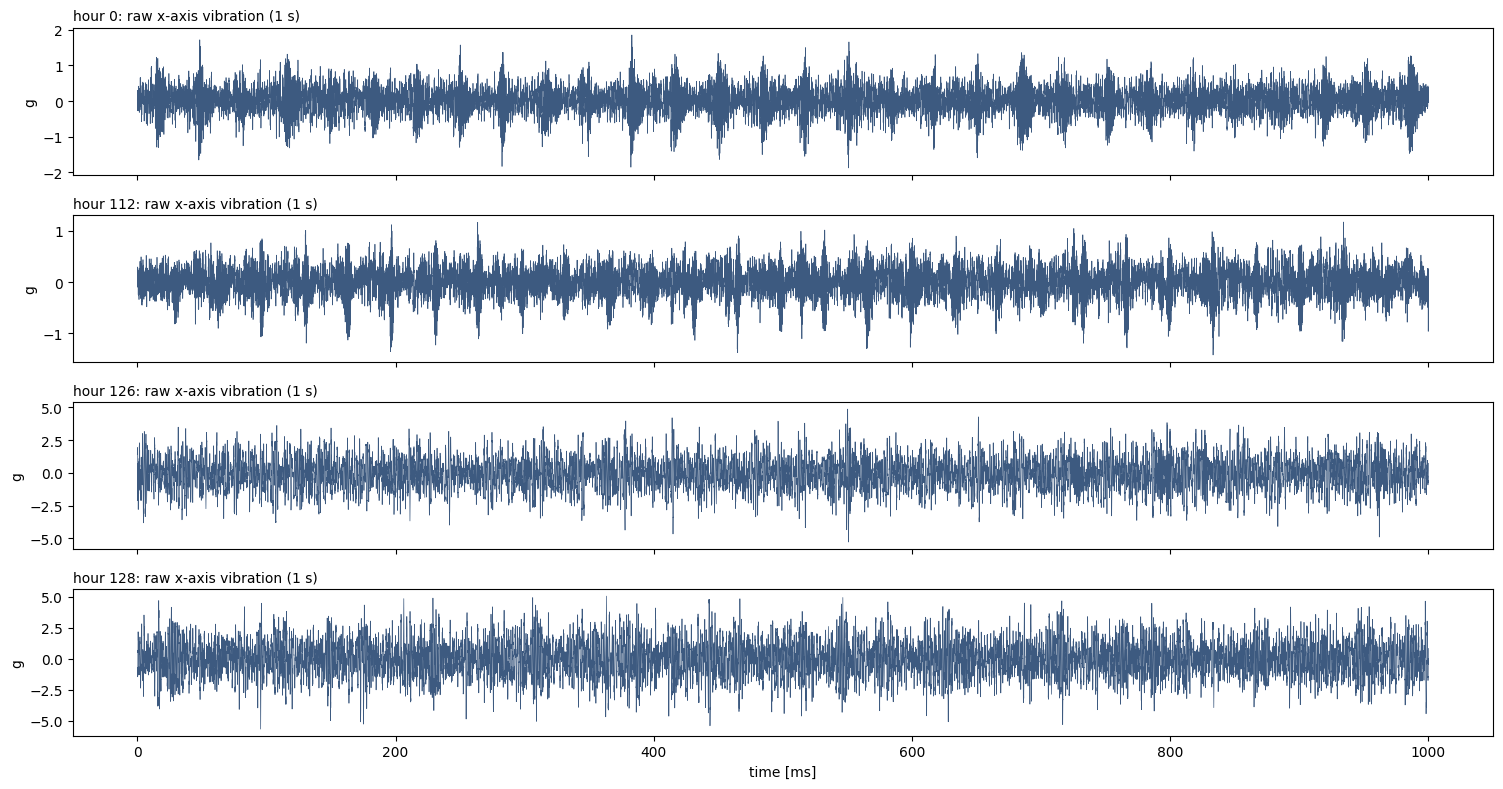

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Fallback data loading configuration
REPO_RAW = "https://raw.githubusercontent.com/alsulami412-arch/ISE518-Bearing-RUL/main/"
DATA_URL = REPO_RAW + "data/processed/"
LOCAL_DATA = Path("data/processed")

def load_csv_fallback(name, **kwargs):
    local = LOCAL_DATA / name
    return pd.read_csv(local if local.exists() else DATA_URL + name, **kwargs)

# Ensure raw signal excerpts are loaded
try:
    raw = load_csv_fallback("raw_excerpts.csv.gz")
except Exception as e:
    print(f"Error loading raw excerpts: {e}")

# Consistent visualization colors
AXIS_COLORS = {"x": "#3d5a80", "y": "#ee6c4d"}

hours_show = sorted(raw["hour"].unique())
sel = [hours_show[0], hours_show[len(hours_show) // 2], hours_show[-3], hours_show[-1]]
fig, axes = plt.subplots(len(sel), 1, figsize=(15, 8), sharex=True)
for ax, h in zip(axes, sel):
    seg = raw[raw["hour"] == h]
    ax.plot(seg["t_s"] * 1000, seg["vib_x"], lw=0.5, color=AXIS_COLORS["x"])
    ax.set_ylabel("g"); ax.set_title(f"hour {h}: raw x-axis vibration (1 s)", loc="left", fontsize=10)
axes[-1].set_xlabel("time [ms]")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – frequency domain
* The PSD is dominated by stable structural resonances near **3.0–3.6 kHz and 5–6.5 kHz** throughout the life. The spectrum changes
  briefly around hour 90 and broadly after hour 123, when energy below 1.5 kHz rises.
* The envelope spectrum is dominated by **1× shaft speed (29.9 Hz) and its harmonics** (60, 90 … 300 Hz) for the whole life. The defect
  lines (BPFO 106.8 Hz, BPFI 162.0 Hz, BSF 69.7 Hz) never stand out: their SNR stays at 1.4–2.6 in every stage.
  After failure the **cage frequency** (FTF ≈ 12 Hz) SNR rises to 3.7, consistent with a damaged ball disturbing the cage.
* This agrees with the article's post-mortem (spalls on both races, a crack and a damaged ball) and with its remark that the spall
  signature faded as the damage smoothed out. The damage did not leave a clean localized-fault signature in this band.
* **Implication:** classic envelope analysis at the defect frequencies would not have warned us here. Broadband and thermal
  indicators carry the useful information.

### 5.3 Anomalies and potential biases

In [59]:
def first_alarm(series, k=3.0, persist=2, base=BASE_HOURS):
    """First hour (after run-in) from which |robust z| > k for `persist` consecutive hours."""
    return first_persistent(robust_z(series, base).abs() > k, persist=persist)

BASE = slice(*BASE_HOURS)
anom = pd.DataFrame({"first persistent anomaly (hour)": {LABELS.get(c, c): first_alarm(hourly[c])
                                                          for c in ["x_rms", "y_rms", "x_kurtosis", "x_crest", "x_b3_rms",
                                                                    "x_env_rms", "x_env_bpfo", "x_env_bpfi", "x_env_bsf",
                                                                    "temp_bearing", "temp_rise", "rpm"]}})
anom["hours before end of life"] = T_EOL - anom["first persistent anomaly (hour)"]
anom["verdict"] = np.where(anom["first persistent anomaly (hour)"] < P_HOUR - 6, "early alarm in healthy operation (false alarm)",
                           np.where(anom["first persistent anomaly (hour)"].isna(), "never", "pre-failure warning"))
anom.sort_values("first persistent anomaly (hour)")

,first persistent anomaly (hour),hours before end of life,verdict
envelope BSF x [g],87,41,early alarm in healthy operation (false alarm)
envelope BPFO x [g],89,39,early alarm in healthy operation (false alarm)
temperature rise Delta T [degC],106,22,early alarm in healthy operation (false alarm)
crest factor x,115,13,pre-failure warning
kurtosis x,115,13,pre-failure warning
bearing temperature [degC],119,9,pre-failure warning
speed S(t) [rpm],119,9,pre-failure warning
3-6 kHz band RMS x [g],121,7,pre-failure warning
RMS x [g],124,4,pre-failure warning
envelope BPFI x [g],124,4,pre-failure warning


#### 🔎 Key findings – anomalies and potential biases
* Univariate robust 3σ alarms (2 consecutive hours) show the dilemma of single indicators: the envelope BSF/BPFO amplitudes (hours 87–89)
  and the temperature rise (hour 106) alarm **during healthy operation** (operating-regime steps), whereas RMS alarms only at hour 124 –
  one hour before the stop criterion. Bearing temperature and speed both alarm at **hour 119**.
* **Potential biases and limitations of the data:**
  * **one specimen** – no information about life scatter between bearings or other loads and speeds;
  * **operating regimes** (steps around hours 45, 72 and 93) that look like anomalies but are not damage;
  * **start-up transient** (hours 0–7) and the **5-min/15-min duty cycle**: each 78-s snapshot catches the bearing at a different
    point of its heating cycle (within-file temperature standard deviation up to 1.8 °C in healthy hours, 6.4 °C at hour 124);
  * **ambient drift** late in the test (confounder of the bearing temperature);
  * **class imbalance** (8 % of hours in Degrading/Failure) and **hourly sampling**, which cannot resolve events shorter than an hour;
  * a few **saturated samples** (hour 124) and a speed that is *estimated*, not measured.

---
## 6️⃣ 6. Visualization
The dashboard-style figure that brings the EDA together, and what the EDA implies for preprocessing, feature selection and model development.


### 6.1 📊 EDA dashboard (EDA brief, step 6)
One figure that summarizes the life of the bearing for a maintenance engineer.

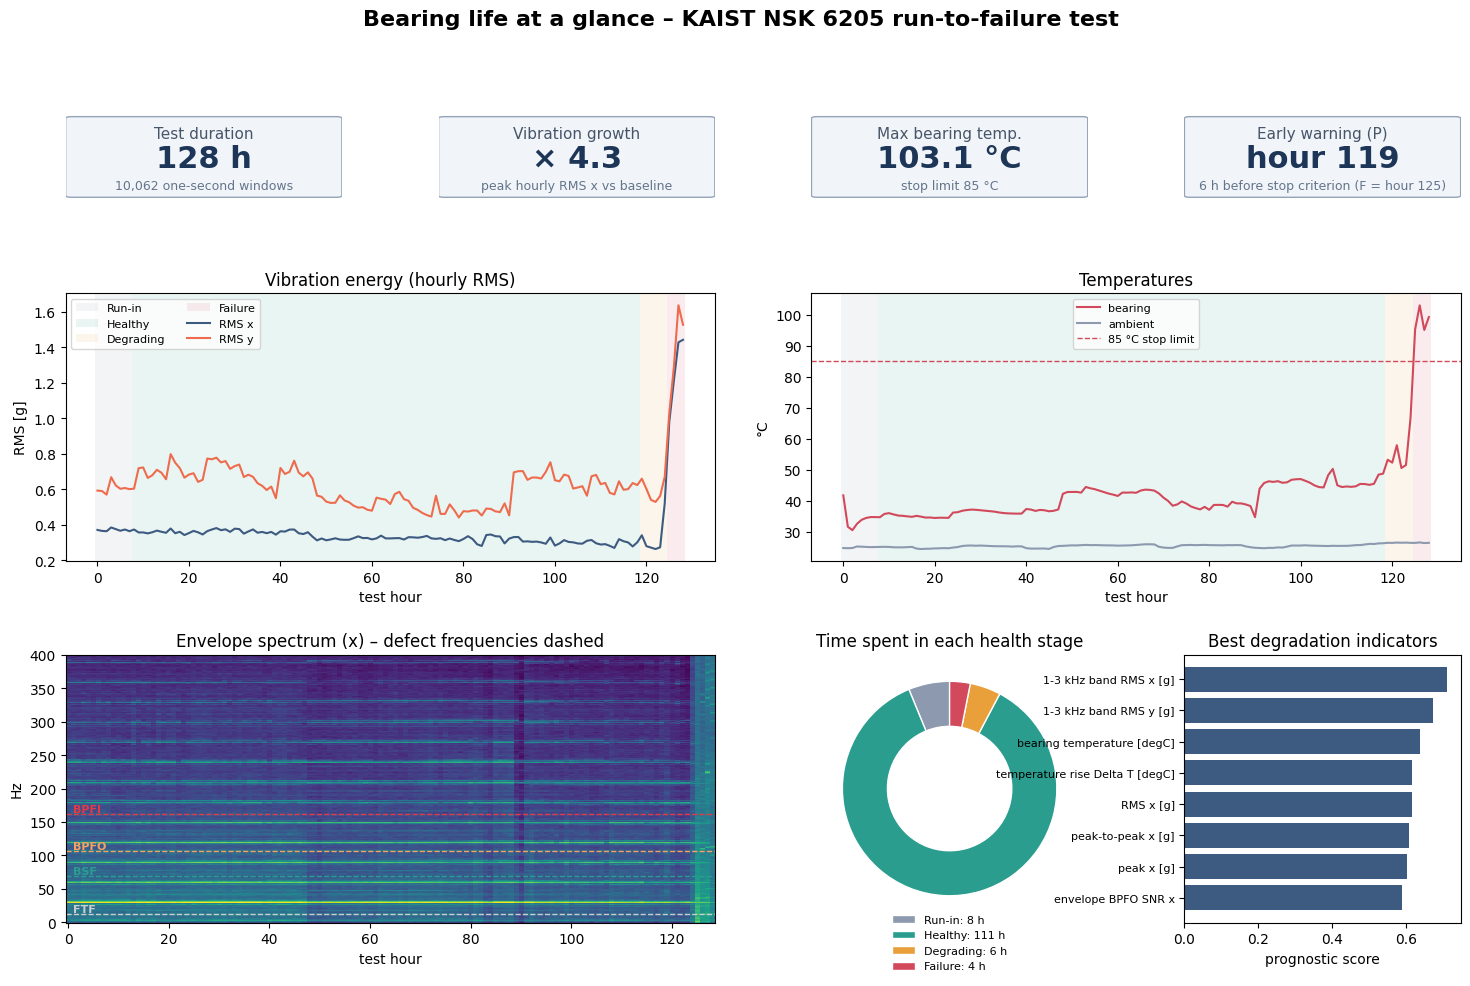

In [64]:
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
import matplotlib.pyplot as plt

def eda_dashboard():
    FAIL_TEMP_C = 85.0
    fig = plt.figure(figsize=(18, 10.5))
    gs = gridspec.GridSpec(3, 4, figure=fig, height_ratios=[0.32, 1, 1], hspace=0.45, wspace=0.35)
    base_rms = hourly["x_rms"].loc[BASE].median()
    kpis = [("Test duration", f"{T_EOL} h", f"{len(feat):,} one-second windows"),
            ("Vibration growth", f"× {hourly['x_rms'].max() / base_rms:.1f}", "peak hourly RMS x vs baseline"),
            ("Max bearing temp.", f"{hourly['temp_bearing'].max():.1f} °C", f"stop limit {FAIL_TEMP_C:.0f} °C"),
            ("Early warning (P)", f"hour {P_HOUR}", f"{F_HOUR - P_HOUR} h before stop criterion (F = hour {F_HOUR})")]
    for i, (title, value, sub) in enumerate(kpis):
        ax = fig.add_subplot(gs[0, i]); ax.axis("off")
        ax.add_patch(FancyBboxPatch((0.02, 0.05), 0.96, 0.9, boxstyle="round,pad=0.02", fc="#f1f5f9", ec="#94a3b8",
                                    transform=ax.transAxes))
        ax.text(0.5, 0.72, title, ha="center", fontsize=11, color="#475569", transform=ax.transAxes)
        ax.text(0.5, 0.38, value, ha="center", fontsize=22, weight="bold", color="#1d3557", transform=ax.transAxes)
        ax.text(0.5, 0.13, sub, ha="center", fontsize=9, color="#64748b", transform=ax.transAxes)
    ax1 = fig.add_subplot(gs[1, :2]); shade_stages(ax1)
    ax1.plot(hourly.index, hourly["x_rms"], color=AXIS_COLORS["x"], label="RMS x")
    ax1.plot(hourly.index, hourly["y_rms"], color=AXIS_COLORS["y"], label="RMS y")
    ax1.set(title="Vibration energy (hourly RMS)", xlabel="test hour", ylabel="RMS [g]")
    ax1.legend(loc="upper left", fontsize=8, ncol=2)
    ax2 = fig.add_subplot(gs[1, 2:]); shade_stages(ax2, label=False)
    ax2.plot(hourly.index, hourly["temp_bearing"], color="#d1495b", label="bearing")
    ax2.plot(hourly.index, hourly["temp_ambient"], color="#8d99ae", label="ambient")
    ax2.axhline(FAIL_TEMP_C, ls="--", color="#d1495b", lw=1, label="85 °C stop limit")
    ax2.set(title="Temperatures", xlabel="test hour", ylabel="°C"); ax2.legend(fontsize=8)
    ax3 = fig.add_subplot(gs[2, :2])
    ax3.pcolormesh(env_x.index, fenv[m], np.log10(env_x.loc[:, m].T.to_numpy() + 1e-6), shading="nearest", cmap="viridis")
    for (name, coef), col in zip(FAULT_COEF.items(), ["#ccc", "#2a9d8f", "#f4a261", "#e63946"]):
        ax3.axhline(coef * fr_med, color=col, ls="--", lw=1)
        ax3.text(1, coef * fr_med + 3, name.split()[0], color=col, fontsize=8, weight="bold")
    ax3.set(title="Envelope spectrum (x) – defect frequencies dashed", xlabel="test hour", ylabel="Hz")
    ax4 = fig.add_subplot(gs[2, 2])
    local_counts_stage = hourly["stage"].value_counts(sort=False)
    sc = local_counts_stage.reindex(STAGE_ORDER)
    ax4.pie(sc, colors=[STAGE_COLORS[s] for s in STAGE_ORDER], wedgeprops=dict(width=0.42, edgecolor="white"), startangle=90)
    ax4.legend([f"{s}: {n} h" for s, n in sc.items()], loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=1, fontsize=8, frameon=False)
    ax4.set_title("Time spent in each health stage")
    ax5 = fig.add_subplot(gs[2, 3])
    top = ps.head(8)["score"][::-1]
    ax5.barh([LABELS.get(i, i) for i in top.index], top.values, color="#3d5a80")
    ax5.set(title="Best degradation indicators", xlabel="prognostic score"); ax5.tick_params(axis="y", labelsize=8)
    fig.suptitle("Bearing life at a glance – KAIST NSK 6205 run-to-failure test", fontsize=16, weight="bold")
    plt.show()

eda_dashboard()

#### 🔎 Key findings – EDA dashboard (EDA instruction 6)
* One `matplotlib` figure (a grid of subplots) combines four KPI tiles – test duration, vibration growth, maximum bearing
  temperature and the early-warning point P (hour 119, 6 h before the stop criterion) – with five plots: hourly vibration RMS,
  bearing and ambient temperature, the envelope spectrum with the defect frequencies, the time spent in each health stage, and the
  best degradation indicators.
* Read together, the panels tell the story of the whole EDA: the temperature rises hours before the vibration does, the bearing
  defect frequencies never dominate the envelope spectrum, and most of the test is spent in the healthy stage, so the degraded
  classes are rare.
* **Implication:** friction-based indicators (temperature rise and speed drop) are the most promising inputs for detection, and the
  class imbalance must be handled in the models (Section 7). The same story is available interactively in the dashboard of Section 7.11.

### 6.2 Implications for preprocessing, feature selection and model development

| Area | What the EDA showed | Decision for Section 7 |
|---|---|---|
| **Preprocessing** | heavy right tails, outliers = failure | log-transform vibration indicators; robust (median/MAD) scaling fitted on the healthy baseline only; keep outliers |
| | start-up transient, operating regimes | exclude hours 0–7; baseline must span hours 8–100 (all regimes) |
| | room temperature is a confounder | use the temperature *rise* ΔT, not the raw bearing temperature |
| **Feature selection** | ΔT and speed separate degrading from healthy (effect size ≈ 1); vibration does not until hour 124 | build a physics-based **friction index**; compare *physics*, *vibration-only* and *all* input sets |
| | x and y vibration are redundant (r = 0.86); envelope defect lines carry no signal | let PCA / regularization handle redundancy rather than hand-picking |
| **Model development** | ordinal target whose warning levels cover 10 % of the windows; one life | ordinal models and ordinal metrics (quadratic-weighted κ, error in levels), warning recall and false-warning rate, not accuracy; time-blocked purged validation |
| | RUL is flat, then collapses (non-linear) | piecewise-linear RUL target; non-linear and interpretable models compared |
| | failure states are rare and unique | prefer models that extrapolate monotonically; report interpolation *and* extrapolation results |

---
## 7️⃣ 7. Beyond the EDA: models, evaluation and the interactive dashboard
The EDA (Sections 1–6) is complete. This section keeps the machine-learning steps of the project, because the interactive dashboard for the DCS operators is built from their results.

### Model development (Step 5 of the 7-step procedure)
*"Torture your data until it confesses."* Following the No-Free-Lunch theorem (Lecture 16), we try several model families
for each question and let the evaluation decide.

| Question | Approach | Models compared |
|---|---|---|
| **Q1 – When does degradation start?** (early detection) | unsupervised health indicators + alarm threshold fitted on the healthy baseline | univariate 3σ rules (RMS, kurtosis), vibration health index (Mahalanobis distance), Isolation Forest, physics-based friction index |
| **Q4 – Ŷ(t) = f(X(t))**: which of the four ordered machine statuses applies now? | supervised **ordinal** classification | multinomial logistic regression (ignores the order), ordinal logistic regression (proportional odds, `statsmodels`), random forest, status from a predicted RUL, and a conservative combination |
| **Q3 – How many hours are left?** | supervised regression of a piecewise-linear RUL target, plus a model-based alternative | naive baseline, ridge, k-NN, random forest, gradient boosting, MLP neural network; exponential degradation model |

#### Why supervised learning for RUL and status, and unsupervised learning only for detection
The type of learning follows from the question (course slides on supervised versus unsupervised learning, Lecture 13):

* **Q3 (RUL) and Q4 (machine status) are supervised.** The run-to-failure test gives a label for every hour: the hours left until
  the end of life, and the machine status derived from them. RUL is therefore a supervised **regression** problem and the status a
  supervised **classification** problem, the "predicted RUL value" and "predicted label / state" outputs of the supervised-learning
  slide.
* **Q1 (early detection) has to work without failure labels.** A machine in service has not failed yet, so there are no labels to
  learn from. The usual approach is to learn what *healthy* looks like and raise an alarm when the machine moves away from it: the
  "likelihood" output of the unsupervised-learning slide. We therefore test two unsupervised health indicators trained on healthy
  hours only (Mahalanobis distance after PCA, and Isolation Forest), next to simple 3σ rules and the physics-based friction index.
* **Compare, then decide (No-Free-Lunch, Lecture 16).** Section 7.2 gives the result: the unsupervised indicators alarm at hours
  76–77 with 25 false-alarm hours during healthy operation, because they treat normal changes in operating conditions as faults.
  The friction index alarms at hour 119 with none, so the final system uses the **friction index for detection** and **supervised
  models for the machine status and the RUL**. The K-means check in Sections 3–6 explains why: the largest source of variation in the
  data is the operating regime, not the bearing's health.

**In short:** RUL and machine status are supervised because the test provides a label for every hour; early detection had to work
without failure labels, so unsupervised detectors were tested and then rejected in favour of the physics-based friction index.

#### How we validate with a single bearing
There is only one run-to-failure, so we cannot test on a second bearing. We use **purged, time-blocked cross-validation**:
the test block is removed from training together with one hour on each side. Two block sizes answer two different questions:

* **Interpolation test (3-hour blocks).** The model has seen the hours around the test block. This is the *optimistic* case,
  similar to a fleet where comparable failures have already been recorded.
* **Extrapolation test (8-hour blocks).** Whole phases of the life disappear from training, including most of the failure
  stage. This is the *realistic* case for a failure that has never been seen before.

In [65]:
VIB = [c for c in FEATURES if c.startswith(("x_", "y_")) and not c.endswith("_mean")]   # vibration-only inputs
use = feat["hour"] >= RUN_IN                                                            # run-in hours never used
base_win = feat["hour"].between(*BASE_HOURS)

# physics inputs at window level: robust z-scores of temperature rise and speed drop vs the healthy baseline
for col, sign, name in (("temp_rise", 1, "z_temp_rise"), ("rpm", -1, "z_speed_drop")):
    ref = feat.loc[base_win, col]
    feat[name] = sign * (feat[col] - ref.median()) / (1.4826 * (ref - ref.median()).abs().median())
PHYS = ["z_temp_rise", "z_speed_drop"]
ALL = VIB + PHYS

def blocked_cv_predict(model, X, y, block_hours, proba=False, purge=1, sub=10):
    """Out-of-fold predictions with purged time blocks.
    Each block of `block_hours` hours is predicted by a model that never saw it nor `purge` hours on each side.
    Training uses every `sub`-th window (windows of one hour are nearly identical; this keeps it fast).
    proba=True returns one column of class probabilities per class (classes absent from a training fold get 0)."""
    X, y = np.asarray(X), np.asarray(y)
    classes = np.unique(y[use.to_numpy()]) if proba else None
    out = np.full((len(y), len(classes)), np.nan) if proba else np.full(len(y), np.nan)
    groups = feat["hour"] // block_hours
    for g in np.unique(groups[use]):
        test = (use & (groups == g)).to_numpy()
        h_lo, h_hi = feat.loc[test, "hour"].min() - purge, feat.loc[test, "hour"].max() + purge
        train = (use & ~feat["hour"].between(h_lo, h_hi) & (feat["window"] % sub == 0)).to_numpy()
        if proba:
            P = np.zeros((int(test.sum()), len(classes)))
            seen = np.unique(y[train])
            if len(seen) < 2:                            # a single class in training: predict it with certainty
                P[:, np.searchsorted(classes, seen[0])] = 1.0
            else:
                model.fit(X[train], y[train])
                P[:, np.searchsorted(classes, model.classes_)] = model.predict_proba(X[test])
            out[test] = P
        else:
            model.fit(X[train], y[train])
            out[test] = model.predict(X[test])
    return out

print(f"vibration features: {len(VIB)} | physics features: {PHYS} | windows used: {int(use.sum()):,}")

vibration features: 56 | physics features: ['z_temp_rise', 'z_speed_drop'] | windows used: 9,438


### 7.1 Health indicators
* **Vibration health index (HI)** – all vibration indicators are log-transformed, standardized with the healthy baseline,
  de-correlated with PCA (95 % variance) and combined into the **Mahalanobis distance** from the healthy state (Lecture 13).
* **Isolation Forest score** – an anomaly score learned on the healthy windows (Lectures 12–13).
* **Friction index** – the physics-based indicator defined in Section 2.7.

PCA kept 24 components for the vibration HI


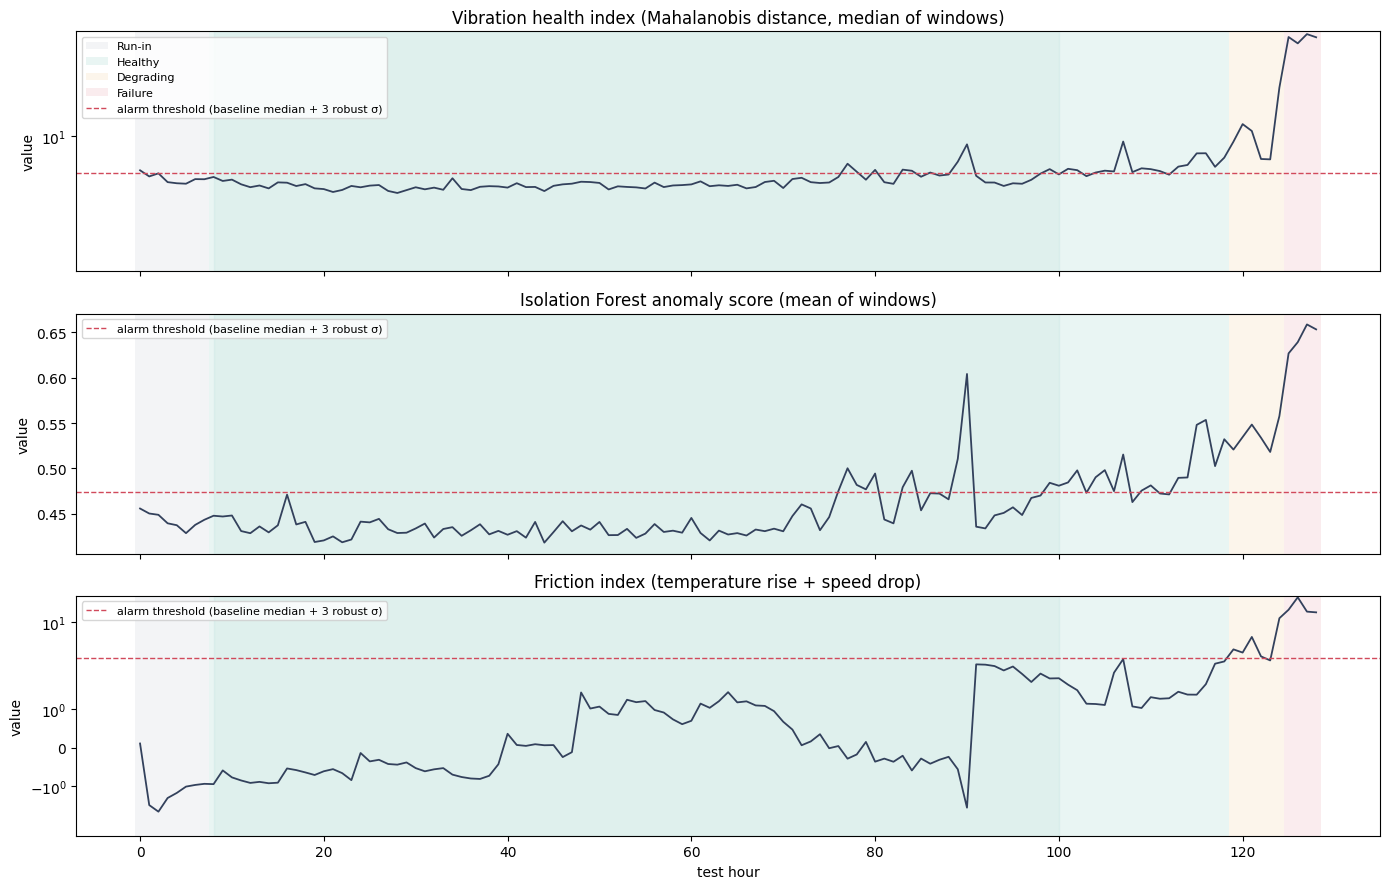

In [67]:
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Xv = feat[VIB].copy()
positive = [c for c in VIB if (feat[c] > 0).all()]
Xv[positive] = np.log(Xv[positive])                                  # tame the heavy right tails (Section 4.1)
Zv = (Xv - Xv[base_win].mean()) / Xv[base_win].std()
pca_hi = PCA(n_components=0.95, random_state=RNG).fit(Zv[base_win])
scores_w = pca_hi.transform(Zv) / np.sqrt(pca_hi.explained_variance_)
feat["HI_vib"] = np.sqrt((scores_w ** 2).sum(axis=1))                 # Mahalanobis distance in PCA space
iso = IsolationForest(n_estimators=300, random_state=RNG).fit(Zv[base_win])
feat["iso_score"] = -iso.score_samples(Zv)                            # larger = more anomalous

hi = feat.groupby("hour").agg(HI_vib=("HI_vib", "median"), iso_score=("iso_score", "mean"))
hi["friction_index"] = hourly["friction_index"]
print(f"PCA kept {pca_hi.n_components_} components for the vibration HI")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, col, title in zip(axes, ["HI_vib", "iso_score", "friction_index"],
                          ["Vibration health index (Mahalanobis distance, median of windows)",
                           "Isolation Forest anomaly score (mean of windows)", "Friction index (temperature rise + speed drop)"]):
    shade_stages(ax, label=(col == "HI_vib"))
    if col == "friction_index":
        thr = 3.0                                    # the friction index is already a robust z-score (Section 3.7)
    else:
        thr = hi[col].loc[BASE].median() + 3 * 1.4826 * (hi[col].loc[BASE] - hi[col].loc[BASE].median()).abs().median()
    ax.plot(hi.index, hi[col], color="#33415c", lw=1.3)
    ax.axhline(thr, ls="--", color="#d1495b", lw=1, label="alarm threshold (baseline median + 3 robust σ)")
    ax.axvspan(*BASE_HOURS, color="#2a9d8f", alpha=0.05)
    ax.set_yscale("symlog" if col != "iso_score" else "linear")
    ax.set(title=title, ylabel="value"); ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("test hour")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – health indicators
* The **vibration HI** (24 principal components) and the **Isolation Forest** score both cross their thresholds repeatedly from
  about **hour 76**, long before any damage. They respond to the operating-regime changes, because a regime change *is* a large
  multivariate deviation from the baseline.
* The **friction index** stays inside its band during all healthy regimes, leaves it at **hour 119** (dipping just below the line at
  hours 122–123, when the temperature briefly fell) and rises above 10–20 robust σ in the failure hours.
* **Implication:** a generic data-driven HI measures "different from the baseline", which is not the same as "damaged". The physics-based
  indicator is selective because it measures the consequence of damage – friction.

### 7.2 Early fault detection (Q1)
An alarm is raised when an indicator stays above *baseline median + 3 robust σ* for **2 consecutive hours** after the run-in.
We record the alarm hour, how long before functional failure it came, and how many healthy hours exceeded the threshold
(false-alarm hours). We also repeat the exercise with a **short baseline** (hours 8–48) to show what happens when the baseline
does not contain all normal operating regimes.

In [68]:
detectors = {"RMS x (3σ rule)": hourly["x_rms"], "RMS y (3σ rule)": hourly["y_rms"],
             "Kurtosis x (3σ rule)": hourly["x_kurtosis"], "Vibration HI (Mahalanobis)": hi["HI_vib"],
             "Isolation Forest": hi["iso_score"], "Friction index (physics)": None}

def friction_index(base):
    """Friction index with its z-scores referenced to the given baseline hours (Section 3.7)."""
    return (robust_z(hourly["temp_rise"], base) - robust_z(hourly["rpm"], base)) / 2

def detector_z(name, base):
    """Alarm statistic: the friction index is already a z-score; the other indicators are standardized here."""
    return friction_index(base) if name.startswith("Friction") else robust_z(detectors[name], base)

def evaluate_detector(name, base):
    z = detector_z(name, base)
    alarm = first_persistent(z > 3)
    healthy = z.loc[RUN_IN:P_HOUR - 1]
    return {"alarm hour": alarm,
            "lead time to F [h]": (F_HOUR - alarm) if alarm is not None else None,
            "lead time to end of life [h]": (T_EOL - alarm) if alarm is not None else None,
            "false-alarm hours (healthy stage)": int((healthy > 3).sum())}

det_long = pd.DataFrame({k: evaluate_detector(k, BASE_HOURS) for k in detectors}).T
det_short = pd.DataFrame({k: evaluate_detector(k, (RUN_IN, 48)) for k in detectors}).T
detection = pd.concat({"baseline hours 8–100 (all regimes)": det_long, "baseline hours 8–48 (short)": det_short}, axis=1)
detection

baseline hours 8–100 (all regimes)  \
                                                   alarm hour   
RMS x (3σ rule)                                           124   
RMS y (3σ rule)                                           125   
Kurtosis x (3σ rule)                                      124   
Vibration HI (Mahalanobis)                                 77   
Isolation Forest                                           76   
Friction index (physics)                                  119   

                                                                            \
                           lead time to F [h] lead time to end of life [h]   
RMS x (3σ rule)                             1                            4   
RMS y (3σ rule)                             0                            3   
Kurtosis x (3σ rule)                        1                            4   
Vibration HI (Mahalanobis)                 48                           51   
Isolation Forest                           49                           52   
Friction index (physics)                    6                            9   

                                                              \
                           false-alarm hours (healthy stage)   
RMS x (3σ rule)                                            0   
RMS y (3σ rule)                                            0   
Kurtosis x (3σ rule)                                       0   
Vibration HI (Mahalanobis)                                25   
Isolation Forest                                          25   
Friction index (physics)                                   0   

                           baseline hours 8–48 (short)                     \
                                            alarm hour lead time to F [h]   
RMS x (3σ rule)                                    124                  1   
RMS y (3σ rule)                                    125                  0   
Kurtosis x (3σ rule)                               124                  1   
Vibration HI (Mahalanobis)                          77                 48   
Isolation Forest                                    76                 49   
Friction index (physics)                            48                 77   

                                                         \
                           lead time to end of life [h]   
RMS x (3σ rule)                                       4   
RMS y (3σ rule)                                       3   
Kurtosis x (3σ rule)                                  4   
Vibration HI (Mahalanobis)                           51   
Isolation Forest                                     52   
Friction index (physics)                             80   

                                                              
                           false-alarm hours (healthy stage)  
RMS x (3σ rule)                                            0  
RMS y (3σ rule)                                            0  
Kurtosis x (3σ rule)                                       0  
Vibration HI (Mahalanobis)                                32  
Isolation Forest                                          35  
Friction index (physics)                                  51

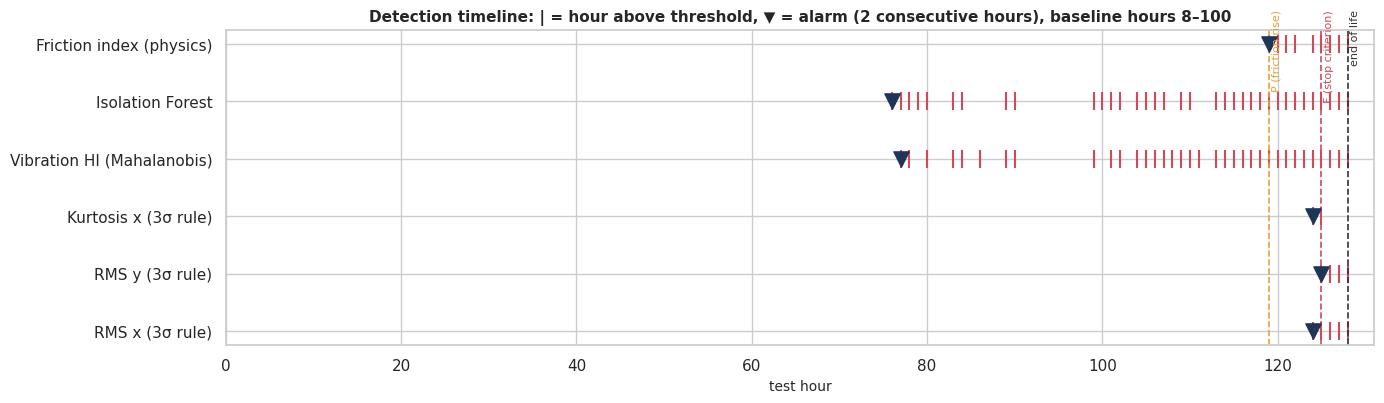

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.2))
for i, name in enumerate(detectors):
    z = detector_z(name, BASE_HOURS)
    hrs = z.index[(z > 3) & (z.index >= RUN_IN)]
    ax.scatter(hrs, [i] * len(hrs), marker="|", s=180, color="#d1495b")
    a = det_long.loc[name, "alarm hour"]
    if pd.notna(a):
        ax.scatter([a], [i], marker="v", s=120, color="#1d3557", zorder=3)
for x, lab, col in ((P_HOUR, "P (friction rise)", STAGE_COLORS["Degrading"]), (F_HOUR, "F (stop criterion)", STAGE_COLORS["Failure"]),
                    (T_EOL, "end of life", "#333")):
    ax.axvline(x, ls="--", color=col, lw=1.2); ax.text(x + 0.3, len(detectors) - 0.4, lab, color=col, fontsize=8, rotation=90, va="top")
ax.set(yticks=range(len(detectors)), yticklabels=list(detectors), xlabel="test hour", xlim=(0, T_EOL + 3),
       title="Detection timeline: | = hour above threshold, ▼ = alarm (2 consecutive hours), baseline hours 8–100")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – early detection (Q1)
* **Friction index: alarm at hour 119**, **6 h before the stop criterion** (F = 125) and 9 h before the end of the test, with
  **zero false-alarm hours** in healthy operation. (It also defined P in Section 2, so this row coincides with P by construction; the
  other rows show how much later or noisier the alternatives are.) The margin is thin, though: after the regime step at hour 91 the
  index climbed to ≈ 2.9, just below the threshold of 3.
* **Vibration RMS and kurtosis (classic 3σ trend alarms):** no false alarms, but they alarm only at hour 124–125, **0–1 h before F**.
  That is too late to plan anything.
* **Vibration HI and Isolation Forest:** alarm at hours 76–77 with **25 false-alarm hours**. They are sensitive but not specific.
* **Baseline sensitivity:** with a short baseline (hours 8–48) the friction index alarms at hour 48 with 51 false-alarm hours. The first
  regime step looks like damage if the baseline has never seen it. This is the "learning in non-stationary environments" problem of
  Lecture 16: **the baseline must represent all normal operating conditions**.
* **Answer to Q2:** the signals that reveal degradation first are the **temperature rise and the speed drop**, both consequences of friction.
* *Timing convention:* alarm hours are the **onset** of the 2-hour persistent exceedance. In real time the friction alarm is confirmed by
  the second record, at hour 120; the ordinal status of Section 7 already reports 🔻 Degraded at hour 119.

#### 7.2.1 Could we warn earlier? Lead time versus false alarms
The alarm uses a threshold of 3 robust σ. A lower threshold warns earlier, but the friction index also rose during healthy
operation: to ≈ 1.4 σ after the step at hour 48, to ≈ 2.5 σ after the operating step at hour 91 and to ≈ 2.9 σ during the
short spike at hour 107. We sweep the threshold from 1 to 4 σ (keeping the 2-hour persistence) and record, for each value, the
first warning inside the degradation period – from hour 116, when the machine status became 🔻 *Degraded* – and the false-alarm
episodes before it. Hours are **onset** hours: with a 2-hour persistence rule the warning is confirmed one hour later.

In [70]:
def alarm_runs(z, thr, start=RUN_IN, persist=2):
    """(first, last) hour of every run of at least `persist` consecutive hours with z > thr."""
    above = (z.loc[start:] > thr).astype(int)
    run_id = (above != above.shift()).cumsum()
    return [(int(g.index[0]), int(g.index[-1])) for _, g in above[above == 1].groupby(run_id[above == 1]) if len(g) >= persist]

DEGRADED_FROM = int(hourly.index[hourly["status_code"] >= 1].min())
sweep = []
for thr in np.round(np.arange(1.0, 4.001, 0.05), 2):
    runs_ = alarm_runs(hourly["friction_index"], thr)
    false_runs = [(a, min(b, DEGRADED_FROM - 1)) for a, b in runs_ if a < DEGRADED_FROM]
    onsets = [a for a, b in runs_ if a >= DEGRADED_FROM]
    sweep.append({"threshold": thr, "first warning (onset hour)": onsets[0] if onsets else np.nan,
                  "lead time to F [h]": F_HOUR - onsets[0] if onsets else np.nan,
                  "false-alarm episodes": len(false_runs), "false-alarm hours": sum(b - a + 1 for a, b in false_runs),
                  "false alarms at hours": ", ".join(f"{a}–{b}" for a, b in false_runs) or "–"})
sweep = pd.DataFrame(sweep)
outcome = sweep["first warning (onset hour)"].fillna(-1).astype(int).astype(str) + "|" + sweep["false alarms at hours"]
trade_off = (sweep.groupby((outcome != outcome.shift()).cumsum())
             .agg(**{"threshold range [robust σ]": ("threshold", lambda t: f"{t.min():.2f} – {t.max():.2f}"),
                     "first warning (onset hour)": ("first warning (onset hour)", "first"),
                     "lead time to F [h]": ("lead time to F [h]", "first"),
                     "false-alarm episodes": ("false-alarm episodes", "first"),
                     "false-alarm hours": ("false-alarm hours", "first"),
                     "false alarms at hours": ("false alarms at hours", "first")}))
trade_off = trade_off[trade_off["first warning (onset hour)"].notna()].reset_index(drop=True)

# Two-level alarm, as in statistical process control: a WATCH at the 2σ warning limit, an ALARM at the 3σ action limit
WATCH_SIGMA, ALARM_SIGMA = 2.0, 3.0
watch_runs = alarm_runs(hourly["friction_index"], WATCH_SIGMA)
WATCH_HOUR = next(a for a, b in watch_runs if a >= DEGRADED_FROM)
false_watch = [(a, b) for a, b in watch_runs if a < DEGRADED_FROM]
print(f"Watch at {WATCH_SIGMA:.0f} σ: first watch in the degradation period at hour {WATCH_HOUR} ({F_HOUR - WATCH_HOUR} h before F), "
      f"false watch episodes: {false_watch}")
print(f"Alarm at {ALARM_SIGMA:.0f} σ: hour {P_HOUR} ({F_HOUR - P_HOUR} h before F), no false alarm")
trade_off

Watch at 2 σ: first watch in the degradation period at hour 117 (8 h before F), false watch episodes: [(91, 95)]
Alarm at 3 σ: hour 119 (6 h before F), no false alarm


,threshold range [robust σ],first warning (onset hour),lead time to F [h],false-alarm episodes,false-alarm hours,false alarms at hours
0,1.40 – 1.45,116.0,9.0,2,14,"91–102, 106–107"
1,1.50 – 1.60,116.0,9.0,2,13,"91–101, 106–107"
2,1.65 – 1.70,117.0,8.0,2,12,"91–100, 106–107"
3,1.75 – 1.75,117.0,8.0,3,11,"91–96, 98–100, 106–107"
4,1.80 – 1.90,117.0,8.0,2,8,"91–96, 106–107"
5,1.95 – 2.00,117.0,8.0,1,5,91–95
6,2.05 – 2.30,117.0,8.0,1,3,91–93
7,2.35 – 2.40,117.0,8.0,1,2,91–92
8,2.45 – 2.50,117.0,8.0,0,0,–
9,2.55 – 2.70,118.0,7.0,0,0,–


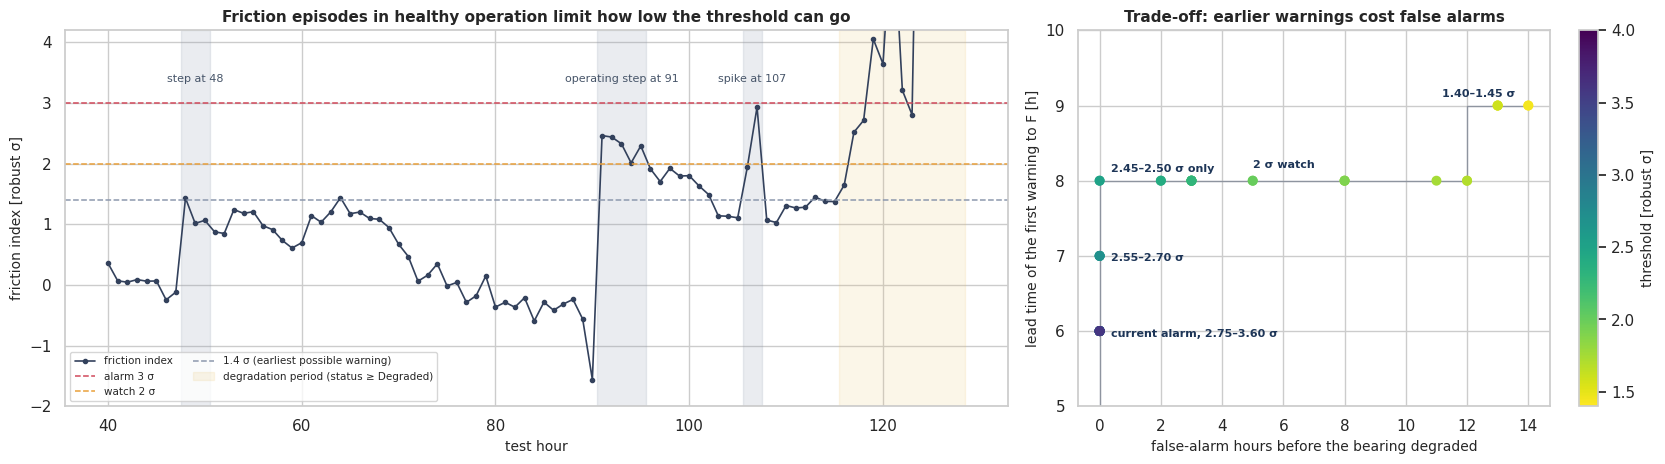

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
seg = hourly.loc[40:]
ax.plot(seg.index, seg["friction_index"], "o-", ms=3, lw=1.2, color="#33415c", label="friction index")
for thr, col, lab in ((ALARM_SIGMA, "#d1495b", f"alarm {ALARM_SIGMA:.0f} σ"), (WATCH_SIGMA, "#e9a03b", f"watch {WATCH_SIGMA:.0f} σ"),
                      (1.4, "#8d99ae", "1.4 σ (earliest possible warning)")):
    ax.axhline(thr, ls="--", lw=1.1, color=col, label=lab)
for a, b, txt in ((48, 50, "step at 48"), (91, 95, "operating step at 91"), (106, 107, "spike at 107")):
    ax.axvspan(a - 0.5, b + 0.5, color="#8d99ae", alpha=0.18)
    ax.text((a + b) / 2, 3.35, txt, ha="center", fontsize=8, color="#475569")
ax.axvspan(DEGRADED_FROM - 0.5, T_EOL + 0.5, color=STATUS_COLORS["Degraded"], alpha=0.15, label="degradation period (status ≥ Degraded)")
ax.set(ylim=(-2, 4.2), xlabel="test hour", ylabel="friction index [robust σ]",
       title="Friction episodes in healthy operation limit how low the threshold can go")
ax.legend(fontsize=7.5, loc="lower left", ncol=2)

ax = axes[1]
pts = sweep.dropna(subset=["lead time to F [h]"])
ax.step(pts["false-alarm hours"], pts["lead time to F [h]"], where="post", color="#33415c", lw=1, alpha=0.4)
sc = ax.scatter(pts["false-alarm hours"], pts["lead time to F [h]"], c=pts["threshold"], cmap="viridis_r", s=38, zorder=3)
plt.colorbar(sc, ax=ax, label="threshold [robust σ]")
key_points = {(0, 6): ("current alarm, 2.75–3.60 σ", (8, -4)), (0, 7): ("2.55–2.70 σ", (8, -4)),
              (0, 8): ("2.45–2.50 σ only", (8, 6)), (5, 8): (f"{WATCH_SIGMA:.0f} σ watch", (0, 9)),
              (14, 9): ("1.40–1.45 σ", (-62, 6))}
for (fa, lead), (txt, off) in key_points.items():
    if ((pts["false-alarm hours"] == fa) & (pts["lead time to F [h]"] == lead)).any():
        ax.annotate(txt, (fa, lead), xytext=off, textcoords="offset points", fontsize=8, weight="bold", color="#1d3557")
ax.set(xlabel="false-alarm hours before the bearing degraded", ylabel="lead time of the first warning to F [h]",
       title="Trade-off: earlier warnings cost false alarms", ylim=(5, 10))
plt.tight_layout(); plt.show()

In [ ]:
# Every excursion of the friction index above the 2σ watch limit (after the run-in), and how the two-level rule treats it
def friction_events(fi, watch=WATCH_SIGMA, alarm=ALARM_SIGMA, persist=2, start=RUN_IN):
    above = fi.loc[start:] > watch
    run_id = (above != above.shift()).cumsum()
    rows = []
    for _, g in above[above].groupby(run_id[above]):
        a, b = int(g.index[0]), int(g.index[-1])
        n, seg, jump = b - a + 1, fi.loc[a:b], fi.loc[a] - fi.loc[a - 1]
        alarm_in = len(alarm_runs(seg, alarm, start=a, persist=persist)) > 0
        rule = "🔔 alarm (latched)" if alarm_in else "👁 watch" if n >= persist else f"filtered (< {persist} h above)"
        pattern = "one-hour spike" if n < persist else "gradual rise" if alarm_in or jump < 2 else "step change, then level"
        hindsight = ("bearing healthy: filtering was right" if n < persist and b < DEGRADED_FROM else
                     "false watch: bearing still healthy" if b < DEGRADED_FROM else "true warning: degradation had started")
        rows.append({"hours": f"{a}–{b}" if b > a else str(a), "duration [h]": n, "peak [σ]": round(float(seg.max()), 2),
                     "jump at onset [σ]": round(float(jump), 2),
                     "Δ temperature rise [°C]": round(float(hourly.loc[a, "temp_rise"] - hourly.loc[a - 1, "temp_rise"]), 1),
                     "Δ speed [rpm]": round(float(hourly.loc[a, "rpm"] - hourly.loc[a - 1, "rpm"]), 1),
                     "rule decision": rule, "pattern": pattern, "in hindsight": hindsight})
    return pd.DataFrame(rows)

events_tbl = friction_events(hourly["friction_index"])
with pd.option_context("display.max_colwidth", None):
    display(events_tbl)

,hours,duration [h],peak [σ],jump at onset [σ],Δ temperature rise [°C],Δ speed [rpm],rule decision,pattern,in hindsight
0,91–95,5,2.46,4.02,9.3,-4.5,👁 watch,"step change, then level",false watch: bearing still healthy
1,107,1,2.93,0.99,1.9,-1.2,filtered (< 2 h above),one-hour spike,bearing healthy: filtering was right
2,117–128,12,22.88,0.87,2.8,-0.8,🔔 alarm (latched),gradual rise,true warning: degradation had started


In [ ]:
# Did any other recorded signal change earlier? Same rule (|robust z| > 3 for 2 hours, baseline 8–100) on every indicator.
scan_rows = []
for col in dict.fromkeys([c for c in FEATURES if c != "temp_ambient"] + ["temp_rise", "rpm"]):
    z = robust_z(hourly[col])
    for sign, direction in ((1, "rise"), (-1, "drop")):
        scan_rows.append({"indicator": LABELS.get(col, col), "direction": direction,
                          "first persistent alarm (hour)": first_persistent(sign * z > 3),
                          "false-alarm hours (8–115)": int((sign * z).loc[RUN_IN:DEGRADED_FROM - 1].gt(3).sum())})
scan = pd.DataFrame(scan_rows)
clean = scan[(scan["false-alarm hours (8–115)"] == 0) & scan["first persistent alarm (hour)"].notna()]
early = scan["first persistent alarm (hour)"] < P_HOUR
print(f"{scan['indicator'].nunique()} indicators x 2 directions tested | earliest alarm without any false alarm: hour "
      f"{int(clean['first persistent alarm (hour)'].min())} | pairs alarming before hour {P_HOUR}: {int(early.sum())} "
      f"({int((early & (scan['false-alarm hours (8–115)'] > 0)).sum())} of them with false alarms in healthy hours)")
clean.sort_values("first persistent alarm (hour)").head(8).reset_index(drop=True)

61 indicators x 2 directions tested | earliest alarm without any false alarm: hour 119 | pairs alarming before hour 119: 18 (18 of them with false alarms in healthy hours)


,indicator,direction,first persistent alarm (hour),false-alarm hours (8–115)
0,mean (DC) y [g],drop,119,0
1,speed S(t) [rpm],drop,119,0
2,bearing temperature [°C],rise,119,0
3,RMS x [g],rise,124,0
4,kurtosis x,rise,124,0
5,impulse factor x,rise,124,0
6,peak-to-peak x [g],rise,124,0
7,peak x [g],rise,124,0


#### 🔎 Key findings – could we warn earlier?
* **Hour 119 is the earliest robust alarm.** Every threshold from 2.75 to 3.6 σ gives the same onset hour (119, 6 h before F) with
  no false alarm, so the result does not hinge on the exact threshold.
* **Hour 117 or 118 without a false alarm exists only in a narrow band** (2.45–2.70 σ), just above the 2.46 σ that the index reached
  after the operating step at hour 91. Choosing it would be tuning the threshold on the answer, which one bearing cannot justify.
* **A two-level rule warns earlier at a known cost.** With a 👁 *watch* at the 2 σ warning limit of statistical process control and
  the 🔔 *alarm* at the 3 σ action limit, the first watch comes at **hour 117 (8 h before F)**, at the cost of one false watch episode
  (hours 91–95). A watch is cheap to act on – check lubrication and load, sample continuously – and only the alarm triggers the
  replacement plan. The monitor in Section 7 implements this rule.
* **Why hours 91–95 are a watch and hour 107 is not.** The watch needs the index above 2 σ in **two consecutive hourly records**.
  At hour 91 the temperature rise jumped by 9.3 °C and the speed fell by 4.5 rpm within one hour (+4.0 σ), and the index then stayed
  at 2.0–2.5 σ for five hours: a step change, so the watch fired. It levelled off, fell back under 2 σ at hour 96 without reaching
  3 σ, and the bearing ran normally for another 20 h: a false watch caused by an operating step. Hour 107 reached 2.93 σ in **one
  record only** (1.95 σ before, 1.07 σ after): a transient spike that the persistence rule filters by design; a one-hour rule would
  have raised a second false watch. The operator alert console of the dashboard (Section 7.11) replays both situations hour by hour.
* **The absolute limit is hour 116 (9 h before F)**, reached at 1.40–1.60 σ with two false episodes (13–14 false hours). Below 1.4 σ
  the warning is already on during healthy hours 110–115, so it no longer detects anything.
* **No other recorded signal changes earlier.** Of the 61 indicators tested in both directions, none alarms before hour 119 without
  false alarms; the 18 indicator/direction pairs that alarm earlier also alarm during healthy operation. Before hour 116 the bearing
  gave no measurable sign of what was coming: under this heavy test load (P ≈ 0.45 C) its P–F interval was only about 9 hours.
* **What would give earlier warnings in practice:** (1) continuous monitoring once a watch fires – one 78-s record per hour resolves
  the 116–119 rise with only three points; (2) techniques that sit earlier on the P–F curve for friction and lubrication problems –
  ultrasound / acoustic emission (the accelerometers here stop at 12.8 kHz) and oil or grease analysis – plus motor current for the
  friction torque; (3) an operating log that explains steps like hour 91, which would allow a lower threshold; (4) more run-to-failure
  bearings, so that precursors can be learned rather than guessed.

### 7.3 Ordinal machine-status classification (Q4): $\hat{Y}(t) = f(X(t))$
The response has four **ordered** levels: 0 = ✅ Operational < 1 = 🔻 Degraded < 2 = ⚠️ At risk < 3 = ❌ Fault detected
(Section 1.2.2). There are three ways to produce such an output:

| Way | Model | Uses the order? | Can it output a status never seen in training? |
|---|---|---|---|
| **Nominal classifier** | multinomial logistic regression, random forest | no – the four statuses are treated as unrelated labels | no |
| **Ordinal classifier** | ordinal logistic regression (proportional odds) | yes – one severity score cut by three ordered thresholds | no – each threshold needs examples on both sides |
| **Status from a continuous prognosis** | ridge regression of the remaining life, converted with the 12 / 6 / 3 h thresholds | yes – by construction | **yes** – a linear model extrapolates to more severe values |

Because the statuses are ordered, two predictions can also be **combined conservatively** by keeping the more severe one,
$\hat{Y} = \max(\hat{Y}_1, \hat{Y}_2)$. That operation has no meaning for unordered labels.

**Metrics for an ordinal output.** Accuracy would be misleading (89 % of the windows are *Operational*). We report:
* **quadratic-weighted Cohen's κ (QWK)** – agreement beyond chance in which an error costs (distance in levels)²;
  1 = perfect, 0 = no better than chance;
* **mean absolute error in levels** – how many levels the prediction is off on average;
* **errors of ≥ 2 levels** – share of grossly wrong statuses (for example *Fault detected* reported as *Degraded* or better);
* **warning recall** – share of non-operational windows that receive any warning (Ŷ ≥ Degraded), and the
  **false-warning rate** – share of operational windows that receive one;
* **macro-F1** – the F1 score averaged over the four statuses, so the rare statuses count as much as *Operational*.

#### 7.3.1 An interpretable ordinal model with `statsmodels`
The **proportional-odds (ordinal logistic) model** assumes one latent severity score $\eta = \beta_1 z_{\Delta T} + \beta_2 z_{speed\ drop}$
and three ordered thresholds $\theta_1 < \theta_2 < \theta_3$ on that score:
$$P(Y \le k \mid X) = \frac{1}{1 + e^{-(\theta_k - \eta)}}, \qquad k = \text{Operational, Degraded, At risk}.$$
A positive $\beta$ pushes the bearing towards worse statuses, and $e^{\beta}$ is the **odds ratio** of being in a worse status
for each robust σ of the input (the same odds ratio applies at every threshold – the *proportional-odds* assumption).
We fit it on every third window after the run-in, because neighbouring windows are nearly identical.

In [ ]:
y_status = feat["status_code"].to_numpy()                       # label-encoded ordinal target 0..3
fit_rows = (use & (feat["window"] % 3 == 0)).to_numpy()
endog = pd.Series(pd.Categorical.from_codes(y_status[fit_rows], STATUS_ORDER, ordered=True), index=feat.index[fit_rows])
ord_model = OrderedModel(endog, feat.loc[fit_rows, PHYS], distr="logit")
ord_res = ord_model.fit(method="bfgs", disp=False, maxiter=1000)

ci = ord_res.conf_int().loc[PHYS].to_numpy()
coef_ord = pd.DataFrame({"coef β (per robust σ)": ord_res.params[PHYS], "std err": ord_res.bse[PHYS],
                         "z": ord_res.tvalues[PHYS], "p-value": ord_res.pvalues[PHYS],
                         "odds ratio e^β": np.exp(ord_res.params[PHYS]),
                         "95% CI of odds ratio": [f"{np.exp(lo):.2f} – {np.exp(hi):.2f}" for lo, hi in ci]})
display(coef_ord.rename(index=LABELS))
thr = ord_model.transform_threshold_params(ord_res.params)[1:-1]
display(pd.DataFrame({"threshold θ on the severity score η": thr,
                      "temperature rise needed alone [robust σ]": thr / ord_res.params["z_temp_rise"]},
                     index=[f"{a} | {b}" for a, b in zip(STATUS_ORDER[:-1], STATUS_ORDER[1:])]))
n_k = np.bincount(y_status[fit_rows], minlength=4)
ll_null = float(np.sum(n_k * np.log(n_k / n_k.sum())))         # thresholds-only model
print(f"n = {int(fit_rows.sum()):,} windows | log-likelihood = {ord_res.llf:.1f} (null model {ll_null:.1f}) | "
      f"McFadden pseudo-R² = {1 - ord_res.llf / ll_null:.3f} | converged: {ord_res.mle_retvals['converged']}")

,coef β (per robust σ),std err,z,p-value,odds ratio e^β,95% CI of odds ratio
temperature rise (robust z),1.569,0.1403,11.18,4.835e-29,4.802,3.65 – 6.32
speed drop (robust z),0.2778,0.09938,2.795,0.005187,1.32,1.09 – 1.60


,threshold θ on the severity score η,temperature rise needed alone [robust σ]
Operational | Degraded,5.784,3.687
Degraded | At risk,8.232,5.247
At risk | Fault detected,22.23,14.17


n = 3,146 windows | log-likelihood = -482.5 (null model -1430.8) | McFadden pseudo-R² = 0.663 | converged: True


#### 7.3.2 Comparison under the two validation schemes
All models use the purged, time-blocked validation of this step. What the purge implies here: *At risk* lasts only
3 hours and *Fault detected* 4 hours, so the folds that test them often keep **no example of that status in training**.
A classifier can then only answer with a status it has seen – a direct consequence of having a single run-to-failure,
and the reason to also derive the status from a predicted RUL, which can extrapolate.

In [ ]:
class OrdinalLogit:
    """Scikit-learn style wrapper of the statsmodels proportional-odds model (inputs standardized)."""
    def fit(self, X, y):
        self.scaler = StandardScaler().fit(X)
        self.classes_ = np.unique(y)
        ranks = pd.Series(pd.Categorical(np.searchsorted(self.classes_, y), ordered=True))  # statuses present -> 0, 1, ...
        self.model = OrderedModel(ranks, self.scaler.transform(X), distr="logit")
        self.result = self.model.fit(method="bfgs", disp=False, maxiter=1000)
        return self

    def predict_proba(self, X):
        return np.asarray(self.model.predict(self.result.params, exog=self.scaler.transform(X)))

def status_from_rul(rul):
    """Machine status implied by a remaining-life value (thresholds of Section 1.2)."""
    rul = np.asarray(rul, dtype=float)
    return np.select([rul <= STATUS_CUTS[2], rul <= STATUS_CUTS[1], rul <= STATUS_CUTS[0]], [3, 2, 1], default=0)

def ordinal_metrics(pred, mask=None):
    mask = use.to_numpy() if mask is None else mask
    yt, yp = y_status[mask], np.asarray(pred)[mask].astype(int)
    return {"QWK": cohen_kappa_score(yt, yp, weights="quadratic"), "MAE [levels]": np.mean(np.abs(yp - yt)),
            "errors ≥ 2 levels": np.mean(np.abs(yp - yt) >= 2), "warning recall": np.mean(yp[yt > 0] > 0),
            "false-warning rate": np.mean(yp[yt == 0] > 0),
            "macro-F1": f1_score(yt, yp, average="macro", labels=list(range(4)), zero_division=0),
            **{f"recall {STATUS_ICON[s]} {s}": np.mean(yp[yt == k] == k) for k, s in enumerate(STATUS_ORDER)}}

classifiers = {
    "Multinomial logistic regression": lambda: make_pipeline(StandardScaler(),
                                                             LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Ordinal logistic regression": lambda: OrdinalLogit(),
    "Random forest": lambda: RandomForestClassifier(n_estimators=60, min_samples_leaf=3, class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=RNG)}
runs = [("Multinomial logistic regression", "physics"), ("Multinomial logistic regression", "vibration only"),
        ("Multinomial logistic regression", "all"), ("Ordinal logistic regression", "physics"), ("Random forest", "all")]
input_sets = {"physics": PHYS, "vibration only": VIB, "all": ALL}
schemes = {"interpolation (3-h blocks)": 3, "extrapolation (8-h blocks)": 8}
RUL_STATUS = "Status from predicted RUL (ridge)"
COMBINED = "Conservative max(ordinal logistic, RUL status)"

status_pred, status_proba, cls_rows = {}, {}, []
for scheme, bh in schemes.items():
    for name, set_name in runs:
        t0 = time.time()
        P = blocked_cv_predict(classifiers[name](), feat[input_sets[set_name]], y_status, bh, proba=True)
        pred = np.where(use, np.nan_to_num(P).argmax(axis=1), 0)
        status_pred[(scheme, name, set_name)], status_proba[(scheme, name, set_name)] = pred, P
        cls_rows.append({"validation": scheme, "model": name, "inputs": set_name, **ordinal_metrics(pred),
                         "seconds": time.time() - t0})
    # status from a continuous prognosis: ridge regression of the (uncapped) remaining life on the physics inputs
    t0 = time.time()
    rul_lin = blocked_cv_predict(make_pipeline(StandardScaler(), Ridge(alpha=1.0)), feat[PHYS], feat["RUL_h"].to_numpy(), bh)
    pred_rul = np.where(use, status_from_rul(np.nan_to_num(rul_lin, nan=T_EOL)), 0)
    status_pred[(scheme, RUL_STATUS, "physics")] = pred_rul
    cls_rows.append({"validation": scheme, "model": RUL_STATUS, "inputs": "physics", **ordinal_metrics(pred_rul),
                     "seconds": time.time() - t0})
    # conservative combination: keep the more severe of the two ordinal predictions
    comb = np.maximum(status_pred[(scheme, "Ordinal logistic regression", "physics")], pred_rul)
    status_pred[(scheme, COMBINED, "physics")] = comb
    cls_rows.append({"validation": scheme, "model": COMBINED, "inputs": "physics", **ordinal_metrics(comb), "seconds": 0.0})
cls_results = pd.DataFrame(cls_rows)
cls_results.pivot_table(index=["model", "inputs"], columns="validation", sort=False,
                        values=["QWK", "MAE [levels]", "errors ≥ 2 levels", "warning recall", "false-warning rate"]).round(3)

QWK                                          MAE [levels]  \
validation                                                    interpolation (3-h blocks) extrapolation (8-h blocks) interpolation (3-h blocks)   
model                                          inputs                                                                                            
Multinomial logistic regression                physics                             0.799                      0.649                      0.148   
                                               vibration only                      0.293                      0.316                       0.21   
                                               all                                  0.43                      0.264                      0.165   
Ordinal logistic regression                    physics                             0.835                      0.665                      0.096   
Random forest                                  all                                 0.718                      0.278                      0.127   
Status from predicted RUL (ridge)              physics                             0.799                      0.845                      0.097   
Conservative max(ordinal logistic, RUL status) physics                              0.89                      0.891                      0.071   

                                                                                                  errors ≥ 2 levels                             \
validation                                                    extrapolation (8-h blocks) interpolation (3-h blocks) extrapolation (8-h blocks)   
model                                          inputs                                                                                            
Multinomial logistic regression                physics                             0.184                          0                      0.025   
                                               vibration only                      0.229                      0.046                      0.056   
                                               all                                 0.199                      0.031                      0.045   
Ordinal logistic regression                    physics                             0.121                      0.008                      0.033   
Random forest                                  all                                 0.182                      0.015                      0.049   
Status from predicted RUL (ridge)              physics                              0.09                      0.023                       0.02   
Conservative max(ordinal logistic, RUL status) physics                             0.078                      0.008                      0.008   

                                                                          warning recall                                    false-warning rate  \
validation                                                    interpolation (3-h blocks) extrapolation (8-h blocks) interpolation (3-h blocks)   
model                                          inputs                                                                                            
Multinomial logistic regression                physics                              0.91                       0.91                      0.078   
                                               vibration only                      0.519                      0.345                      0.054   
                                               all                                 0.623                      0.408                      0.029   
Ordinal logistic regression                    physics                             0.645                      0.645                      0.005   
Random forest                                  all                                 0.416                      0.107                      0.00

#### 🔎 Key findings – ordinal machine-status classification (Q4)
* **Interpretable ordinal model.** In the proportional-odds model both physics inputs are significant: each robust σ of temperature
  rise multiplies the odds of a worse status by **4.8** (95 % CI 3.7–6.3, p ≈ 10⁻²⁹) and each robust σ of speed drop by **1.3**
  (1.1–1.6, p = 0.005). For the temperature rise alone, the three thresholds correspond to **3.7 σ** (Operational | Degraded),
  **5.2 σ** (Degraded | At risk) and **14.2 σ** (At risk | Fault detected); McFadden pseudo-R² = 0.66. The p-values are optimistic
  because neighbouring windows are correlated (as for the OLS models of Section 4.4), but the direction and the size of the effects are clear.
* **The order matters.** With the same two physics inputs, the ordinal logistic regression beats the multinomial (nominal) one:
  QWK 0.84 vs 0.80 in the interpolation test and 0.67 vs 0.65 in the extrapolation test, with far fewer false warnings (0.5 % vs
  8–9 % of the operational windows). The multinomial model catches more warnings (recall 0.91 vs 0.65) only by issuing many more of them.
* **Vibration inputs and flexible models are weak in the realistic test** (QWK 0.26–0.32 for vibration only, all inputs and the random
  forest). Vibration does not change until the final event (Section 4.2), and the random forest – 0.72 in interpolation – cannot extrapolate.
* **No classifier can report a status it has never seen.** The purge removes every *At risk* example from training when those hours are
  tested, and every *Fault detected* example when hours 126–128 are tested, so the classifiers recognize only 25 % of the fault windows
  and almost none of the *At risk* windows.
* **The RUL-based status extrapolates.** A ridge regression of the remaining life on the two physics inputs, converted with the
  12 / 6 / 3 h thresholds, raises **no false warning** and recognizes **every** *Fault detected* window in both tests, but it is too coarse
  for the early levels (warning recall 0.32–0.53).
* **Best model: the conservative combination** max(ordinal logistic, RUL status): QWK **0.89** in both tests, an average error of
  **0.07–0.08 levels**, only **0.8 %** of the windows two or more levels off and **0.5 %** false warnings. Taking the more severe of two
  predictions is possible only because the statuses are ordered.

### 7.4 Remaining useful life regression (Q3)
**Target.** Before degradation is observable, no sensor can tell 60 h of life left from 90 h. The standard remedy in
prognostics (introduced for the NASA C-MAPSS turbofan benchmark used in the course labs) is a **piecewise-linear RUL target**:
the target is capped at a constant early in life and decreases linearly near the end. We cap it at the same 12 h horizon:
$RUL_{target}(t) = \min(RUL(t), 12)$.

**Models.** A naive baseline (always predicts the cap, i.e. *"healthy"*), ridge regression, k-NN, random forest, gradient
boosting and an MLP neural network, all on the *all* input set, plus ridge and k-NN on the physics inputs alone.

In [ ]:
R_CAP = 12
feat["RUL_target"] = feat["RUL_h"].clip(upper=R_CAP)
y_rul = feat["RUL_target"].to_numpy()

class NaiveCap:
    """Baseline: always predicts the cap, i.e. 'the bearing is healthy'."""
    def fit(self, X, y): return self
    def predict(self, X): return np.full(len(X), float(R_CAP))

regressors = {
    "Naive baseline": (lambda: NaiveCap(), ALL),
    "Ridge regression": (lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)), ALL),
    "k-NN (k = 25)": (lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)), ALL),
    "Random forest": (lambda: RandomForestRegressor(n_estimators=60, max_features="sqrt", min_samples_leaf=3,
                                                    n_jobs=-1, random_state=RNG), ALL),
    "Gradient boosting": (lambda: HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_leaf_nodes=15,
                                                                random_state=RNG), ALL),
    "MLP neural network": (lambda: make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16,), alpha=1e-3,
                                                 early_stopping=True, max_iter=200, random_state=RNG)), ALL),
    "Ridge (physics inputs)": (lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)), PHYS),
    "k-NN (physics inputs)": (lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)), PHYS)}

def phm_score(d):
    """Asymmetric PHM'08 scoring function: late predictions (d > 0, RUL over-estimated) are penalized more."""
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def rul_metrics(pred, mask):
    yt, yp = y_rul[mask], np.clip(pred[mask], 0, R_CAP)
    crit = mask & (feat["RUL_h"] <= R_CAP).to_numpy()
    hourly_err = pd.Series(np.clip(pred[crit], 0, R_CAP) - y_rul[crit], index=feat.loc[crit, "hour"]).groupby(level=0).median()
    return {"MAE [h]": mean_absolute_error(yt, yp), "RMSE [h]": np.sqrt(mean_squared_error(yt, yp)), "R²": r2_score(yt, yp),
            "MAE last 12 h [h]": mean_absolute_error(y_rul[crit], np.clip(pred[crit], 0, R_CAP)),
            "PHM score (last 12 h, hourly)": phm_score(hourly_err.to_numpy())}

rul_rows, rul_pred = [], {}
for scheme, bh in schemes.items():
    for name, (make, cols) in regressors.items():
        t0 = time.time()
        p = blocked_cv_predict(make(), feat[cols], y_rul, bh)
        rul_pred[(scheme, name)] = p
        rul_rows.append({"validation": scheme, "model": name, **rul_metrics(p, use.to_numpy()), "seconds": time.time() - t0})
rul_results = pd.DataFrame(rul_rows)
rul_results.set_index(["validation", "model"]).round(3)

MAE [h]  RMSE [h]     R²  MAE last 12 h [h]  PHM score (last 12 h, hourly)  seconds
validation                 model                                                                                                      
interpolation (3-h blocks) Naive baseline            0.645     2.318 -0.084                  6                          12.38    0.091
                           Ridge regression           0.69     2.034  0.165              4.359                           8.47    1.183
                           k-NN (k = 25)             0.581     1.838  0.319              4.721                          8.786    0.621
                           Random forest             0.499     1.447  0.578              3.439                          5.779    14.99
                           Gradient boosting         0.505     1.582  0.495              3.733                          6.313    26.71
                           MLP neural network        1.577       2.7 -0.471               4.68                          8.858    19.07
                           Ridge (physics inputs)    0.613     1.206  0.707              2.454                          3.873     0.16
                           k-NN (physics inputs)     0.397     1.351  0.632              3.094                          5.166    0.226
extrapolation (8-h blocks) Naive baseline            0.645     2.318 -0.084                  6                          12.38    0.032
                           Ridge regression          0.812     2.143  0.074              5.262                          10.32    0.143
                           k-NN (k = 25)             0.654     2.104  0.107              5.308                          10.45    0.284
                           Random forest              0.66     1.985  0.205              4.753                          9.104    5.115
                           Gradient boosting         0.678     2.071  0.135              5.238                          9.834    10.56
                           MLP neural network        1.804     2.706 -0.478               4.56                           6.44    7.721
                           Ridge (physics inputs)    0.881     1.992  0.199               4.82                          9.089    0.069
                           k-NN (physics inputs)      0.59     1.959  0.226              4.783                          9.127    0.114

In [ ]:
# Parameter experiments (course requirement): neighbourhood size of k-NN and depth of the random forest
param_rows = []
for k in (5, 25, 75):
    p = blocked_cv_predict(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)), feat[ALL], y_rul, 3)
    param_rows.append({"model": f"k-NN, k = {k}", **rul_metrics(p, use.to_numpy())})
for depth in (4, None):
    p = blocked_cv_predict(RandomForestRegressor(n_estimators=60, max_depth=depth, max_features="sqrt", min_samples_leaf=3,
                                                 n_jobs=-1, random_state=RNG), feat[ALL], y_rul, 3)
    param_rows.append({"model": f"random forest, max_depth = {depth}", **rul_metrics(p, use.to_numpy())})
pd.DataFrame(param_rows).set_index("model").round(3)

,MAE [h],RMSE [h],R²,MAE last 12 h [h],"PHM score (last 12 h, hourly)"
model,,,,,
"k-NN, k = 5",0.485,1.522,0.533,3.928,5.89
"k-NN, k = 25",0.581,1.838,0.319,4.721,8.786
"k-NN, k = 75",0.662,2.101,0.109,5.424,10.62
"random forest, max_depth = 4",0.52,1.471,0.564,3.513,5.98
"random forest, max_depth = None",0.499,1.447,0.578,3.439,5.779


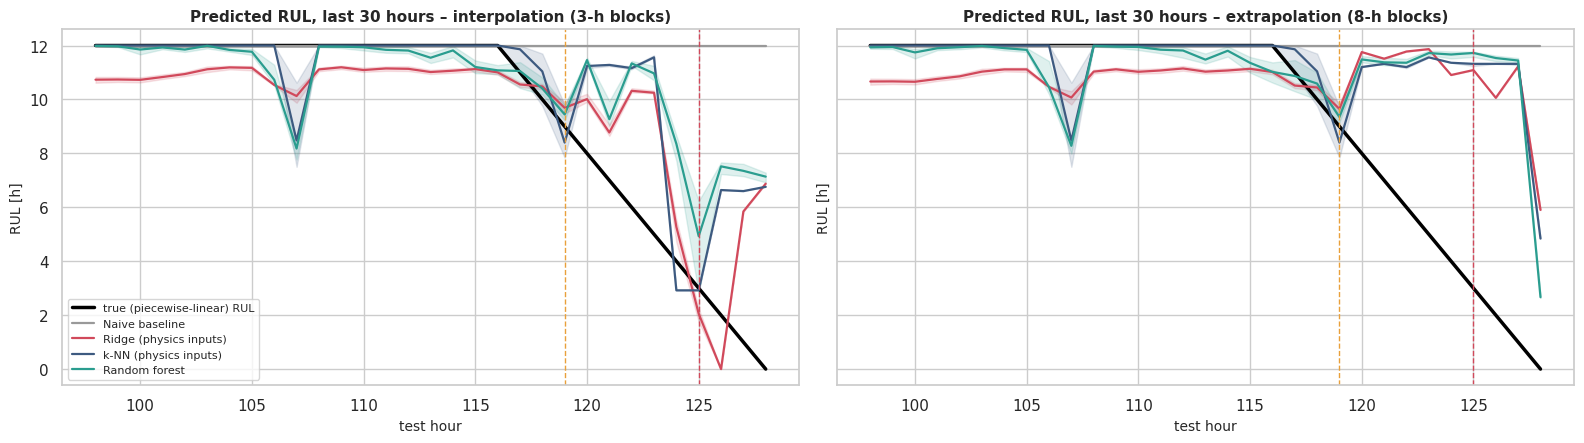

In [ ]:
interp = "interpolation (3-h blocks)"
best_rul = (rul_results[(rul_results["validation"] == interp) & (rul_results["model"] != "Naive baseline")]
            .sort_values("MAE last 12 h [h]").iloc[0]["model"])
show = list(dict.fromkeys(["Naive baseline", best_rul, "k-NN (physics inputs)", "Random forest", "Gradient boosting"]))[:4]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
for ax, scheme in zip(axes, schemes):
    zoom = feat["hour"] >= T_EOL - 30
    truth = feat[zoom].groupby("hour")["RUL_target"].first()
    ax.plot(truth.index, truth.values, color="black", lw=2.5, label="true (piecewise-linear) RUL")
    for name, col in zip(show, ["#999", "#d1495b", "#3d5a80", "#2a9d8f"]):
        s = pd.Series(np.clip(rul_pred[(scheme, name)], 0, R_CAP)[zoom.to_numpy()], index=feat.loc[zoom, "hour"])
        g = s.groupby(level=0)
        ax.plot(g.median().index, g.median().values, color=col, lw=1.6, label=name)
        ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75), color=col, alpha=0.15)
    ax.axvline(P_HOUR, ls="--", color=STAGE_COLORS["Degrading"], lw=1); ax.axvline(F_HOUR, ls="--", color=STAGE_COLORS["Failure"], lw=1)
    ax.set(title=f"Predicted RUL, last 30 hours – {scheme}", xlabel="test hour", ylabel="RUL [h]")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

#### 🔎 Key findings – RUL regression (Q3)
* **Interpolation test (optimistic):** the best model, **ridge regression on the physics inputs**, estimates the last 12 hours with
  a mean absolute error of **2.5 h** (R² = 0.71), against 6.0 h for the naive "always healthy" baseline. Its PHM score is 3.9 vs 12.4, so it is
  also the *safest* (fewest optimistic errors). Next come k-NN on physics inputs (3.1 h), the random forest (3.4 h) and gradient boosting (3.7 h).
  The MLP is unstable with this little data (overall R² < 0).
* **Extrapolation test (realistic for an unseen failure):** every model drops to 4.6–5.3 h, barely better than the baseline. With the
  failure stage removed from training, the only states the models know are healthy ones (all with RUL = 12 h), so they keep predicting "healthy".
* **Parameter experiments:** k-NN improves as *k* shrinks (MAE 5.4 → 3.9 h for k = 75 → 5), because the useful information is local in time;
  the random forest is insensitive to depth (3.5 h at depth 4 vs 3.4 h unlimited).
* **Implication:** with one run-to-failure, RUL can be *interpolated* along a failure path that has been seen, to within ~2.5 h, but not
  *extrapolated* to a failure that has not. The bottleneck is data, not the algorithm.

### 7.5 Model-based alternative: exponential degradation model
A label-free approach used in prognostics: fit an exponential growth curve to a monotone health signal and extrapolate
it to the failure threshold. Here the signal is the **temperature rise**, made monotone with a running maximum (damage does
not heal), and the threshold is the stop criterion ($T_{bearing} = 85$ °C, i.e. $\Delta T = 85 - T_{ambient}$). At every hour
after the alarm we refit with the data available *so far* (causal), and a residual bootstrap gives a 90 % interval.

In [ ]:
dT_env = hourly["temp_rise"].cummax()
dT_fail = FAIL_TEMP_C - hourly["temp_ambient"]
# observed crossing of the 85 degC limit (linear interpolation between the hourly snapshots)
above = hourly.index[hourly["temp_bearing"] > FAIL_TEMP_C][0]
t0_, t1_ = above - 1, above
t_cross_true = t0_ + (FAIL_TEMP_C - hourly.loc[t0_, "temp_bearing"]) / (hourly.loc[t1_, "temp_bearing"] - hourly.loc[t0_, "temp_bearing"])

rng = np.random.default_rng(RNG)
prog = []
for t in range(P_HOUR, int(t_cross_true) + 1):
    seg = dT_env.loc[P_HOUR - 6:t]
    x, yv = seg.index.to_numpy(float), np.log(seg.to_numpy())
    b, a = np.polyfit(x, yv, 1)
    target = np.log(dT_fail.loc[t])
    t_hat = (target - a) / b if b > 1e-6 else np.inf
    resid = yv - (a + b * x)
    sims = []
    for _ in range(400):
        bb, aa = np.polyfit(x, a + b * x + rng.choice(resid, len(resid)), 1)
        sims.append((target - aa) / bb if bb > 1e-6 else np.inf)
    lo, hi_ = np.percentile(sims, [5, 95])
    prog.append({"hour": t, "growth rate [1/h]": b, "predicted RUL to 85 °C [h]": t_hat - t,
                 "90% interval low": lo - t, "90% interval high": hi_ - t, "true RUL to 85 °C [h]": t_cross_true - t})
prog = pd.DataFrame(prog).set_index("hour")
print(f"Observed crossing of 85 °C at hour {t_cross_true:.2f}")
prog.round(2)

Observed crossing of 85 °C at hour 124.64


,growth rate [1/h],predicted RUL to 85 °C [h],90% interval low,90% interval high,true RUL to 85 °C [h]
hour,,,,,
119,0.01,98.73,53.83,717.7,5.64
120,0.01,72.07,47.39,140.9,4.64
121,0.02,32.57,21.12,65.72,3.64
122,0.03,25.27,17.76,41.01,2.64
123,0.03,22.89,16.95,35.05,1.64
124,0.04,14.53,10.34,21.44,0.64


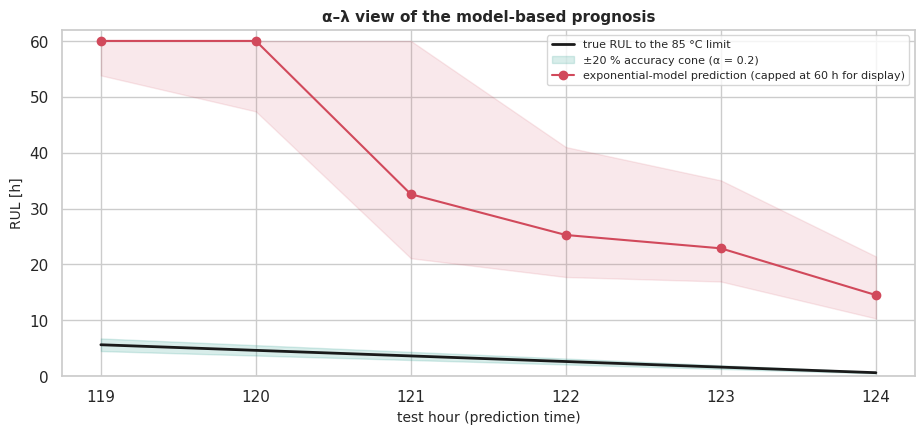

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
tt = prog.index.to_numpy()
truth = prog["true RUL to 85 °C [h]"]
ax.plot(tt, truth, "k-", lw=2, label="true RUL to the 85 °C limit")
ax.fill_between(tt, truth * 0.8, truth * 1.2, color="#2a9d8f", alpha=0.18, label="±20 % accuracy cone (α = 0.2)")
pred = prog["predicted RUL to 85 °C [h]"].clip(upper=60)
ax.plot(tt, pred, "o-", color="#d1495b", label="exponential-model prediction (capped at 60 h for display)")
ax.fill_between(tt, prog["90% interval low"].clip(upper=60), prog["90% interval high"].clip(upper=60), color="#d1495b", alpha=0.12)
ax.set(xlabel="test hour (prediction time)", ylabel="RUL [h]", title="α–λ view of the model-based prognosis", ylim=(0, 62))
ax.legend(fontsize=8)
plt.show()

#### 🔎 Key findings – model-based prognosis
* The exponential model is **dangerously optimistic**: at the alarm (hour 119) it predicts ≈ 99 h to the 85 °C limit when the
  truth was 5.6 h, and even one hour before the crossing it still predicts ≈ 15 h. Every prediction falls far outside the ±20 % cone,
  and the 90 % intervals do not contain the truth.
* The reason is physical: this bearing did not degrade exponentially. The temperature rise crept up by a few °C over ten hours,
  then jumped 15 °C (hour 123 → 124) and another 29 °C (hour 124 → 125). A trend model fitted to the creep cannot anticipate the jumps.
* **Implication:** for abrupt failure modes, the **alarm itself** is the actionable output. After P, the honest RUL message is *"hours, not days"*.

---
### Model evaluation (Step 6 of the 7-step procedure)
*"Evaluate the confession."* We compare against baselines rather than perfection (Lecture 16) and look at the errors that
matter for maintenance: false alarms, missed failures, statuses that are several levels off, and RUL over-estimation.

### 7.6 Ordinal classification: confusion matrix, recall per status and status over time

Best ordinal model in the realistic (extrapolation) test: Conservative max(ordinal logistic, RUL status) (physics inputs) | QWK = 0.891 | MAE = 0.078 levels | errors ≥ 2 levels = 0.8%


recall ✅ Operational  recall 🔻 Degraded  recall ⚠️ At risk  recall ❌ Fault detected  macro-F1
validation                 model                                                                                                                                        
interpolation (3-h blocks) Multinomial logistic regression                                0.922              0.412                  0                     0.25     0.397
                           Ordinal logistic regression                                    0.995              0.333                  0                     0.25     0.432
                           Status from predicted RUL (ridge)                                  1                  0              0.009                        1      0.49
                           Conservative max(ordinal logistic, RUL status)                 0.995              0.333                  0                        1     0.571
extrapolation (8-h blocks) Multinomial logistic regression                                 0.91              0.412                  0                     0.25     0.388
                           Ordinal logistic regression                                    0.995              0.333                  0                     0.25     0.418
                           Status from predicted RUL (ridge)                                  1              0.058              0.068                        1     0.503
                           Conservative max(ordinal logistic, RUL status)                 0.995              0.162              0.068                        1     0.527

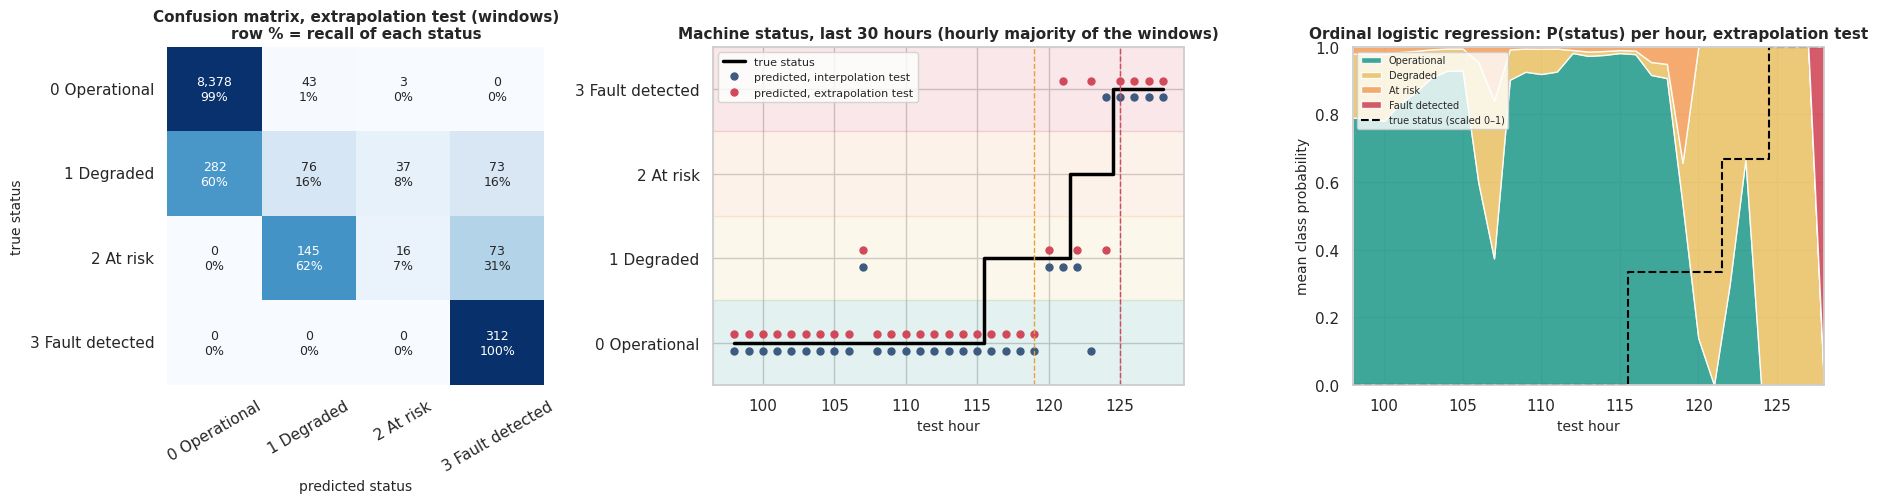

interpolation (3-h blocks): operational hours (≤ 115) with a warning status: [107]
extrapolation (8-h blocks): operational hours (≤ 115) with a warning status: [107]


hour,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128
true status,✅ 0,✅ 0,🔻 1,🔻 1,🔻 1,🔻 1,🔻 1,🔻 1,⚠️ 2,⚠️ 2,⚠️ 2,❌ 3,❌ 3,❌ 3,❌ 3
"predicted, interpolation test",✅ 0,✅ 0,✅ 0,✅ 0,✅ 0,✅ 0,🔻 1,🔻 1,🔻 1,✅ 0,❌ 3,❌ 3,❌ 3,❌ 3,❌ 3
"predicted, extrapolation test",✅ 0,✅ 0,✅ 0,✅ 0,✅ 0,✅ 0,🔻 1,❌ 3,🔻 1,❌ 3,🔻 1,❌ 3,❌ 3,❌ 3,❌ 3


In [ ]:
extrap, interp = "extrapolation (8-h blocks)", "interpolation (3-h blocks)"
best_cls = cls_results[cls_results["validation"] == extrap].sort_values("QWK", ascending=False).iloc[0]
best_key = (best_cls["model"], best_cls["inputs"])
print(f"Best ordinal model in the realistic (extrapolation) test: {best_key[0]} ({best_key[1]} inputs) | "
      f"QWK = {best_cls['QWK']:.3f} | MAE = {best_cls['MAE [levels]']:.3f} levels | errors ≥ 2 levels = {best_cls['errors ≥ 2 levels']:.1%}")
recall_cols = [c for c in cls_results.columns if c.startswith("recall ")]
compare = ["Multinomial logistic regression", "Ordinal logistic regression", RUL_STATUS, COMBINED]
display(cls_results[cls_results["model"].isin(compare) & (cls_results["inputs"] == "physics")]
        .set_index(["validation", "model"])[recall_cols + ["macro-F1"]].round(3))

mask_u = use.to_numpy()
ticks = [f"{k} {s}" for k, s in enumerate(STATUS_ORDER)]
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.2), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
cm = confusion_matrix(y_status[mask_u], status_pred[(extrap, *best_key)][mask_u], labels=list(range(4)))
cm_pct = cm / cm.sum(axis=1, keepdims=True)
annot = np.array([[f"{n:,}\n{p:.0%}" for n, p in zip(r_n, r_p)] for r_n, r_p in zip(cm, cm_pct)])
sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", cbar=False, ax=axes[0], xticklabels=ticks, yticklabels=ticks,
            vmin=0, vmax=1, annot_kws={"size": 9})
axes[0].set(xlabel="predicted status", ylabel="true status",
            title="Confusion matrix, extrapolation test (windows)\nrow % = recall of each status")
axes[0].tick_params(axis="x", rotation=30); axes[0].tick_params(axis="y", rotation=0)

late = (feat["hour"] >= T_EOL - 30).to_numpy()
true_h = feat[late].groupby("hour")["status_code"].first()
majority = lambda v: int(np.bincount(np.asarray(v, dtype=int), minlength=4).argmax())
ax = axes[1]
for k, s in enumerate(STATUS_ORDER):
    ax.axhspan(k - 0.5, k + 0.5, color=STATUS_COLORS[s], alpha=0.13)
ax.step(true_h.index, true_h.values, where="mid", color="black", lw=2.5, label="true status")
for scheme, col, off in ((interp, "#3d5a80", -0.1), (extrap, "#d1495b", 0.1)):
    pred_h = pd.Series(status_pred[(scheme, *best_key)][late], index=feat.loc[late, "hour"]).groupby(level=0).agg(majority)
    ax.plot(pred_h.index, pred_h.values + off, "o", ms=5, color=col, label=f"predicted, {scheme.split(' (')[0]} test")
ax.axvline(P_HOUR, ls="--", color=STAGE_COLORS["Degrading"], lw=1); ax.axvline(F_HOUR, ls="--", color=STAGE_COLORS["Failure"], lw=1)
ax.set(yticks=range(4), yticklabels=ticks, ylim=(-0.5, 3.5), xlabel="test hour",
       title="Machine status, last 30 hours (hourly majority of the windows)")
ax.legend(fontsize=8, loc="upper left")

ax = axes[2]
prob_h = pd.DataFrame(status_proba[(extrap, "Ordinal logistic regression", "physics")][late],
                      index=feat.loc[late, "hour"], columns=STATUS_ORDER).groupby(level=0).mean()
ax.stackplot(prob_h.index, prob_h.T.values, colors=[STATUS_COLORS[s] for s in STATUS_ORDER], labels=STATUS_ORDER, alpha=0.9)
ax.step(true_h.index, true_h.values / 3, where="mid", color="black", lw=1.5, ls="--", label="true status (scaled 0–1)")
ax.set(xlabel="test hour", ylabel="mean class probability", ylim=(0, 1), xlim=(prob_h.index.min(), prob_h.index.max()),
       title="Ordinal logistic regression: P(status) per hour, extrapolation test")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

# hour-by-hour view of the best model (majority status of the 78 windows of each hour)
icon = lambda k: f"{STATUS_ICON[STATUS_ORDER[k]]} {k}"
pred_by_hour = {s: pd.Series(status_pred[(s, *best_key)][mask_u], index=feat.loc[mask_u, "hour"]).groupby(level=0).agg(majority)
                for s in (interp, extrap)}
by_hour = pd.DataFrame({"true status": feat[mask_u].groupby("hour")["status_code"].first(),
                        **{f"predicted, {s.split(' (')[0]} test": p for s, p in pred_by_hour.items()}})
for s, p in pred_by_hour.items():
    early = p.loc[:T_EOL - STATUS_CUTS[0] - 1]
    print(f"{s}: operational hours (≤ {T_EOL - STATUS_CUTS[0] - 1}) with a warning status: {list(early.index[early > 0])}")
by_hour.loc[T_EOL - 14:].map(icon).T

#### 🔎 Key findings – ordinal classification evaluation
* **The extremes are recognized, the middle is hard.** In the realistic test the combined model keeps 99 % of the operational windows
  ✅ Operational and reports **every** ❌ Fault detected window correctly. It never confuses Operational with Fault detected in either direction.
* **🔻 Degraded:** 60 % of its windows are still called Operational. Hour by hour, the first warning comes at **hour 120**, four hours after
  the status changed (hour 116) – the friction index only crossed its alarm line at hour 119 (Section 7.2), so the inputs carry little
  warning before that.
* **⚠️ At risk** is recognized only 7 % of the time: 62 % of its windows are called Degraded and 31 % Fault detected. At hours 122–123 the
  temperature briefly fell back, so the bearing *looked* less degraded than at hour 121, and at hour 124 it jumped to near-fault values.
  The bearing did not pass smoothly through the intermediate status, so the errors are one level either way.
* **Every two-level error is on the safe side:** 73 Degraded windows reported as Fault detected (0.8 % of all windows). The model never
  under-reports by two levels. The hour-by-hour sequence is jumpy in the extrapolation test (Degraded and Fault detected alternate over
  hours 120–124), which is why the deployed monitor latches the status (Section 7).
* **False warnings:** in the 108 operational hours after the run-in, only **hour 107** is flagged (the short temperature spike after an
  operating change), in both tests.
* The stacked probabilities show the limitation of a classifier on its own: in the extrapolation test the ordinal logistic regression puts
  almost no probability on *At risk* or *Fault detected* in the last hours, because those statuses were absent from its training data.
  The RUL-based component supplies them.

### 7.7 RUL models: accuracy, safety and cost

MAE last 12 h [h]                            PHM score (last 12 h, hourly)                                               seconds  \
validation             extrapolation (8-h blocks) interpolation (3-h blocks)    extrapolation (8-h blocks) interpolation (3-h blocks) extrapolation (8-h blocks)   
model                                                                                                                                                              
Ridge (physics inputs)                       4.82                       2.45                          9.09                       3.87                       0.07   
k-NN (physics inputs)                        4.78                       3.09                          9.13                       5.17                       0.11   
Random forest                                4.75                       3.44                           9.1                       5.78                       5.12   
Gradient boosting                            5.24                       3.73                          9.83                       6.31                      10.56   
Ridge regression                             5.26                       4.36                         10.32                       8.47                       0.14   
MLP neural network                           4.56                       4.68                          6.44                       8.86                       7.72   
k-NN (k = 25)                                5.31                       4.72                         10.45                       8.79                       0.28   
Naive baseline                                  6                          6                         12.38                      12.38                       0.03   

                                                   
validation             interpolation (3-h blocks)  
model                                              
Ridge (physics inputs)                       0.16  
k-NN (physics inputs)                        0.23  
Random forest                               14.99  
Gradient boosting                           26.71  
Ridge regression                             1.18  
MLP neural network                          19.07  
k-NN (k = 25)                                0.62  
Naive baseline                               0.09

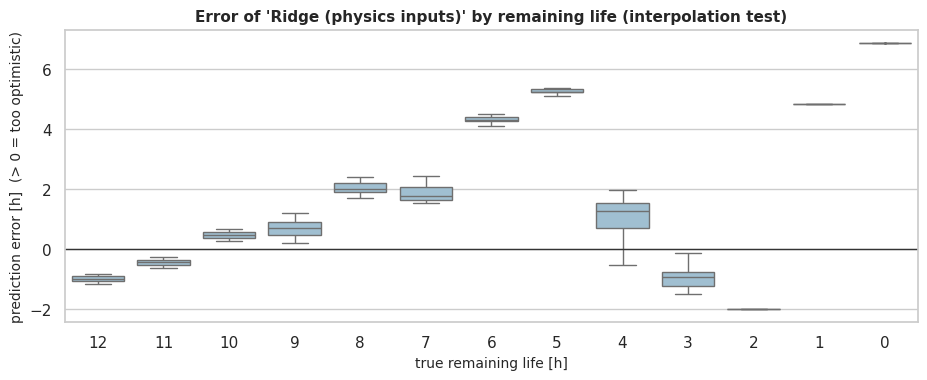

In [ ]:
summary = rul_results.pivot_table(index="model", columns="validation",
                                  values=["MAE last 12 h [h]", "PHM score (last 12 h, hourly)", "seconds"]).round(2)
summary = summary.sort_values(("MAE last 12 h [h]", interp))
display(summary)

# error by remaining life for the best model in the interpolation test
p = np.clip(rul_pred[(interp, best_rul)], 0, R_CAP)
crit = (use & (feat["RUL_h"] <= R_CAP)).to_numpy()
err = pd.DataFrame({"RUL_h": feat.loc[crit, "RUL_h"], "error": p[crit] - y_rul[crit]})
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.boxplot(data=err, x="RUL_h", y="error", ax=ax, color="#98c1d9", fliersize=1)
ax.axhline(0, color="#333", lw=1)
ax.set(xlabel="true remaining life [h]", ylabel="prediction error [h]  (> 0 = too optimistic)",
       title=f"Error of '{best_rul}' by remaining life (interpolation test)")
ax.invert_xaxis(); plt.show()

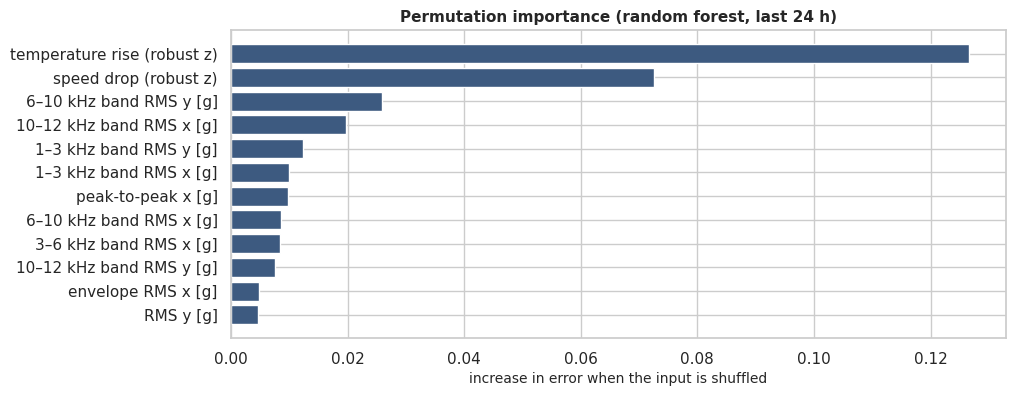

In [ ]:
# Which inputs drive the RUL model? Permutation importance of a random forest on the critical last 24 hours.
rf_full = RandomForestRegressor(n_estimators=100, max_features="sqrt", min_samples_leaf=3, n_jobs=-1, random_state=RNG)
train_all = (use & (feat["window"] % 6 == 0)).to_numpy()
rf_full.fit(feat.loc[train_all, ALL], y_rul[train_all])
late = (use & (feat["hour"] >= T_EOL - 24) & (feat["window"] % 2 == 0)).to_numpy()
imp = permutation_importance(rf_full, feat.loc[late, ALL], y_rul[late], n_repeats=3, random_state=RNG, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=ALL).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([LABELS.get(c, c) for c in imp_s.index[::-1]], imp_s.values[::-1], color="#3d5a80")
ax.set(xlabel="increase in error when the input is shuffled", title="Permutation importance (random forest, last 24 h)")
plt.show()

#### 🔎 Key findings – RUL evaluation and explainability
* The error profile of the best model is uneven: within ±1 h at the start of the 12-h window, **optimistic by 4–5 h at 5–6 h before the
  end** (hours 122–123, when the temperature briefly fell back), close again at 2–4 h, and optimistic once more in the last hour. Optimistic
  errors are the dangerous kind, so in practice the RUL estimate should be read together with the latched alarm.
* Computational cost is negligible for the linear and k-NN models (< 0.4 s for all folds) and 7–18 s for the random forest, gradient
  boosting and MLP. Every model could run at the edge (Lecture 16: cloud–fog–edge).
* **Explainability:** the random-forest permutation importance ranks the **temperature rise and the speed drop first**, far ahead of all 56
  vibration indicators (the next ones are the 6–12 kHz band energies). The ordinal logistic regression of Section 7.3.1 is fully
  interpretable: per robust σ, the temperature rise multiplies the odds of a worse machine status by 4.8 and the speed drop by 1.3.

### 7.8 Comparison of the approaches

| Approach | Strengths | Weaknesses | Result on this bearing |
|---|---|---|---|
| Univariate 3σ on vibration (RMS, kurtosis) | simple, standard, no false alarms here | reacts only to severe damage | alarm 0–1 h before F – too late |
| Data-driven HI (Mahalanobis) / Isolation Forest | uses all 56 indicators, no labels needed | cannot tell operating changes from damage | alarm at hour 76–77, 25 false-alarm hours |
| **Physics-based friction index** | interpretable, selective, uses only temperature and an estimated speed | needs a baseline that covers all regimes; untested on other failure modes | **alarm 6 h before F, no false alarms**; a 2σ watch gives 8 h with one false watch |
| Ordinal logistic regression (physics inputs) | interpretable odds ratios, respects the order, 0.5 % false warnings | cannot output a status absent from training | QWK 0.84 (interpolation) / 0.67 (extrapolation) |
| Multinomial logistic regression / random forest | standard multi-class models | ignore the order; the forest cannot extrapolate | QWK 0.80 / 0.65 (multinomial, physics); forest 0.28 in the realistic test |
| **Conservative ordinal combination** (ordinal logistic + RUL-based status) | reports unseen severe statuses; errors on the safe side | middle statuses confused with their neighbours | **QWK 0.89 in both tests, 0.8 % errors of ≥ 2 levels** |
| Supervised RUL regression | 2.5 h error when the failure path has been seen | collapses to "healthy" for an unseen failure | ≈ 6 h benefit only within a known failure path |
| Exponential degradation model | label-free, causal, gives uncertainty | assumes gradual, exponential growth | badly optimistic for this abrupt failure |

**Relation to the literature.** Benchmark bearing-prognostics datasets contain many run-to-failure tests – 17 in the PRONOSTIA
(IEEE PHM 2012 challenge) dataset and 15 in XJTU-SY [11, 12] – which is what makes supervised RUL models validated on
*unseen* bearings possible there. Our results show why: with a single trajectory, supervised RUL only works in interpolation, while
detection with physics-informed indicators is already practical.

---
### Model deployment (Step 7 of the 7-step procedure)
*"Deploy the model."*

### 7.9 Online monitoring service
A monitoring service receives one 78-second record per hour, computes the indicators (the same code as
`pipeline/build_features.py`), and returns a health assessment. The class below packages the pieces developed above. Its main
output is the **ordinal machine status** with its icon and recommended action – the *label* column of the Lecture 9 example –
obtained from the conservative combination of Section 7.3 (ordinal logistic regression and the status implied by a linear
RUL trend), together with the two-level friction alert of Section 7.2.1 (👁 watch at 2 σ, 🔔 alarm at 3 σ) and the RUL estimate
of Section 7.4, converted for the DCS into the remaining life at the three load scenarios (high / medium / low), which
Section 7.10 turns into a load recommendation. Like the alarm, the reported status is **latched**: because the levels are ordered, it can only move up the scale until a maintenance action resets it (damage does
not heal), and a latched friction alarm means at least 🔻 Degraded.

> **Honest note.** The demo replays the same bearing the models were fitted on, so it shows *how the service works*, not how
> accurate it is. Accuracy is what Section 7 measured with out-of-sample validation.

In [ ]:
class BearingHealthMonitor:
    """Hourly bearing assessment: two-level friction alert, ordinal machine status (with icon and action), RUL estimate."""

    def __init__(self, baseline_rows, status_classifier, severity_model, rul_model, threshold=ALARM_SIGMA,
                 watch_level=WATCH_SIGMA, persist=2):
        self.tr_ref, self.sp_ref = baseline_rows["temp_rise"], baseline_rows["rpm"]
        self.status_classifier, self.severity_model, self.rul_model = status_classifier, severity_model, rul_model
        self.threshold, self.watch_level, self.persist = threshold, watch_level, persist
        self.history = []
        self.latched = False                       # the friction alarm stays on until maintenance acknowledges it
        self.reported = 0                          # the reported status is never lowered without a maintenance action

    @staticmethod
    def _rz(x, ref):
        return (x - ref.median()) / (1.4826 * (ref - ref.median()).abs().median())

    def assess(self, hour, windows):
        """`windows`: the 1-s indicator rows of one hourly record (same columns as the window table)."""
        w = windows.copy()
        w["z_temp_rise"] = self._rz(w["temp_rise"], self.tr_ref)
        w["z_speed_drop"] = -self._rz(w["rpm"], self.sp_ref)
        fi = float(w[PHYS].mean(axis=1).mean())
        self.history.append(fi)
        recent = self.history[-self.persist:]
        self.latched = self.latched or (len(recent) == self.persist and all(v > self.threshold for v in recent))
        watch = len(recent) == self.persist and all(v > self.watch_level for v in recent)      # 2σ warning limit
        proba = self.status_classifier.predict_proba(w[PHYS]).mean(axis=0)        # mean P(status) over the windows
        s_clf = int(np.argmax(proba))                                               # ordinal logistic regression
        s_rul = int(status_from_rul(np.median(self.severity_model.predict(w[PHYS]))))  # status implied by the RUL trend
        now = max(s_clf, s_rul)                                                     # conservative: the more severe
        if self.latched:
            now = max(now, 1)                      # a latched friction alarm means at least 'Degraded'
        self.reported = max(self.reported, now)    # damage does not heal: the ordinal status can only move up
        status = STATUS_ORDER[self.reported]
        rul = float(np.clip(np.median(self.rul_model.predict(w[ALL])), 0, R_CAP))
        action = STATUS_ACTION[status]
        if status == "Operational" and watch:
            action = "watch: check lubrication and load"
        alert = "🔔 alarm" if self.latched else ("👁 watch" if watch else "–")
        factors = [life_factor(k) for k in LOAD_SCENARIOS.values()]          # ISO 281 life factor per load scenario
        if status == "Fault detected":
            rul_by_load = "stop"
        elif status == "Operational":                                          # no warning yet: the status guarantees this much
            rul_by_load = " / ".join(f"≥ {STATUS_CUTS[0] * f:.0f}" for f in factors)
        else:                                                                  # conservative: never above the status range
            basis = min(rul, STATUS_CUTS[0] if status == "Degraded" else STATUS_CUTS[1])
            rul_by_load = " / ".join(f"{basis * f:.1f}" for f in factors)
        return {"hour": hour, "friction index": round(fi, 2), "friction alert": alert,
                "P(worse than Operational)": round(float(1 - proba[0]), 3),
                "status this hour": f"{STATUS_ICON[STATUS_ORDER[now]]} {STATUS_ORDER[now]}",
                "reported status Y": f"{STATUS_ICON[status]} {status} ({self.reported})",
                "RUL at high / medium / low load [h]": rul_by_load, "recommended action": action}

train_rows = (use & (feat["window"] % 3 == 0)).to_numpy()
status_deploy = OrdinalLogit().fit(feat.loc[train_rows, PHYS], y_status[train_rows])
severity_deploy = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(feat.loc[train_rows, PHYS], feat.loc[train_rows, "RUL_h"])
rul_deploy = regressors[best_rul][0]().fit(feat.loc[train_rows, ALL], y_rul[train_rows])
monitor = BearingHealthMonitor(feat[base_win], status_deploy, severity_deploy, rul_deploy)
stream = pd.DataFrame([monitor.assess(h, feat[feat["hour"] == h]) for h in range(RUN_IN, T_EOL + 1)]).set_index("hour")
print("Hours per reported machine status over the whole replay:",
      stream["reported status Y"].str.rsplit(" (", n=1).str[0].value_counts()
      .reindex([f"{STATUS_ICON[s]} {s}" for s in STATUS_ORDER], fill_value=0).to_dict())
print("Hours with a friction watch while the status was still Operational:",
      stream.index[(stream["friction alert"] == "👁 watch") & stream["reported status Y"].str.startswith("✅")].tolist())
with pd.option_context("display.max_colwidth", None):
    display(stream.loc[T_EOL - 14:])

Hours per reported machine status over the whole replay: {'✅ Operational': 111, '🔻 Degraded': 2, '⚠️ At risk': 4, '❌ Fault detected': 4}
Hours with a friction watch while the status was still Operational: [92, 93, 118]


,friction index,friction alert,P(worse than Operational),status this hour,reported status Y,RUL at high / medium / low load [h],recommended action
hour,,,,,,,
114,1.23,–,0.063,✅ Operational,✅ Operational (0),≥ 12 / ≥ 25 / ≥ 73,any load up to high; continue normal monitoring
115,1.24,–,0.054,✅ Operational,✅ Operational (0),≥ 12 / ≥ 25 / ≥ 73,any load up to high; continue normal monitoring
116,1.51,–,0.071,✅ Operational,✅ Operational (0),≥ 12 / ≥ 25 / ≥ 73,any load up to high; continue normal monitoring
117,2.33,–,0.242,✅ Operational,✅ Operational (0),≥ 12 / ≥ 25 / ≥ 73,any load up to high; continue normal monitoring
118,2.52,👁 watch,0.28,✅ Operational,✅ Operational (0),≥ 12 / ≥ 25 / ≥ 73,watch: check lubrication and load
119,3.78,👁 watch,0.747,🔻 Degraded,🔻 Degraded (1),8.3 / 17.5 / 50.0,limit to medium load; plan the replacement
120,3.39,🔔 alarm,0.663,🔻 Degraded,🔻 Degraded (1),8.6 / 18.1 / 51.8,limit to medium load; plan the replacement
121,5.77,🔔 alarm,0.975,⚠️ At risk,⚠️ At risk (2),6.0 / 12.7 / 36.3,limit to low load; replace at the next opportunity
122,2.98,🔔 alarm,0.47,🔻 Degraded,⚠️ At risk (2),6.0 / 12.7 / 36.3,limit to low load; replace at the next opportunity


### 7.10 DCS load advisor: how much load can the bearing take?
The operator in the control room (DCS) cannot repair the bearing, but can choose how hard the machine is driven. Because the
remaining life depends strongly on load, the advisor answers two questions for the current machine status: *what remaining
life does each load scenario give?* and *what is the highest load that still reaches the next planned stop?*

**Model.** The ISO 281 load–life law for ball bearings, $L \propto P^{-3}$, with the equivalent load $P = X F_r + Y F_a$
recomputed for each scenario (radial and axial loads scaled together). Assuming that damage accumulates at a rate
proportional to $P^3$ (Palmgren–Miner linear damage), the remaining life estimated at the tested load is multiplied by the
**life factor** $(P_{test}/P)^3$. The basis is conservative: no derating while the status is ✅ Operational (the status itself
guarantees at least 12 h of warning at high load), and while 🔻 Degraded or ⚠️ At risk the remaining life at high load is the
RUL estimate of Section 7.4, capped at the upper limit of the status range.

**Planning rule.** The ❌ *Fault detected* window, the last 3 h of life at the tested load (3 h × life factor at a lower load),
ends in functional failure, so it is kept in **reserve**: the machine can run for (remaining life − 3 h) × life factor before
it must be stopped. The advisor recommends the highest load, from 20 to 110 % of the tested load in steps of 1 %, whose run
time still covers the hours to the next planned stop.

**Assumptions and limits.** Speed, lubrication, temperature and the 5-min-on / 15-min-off duty cycle stay as in the test, so
all hours are test hours. Only the high load was tested: medium and low are **extrapolations of a catalogue law**, and the
load exponent after a spall has formed is uncertain. A bearing reported ❌ Fault detected must be stopped at any load.

In [ ]:
grid = np.round(np.arange(0.20, 1.1001, 0.01), 2)                      # load fraction of the tested load
factor_grid = np.array([life_factor(k) for k in grid])
RESERVE = STATUS_CUTS[2]                       # the ❌ Fault-detected window [h at the tested load], kept in reserve
scenario_rows = []
for name, k in {**LOAD_SCENARIOS, "Normal service (20 %)": 0.20}.items():
    P_k, f_k = equivalent_load(k * Fr, k * Fa)[0], life_factor(k)
    scenario_rows.append({
        "scenario": name, "load [% of tested]": round(100 * k), "radial / axial load [kN]": f"{k * Fr:.2f} / {k * Fa:.2f}",
        "equivalent load P [kN]": round(P_k, 2), "P/C": round(P_k / C, 3), "life factor": round(f_k, 2),
        "rated life L10 [h of rotation]": round((C / P_k) ** 3 * 1e6 / (rpm * 60)),
        f"{STATUS_ICON['Operational']} Operational": f"> {STATUS_CUTS[0] * f_k:.0f} h",
        f"{STATUS_ICON['Degraded']} Degraded": f"{STATUS_CUTS[1] * f_k:.0f} – {STATUS_CUTS[0] * f_k:.0f} h",
        f"{STATUS_ICON['At risk']} At risk": f"{STATUS_CUTS[2] * f_k:.0f} – {STATUS_CUTS[1] * f_k:.0f} h",
        f"{STATUS_ICON['Fault detected']} Fault detected (reserve)": f"last {RESERVE * f_k:.0f} h: stop"})
scenarios = pd.DataFrame(scenario_rows).set_index("scenario")
with pd.option_context("display.max_colwidth", None):
    display(scenarios)

,load [% of tested],radial / axial load [kN],equivalent load P [kN],P/C,life factor,rated life L10 [h of rotation],✅ Operational,🔻 Degraded,⚠️ At risk,❌ Fault detected (reserve)
scenario,,,,,,,,,,
High,100,5.88 / 2.94,6.35,0.454,1,100,> 12 h,6 – 12 h,3 – 6 h,last 3 h: stop
Medium,75,4.41 / 2.21,4.94,0.353,2.12,213,> 25 h,13 – 25 h,6 – 13 h,last 6 h: stop
Low,50,2.94 / 1.47,3.48,0.249,6.06,608,> 73 h,36 – 73 h,18 – 36 h,last 18 h: stop
Normal service (20 %),20,1.18 / 0.59,1.57,0.112,66.28,6651,> 795 h,398 – 795 h,199 – 398 h,last 199 h: stop


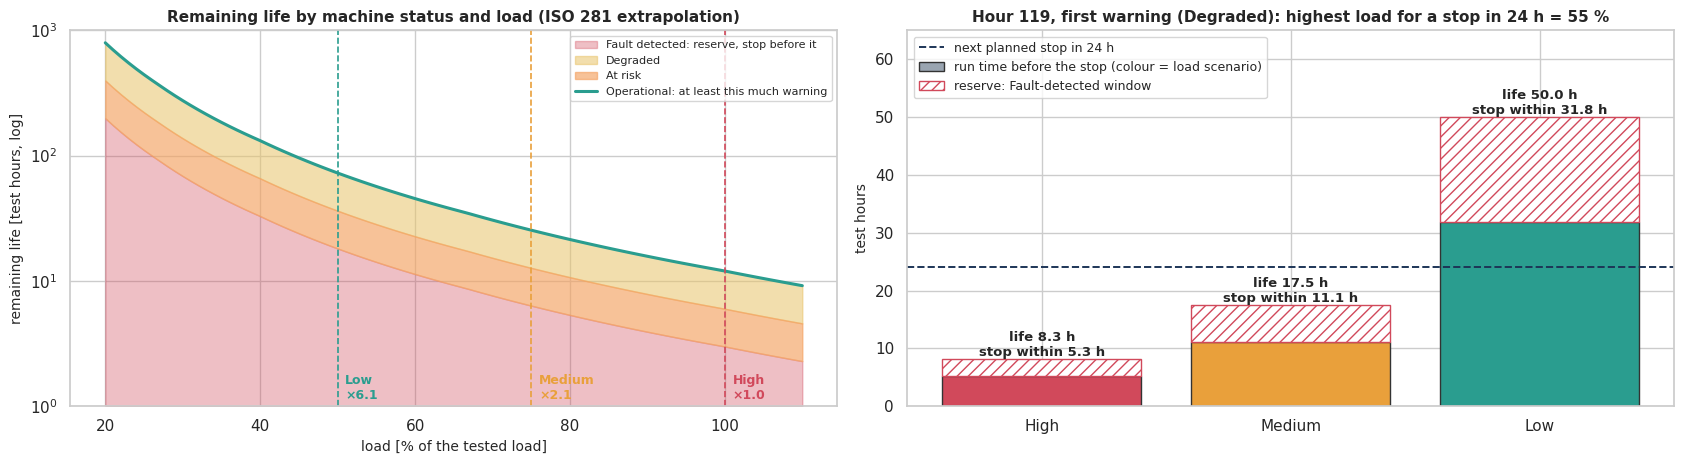

,reported status,RUL at high load [h],RUL at medium load [h],RUL at low load [h],"must stop within, high / medium / low [h]","max load, stop in 12 h","max load, stop in 24 h","max load, stop in 48 h"
hour,,,,,,,,
116,✅ Operational,≥ 12,≥ 25,≥ 73,≥ 9 / ≥ 19 / ≥ 55,100 % (no warning),100 % (no warning),100 % (no warning)
117,✅ Operational,≥ 12,≥ 25,≥ 73,≥ 9 / ≥ 19 / ≥ 55,100 % (no warning),100 % (no warning),100 % (no warning)
118,✅ Operational,≥ 12,≥ 25,≥ 73,≥ 9 / ≥ 19 / ≥ 55,100 % (no warning),100 % (no warning),100 % (no warning)
119,🔻 Degraded,8.3,17.5,50,5.3 / 11.1 / 31.8,72 %,55 %,42 %
120,🔻 Degraded,8.6,18.1,51.8,5.6 / 11.8 / 33.7,74 %,56 %,43 %
121,⚠️ At risk,6,12.7,36.3,3.0 / 6.4 / 18.2,58 %,44 %,34 %
122,⚠️ At risk,6,12.7,36.3,3.0 / 6.4 / 18.2,58 %,44 %,34 %
123,⚠️ At risk,6,12.7,36.3,3.0 / 6.4 / 18.2,58 %,44 %,34 %
124,⚠️ At risk,4.9,10.3,29.4,1.9 / 3.9 / 11.3,48 %,37 %,28 %


Check at the tested (high) load, the only load with ground truth:


,reported status,advisor: stop within [h],true: stop criterion F reached in [h],true: end of life in [h],spare life at the advised stop [h]
hour,,,,,
119,🔻 Degraded,5.3,6,9,3.7
120,🔻 Degraded,5.6,5,8,2.4
121,⚠️ At risk,3,4,7,4
122,⚠️ At risk,3,3,6,3
123,⚠️ At risk,3,2,5,2
124,⚠️ At risk,1.9,1,4,2.1


In [ ]:
# Remaining life (test hours) of the reported status at each load, and the highest load that reaches a planned stop
rul_now = feat.groupby("hour")[ALL].apply(lambda g: float(np.clip(np.median(rul_deploy.predict(g)), 0, R_CAP)))
status_now = stream["reported status Y"].str.extract(r"\((\d)\)")[0].astype(int)

def rul_basis(status_code, rul_estimate):
    """Remaining life at the tested load used by the advisor (None = no warning yet, 0 = stop)."""
    if status_code == 0:
        return None
    if status_code == 3:
        return 0.0
    return min(rul_estimate, STATUS_CUTS[0] if status_code == 1 else STATUS_CUTS[1])

def run_time(basis, k):
    """Hours the machine can still run at load fraction k before it must be stopped (the ❌ window is kept in reserve)."""
    return max(basis - RESERVE, 0.0) * life_factor(k)

def max_load_for(basis, hours_needed):
    """Highest load fraction (20–110 %) whose run time covers `hours_needed`; 0 if none does."""
    ok = grid[max(basis - RESERVE, 0.0) * factor_grid >= hours_needed]
    return float(ok.max()) if len(ok) else 0.0

advice = []
for h in range(T_EOL - 12, T_EOL + 1):
    code_, basis = int(status_now.loc[h]), rul_basis(int(status_now.loc[h]), rul_now.loc[h])
    row = {"hour": h, "reported status": f"{STATUS_ICON[STATUS_ORDER[code_]]} {STATUS_ORDER[code_]}"}
    for name, k in LOAD_SCENARIOS.items():
        row[f"RUL at {name.lower()} load [h]"] = (f"≥ {STATUS_CUTS[0] * life_factor(k):.0f}" if basis is None
                                                 else "stop" if code_ == 3 else round(basis * life_factor(k), 1))
    row["must stop within, high / medium / low [h]"] = (
        " / ".join(f"≥ {(STATUS_CUTS[0] - RESERVE) * life_factor(k):.0f}" for k in LOAD_SCENARIOS.values()) if basis is None
        else "now" if code_ == 3 else " / ".join(f"{run_time(basis, k):.1f}" for k in LOAD_SCENARIOS.values()))
    for need in (12, 24, 48):
        k_max = None if basis is None else (0.0 if code_ == 3 else max_load_for(basis, need))
        row[f"max load, stop in {need} h"] = ("100 % (no warning)" if k_max is None else
                                              "stop now" if code_ == 3 else f"{100 * k_max:.0f} %" if k_max else "stop earlier")
    advice.append(row)
advice = pd.DataFrame(advice).set_index("hour")

# ground truth exists only for the tested (high) load: compare the advisor's stop time with what really happened
warn_hours = [h for h in advice.index if 1 <= status_now.loc[h] <= 2]
advisor_check = pd.DataFrame({
    "reported status": advice.loc[warn_hours, "reported status"],
    "advisor: stop within [h]": [round(run_time(rul_basis(int(status_now.loc[h]), rul_now.loc[h]), 1.0), 1) for h in warn_hours],
    "true: stop criterion F reached in [h]": [F_HOUR - h for h in warn_hours],
    "true: end of life in [h]": [T_EOL - h for h in warn_hours]}, index=pd.Index(warn_hours, name="hour"))
advisor_check["spare life at the advised stop [h]"] = (advisor_check["true: end of life in [h]"]
                                                       - advisor_check["advisor: stop within [h]"]).round(1)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
ax = axes[0]
ax.fill_between(100 * grid, 1, STATUS_CUTS[2] * factor_grid, color=STATUS_COLORS["Fault detected"], alpha=0.35,
                label="Fault detected: reserve, stop before it")
ax.fill_between(100 * grid, STATUS_CUTS[1] * factor_grid, STATUS_CUTS[0] * factor_grid, color=STATUS_COLORS["Degraded"],
                alpha=0.55, label="Degraded")
ax.fill_between(100 * grid, STATUS_CUTS[2] * factor_grid, STATUS_CUTS[1] * factor_grid, color=STATUS_COLORS["At risk"],
                alpha=0.65, label="At risk")
ax.plot(100 * grid, STATUS_CUTS[0] * factor_grid, color=STATUS_COLORS["Operational"], lw=2.2,
        label="Operational: at least this much warning")
for name, k in LOAD_SCENARIOS.items():
    ax.axvline(100 * k, ls="--", lw=1.2, color=LOAD_COLORS[name])
    ax.text(100 * k + 1, 1.15, f"{name}\n×{life_factor(k):.1f}", color=LOAD_COLORS[name], fontsize=9, weight="bold")
ax.set(yscale="log", xlabel="load [% of the tested load]", ylabel="remaining life [test hours, log]", ylim=(1, 1000),
       title="Remaining life by machine status and load (ISO 281 extrapolation)")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
h_ex = int(status_now.index[status_now >= 1][0])                         # first reported warning
b_ex, need = rul_basis(int(status_now.loc[h_ex]), rul_now.loc[h_ex]), 24
names_ex = list(LOAD_SCENARIOS)
run_ex = np.array([run_time(b_ex, k) for k in LOAD_SCENARIOS.values()])
life_ex = np.array([b_ex * life_factor(k) for k in LOAD_SCENARIOS.values()])
ax.bar(names_ex, run_ex, color=[LOAD_COLORS[n] for n in names_ex], edgecolor="#333", label="run time before the stop")
ax.bar(names_ex, life_ex - run_ex, bottom=run_ex, color="white", edgecolor=STATUS_COLORS["Fault detected"], hatch="///",
       label="reserve: Fault-detected window")
for i, (r_, l_) in enumerate(zip(run_ex, life_ex)):
    ax.text(i, l_, f"life {l_:.1f} h\nstop within {r_:.1f} h", ha="center", va="bottom", fontsize=9.5, weight="bold")
ax.axhline(need, ls="--", color="#1d3557", lw=1.4, label=f"next planned stop in {need} h")
k_ex = max_load_for(b_ex, need)
ax.set(ylabel="test hours", ylim=(0, life_ex.max() * 1.3),
       title=f"Hour {h_ex}, first warning ({STATUS_ORDER[int(status_now.loc[h_ex])]}): highest load for a stop in {need} h = {100 * k_ex:.0f} %")
ax.legend(handles=[Line2D([], [], ls="--", color="#1d3557", lw=1.4, label=f"next planned stop in {need} h"),
                   Patch(facecolor="#9aa5b1", edgecolor="#333", label="run time before the stop (colour = load scenario)"),
                   Patch(facecolor="white", edgecolor=STATUS_COLORS["Fault detected"], hatch="///",
                         label="reserve: Fault-detected window")], fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()
with pd.option_context("display.max_colwidth", None):
    display(advice)
print("Check at the tested (high) load, the only load with ground truth:")
display(advisor_check)

#### 🔎 Key findings – load scenarios for the DCS operator
* **Load is the operator's strongest lever.** With the equivalent load recomputed per scenario, ISO 281 multiplies the remaining
  life by **×2.1 at medium load (75 %)**, **×6.1 at low load (50 %)** and **×66 at a normal service load (20 %, P ≈ 0.11·C)**.
  The factors are smaller than the naive (1/k)³ (2.4 and 8) because the axial factor Y rises as the axial load falls.
* **At the first warning (hour 119, 🔻 Degraded)** the advisor gives a remaining life of **8.3 h at high, 17.5 h at medium and
  50 h at low load**. With the ❌ window in reserve the machine must be stopped within 5.3 h, 11.1 h and 32 h respectively, so the
  highest load that still reaches a planned stop is **72 % for a stop in 12 h, 55 % in 24 h and 42 % in 48 h**.
* Once the status is ⚠️ *At risk* (hours 121–124) the room for manoeuvre shrinks: a stop in 24 h needs the load at **44 % or less**
  (37 % at hour 124), i.e. below the low scenario. From hour 125 the status is ❌ *Fault detected* and the only advice is to stop.
* **Check at the tested load**, the only one with ground truth: the advised stop always came **before the end of life, with
  2 to 4 h to spare**. It was at or before the stop criterion F at hours 119, 121 and 122, and up to 1 h after F at hours 120,
  123 and 124: an RUL error that the 3-h reserve absorbs, and the reason the reserve is needed.
* **What cannot be checked.** This test ran at a single load, so the medium and low figures are an extrapolation of a catalogue
  law: they show the direction and the order of magnitude of the benefit, not a validated prediction. In normal service, with a
  much lighter load, the same status would give days to weeks of warning, so the hour thresholds must be re-learned from service
  history before the advisor is used on a real machine.

### 7.11 Interactive dashboard
The cell below writes a self-contained HTML dashboard (Plotly.js) with KPI cards, a time-range slicer and linked charts,
including the **ordinal machine status** (true versus out-of-fold prediction), the two-level friction alert and the interactive
**DCS load advisor** of Section 7.10: pick an hour, a load scenario (high / medium / low or any custom load) and the time to the next
planned stop, and it shows the remaining life at each load and the highest load that still reaches the stop. The **operator alert
console** replays the monitoring hour by hour as the control room saw it: the alert state (normal, pending, 👁 watch, 🔔 alarm), why
the rule decided it (for example why hours 91–95 raised a watch and hour 107 did not), what drove the index (temperature rise or
speed drop) and what the operator should do, with an event log where the cause of each event can be recorded. It is saved as
`dashboard/bearing_dashboard.html` and previewed here. The same file is published in the GitHub repository.

> **Viewing this notebook on GitHub?** GitHub cannot run interactive charts, so the live dashboard produced by the cell below
> appears only in Colab or Jupyter. Open it in the browser:
> **[interactive dashboard](https://raw.githack.com/alsulami412-arch/ISE518-Bearing-RUL/main/dashboard/bearing_dashboard.html)**.
> The snapshot below shows the same dashboard.

![Snapshot of the interactive dashboard](https://raw.githubusercontent.com/alsulami412-arch/ISE518-Bearing-RUL/main/docs/figures/dashboard.png)

In [ ]:
best_pred_w = pd.Series(status_pred[(extrap, *best_key)][use.to_numpy()], index=feat.loc[use, "hour"])
p_warn_w = pd.Series(1 - status_proba[(extrap, "Ordinal logistic regression", "physics")][use.to_numpy(), 0],
                     index=feat.loc[use, "hour"])
alert_level = pd.Series(0, index=hourly.index)          # friction alert per hour: 0 none, 1 watch (2σ), 2 alarm (3σ)
for a, b in watch_runs:
    alert_level.loc[a:b] = 1
alert_level.loc[P_HOUR:] = 2                              # the alarm is latched from its onset
dash_hourly = pd.DataFrame({
    "hour": hourly.index, "stage": hourly["stage"].astype(str), "x_rms": hourly["x_rms"], "y_rms": hourly["y_rms"],
    "kurtosis": hourly["x_kurtosis"], "temp_bearing": hourly["temp_bearing"], "temp_ambient": hourly["temp_ambient"],
    "temp_rise": hourly["temp_rise"], "rpm": hourly["rpm"], "friction_index": hourly["friction_index"],
    "hi_vib": hi["HI_vib"], "rul_true": hourly["RUL_h"].clip(upper=R_CAP),
    "rul_pred": pd.Series(np.clip(rul_pred[(interp, best_rul)], 0, R_CAP)[use.to_numpy()],
                          index=feat.loc[use, "hour"]).groupby(level=0).median().reindex(hourly.index),
    "status_true": hourly["status_code"],
    "status_pred": best_pred_w.groupby(level=0).agg(majority).reindex(hourly.index),
    "p_warn": p_warn_w.groupby(level=0).mean().reindex(hourly.index), "alert": alert_level,
    "status_mon": status_now.reindex(hourly.index), "rul_mon": rul_now.reindex(hourly.index),
    "z_temp_rise": hourly["z_temp_rise"], "z_speed_drop": hourly["z_speed_drop"]})
env_hm = env_x.loc[:, fenv <= 400]
dash_data = {
    "hourly": json.loads(dash_hourly.round(4).to_json(orient="records")),
    "env": {"hours": env_hm.index.tolist(), "freqs": [float(f) for f in env_hm.columns],
            "z": np.log10(env_hm.to_numpy() + 1e-6).round(3).tolist()},
    "faults": {k.split()[0]: round(v * fr_med, 2) for k, v in FAULT_COEF.items()},
    "meta": {"P": P_HOUR, "F": F_HOUR, "EOL": T_EOL, "threshold": 3.0, "rul_model": best_rul,
             "cls_model": f"{best_key[0]} ({best_key[1]} inputs)", "stage_colors": STAGE_COLORS,
             "status": STATUS_ORDER, "status_icons": [STATUS_ICON[s] for s in STATUS_ORDER],
             "status_colors": [STATUS_COLORS[s] for s in STATUS_ORDER], "run_in": RUN_IN,
             "watch": WATCH_SIGMA, "watch_hour": WATCH_HOUR, "false_watch": ", ".join(f"{a}–{b}" for a, b in false_watch),
             "load_grid": [round(100 * k) for k in grid], "life_factor": [round(float(f), 4) for f in factor_grid],
             "scenarios": {n: round(100 * k) for n, k in LOAD_SCENARIOS.items()}, "load_colors": LOAD_COLORS,
             "cuts": list(STATUS_CUTS), "first_warning": h_ex, "Fr": Fr, "Fa": Fa,
             "persist": 2, "degraded_from": DEGRADED_FROM}}

In [ ]:
DASHBOARD_HTML = r'''<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Bearing health dashboard – KAIST NSK 6205 run-to-failure</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
 body{font-family:Inter,Segoe UI,Helvetica,Arial,sans-serif;margin:0;background:#f4f6f9;color:#1d3557}
 header{background:#1d3557;color:#fff;padding:16px 26px} header h1{margin:0;font-size:21px} header p{margin:4px 0 0;font-size:13px;opacity:.85}
 .wrap{padding:16px 22px}
 .kpis{display:grid;grid-template-columns:repeat(6,1fr);gap:12px;margin-bottom:12px}
 .kpi{background:#fff;border-radius:10px;padding:12px 14px;box-shadow:0 1px 3px rgba(0,0,0,.08)}
 .kpi .t{font-size:12px;color:#64748b}.kpi .v{font-size:22px;font-weight:700;margin-top:2px}.kpi .s{font-size:11px;color:#94a3b8}
 .controls{background:#fff;border-radius:10px;padding:10px 14px;margin-bottom:12px;display:flex;gap:22px;align-items:center;flex-wrap:wrap;box-shadow:0 1px 3px rgba(0,0,0,.08);font-size:13px}
 .controls input[type=range]{width:220px}
 .grid{display:grid;grid-template-columns:1fr 1fr;gap:12px}
 .card{background:#fff;border-radius:10px;padding:6px 8px;box-shadow:0 1px 3px rgba(0,0,0,.08)}
 .card.wide{grid-column:1 / span 2}
 .card h3{font-size:13px;margin:6px 8px 0}.card p{font-size:11px;color:#64748b;margin:2px 8px 0}
 .legend{display:flex;gap:14px;flex-wrap:wrap;font-size:12px;margin:6px 8px 0}
 .insight{background:#fff8e6;border-left:4px solid #e9a03b;border-radius:6px;padding:10px 14px;font-size:13px;margin-top:12px}
 .kpi.watch{border-top:4px solid #e9a03b}.kpi.alarm{border-top:4px solid #d1495b}
 .adv{display:grid;grid-template-columns:330px 1fr 1fr;gap:12px;padding:4px 8px 6px}
 .advctl label{display:block;margin:9px 0;font-size:13px}.advctl input[type=range]{width:100%}
 .advctl button{border:1px solid #cbd5e1;background:#fff;border-radius:6px;padding:4px 12px;margin-right:4px;cursor:pointer;font-weight:600;font-size:12px}
 .advctl button.on{background:#1d3557;color:#fff;border-color:#1d3557}
 .advmsg{background:#eef6ff;border-left:4px solid #3d5a80;border-radius:6px;padding:9px 11px;font-size:12.5px;margin-top:10px;line-height:1.45}
 .advmsg .muted{color:#475569;font-size:12px}
 .con{display:grid;grid-template-columns:330px 1.2fr 1fr;gap:12px;padding:4px 8px 6px}
 .conctl label{display:block;margin:9px 0;font-size:13px}.conctl input[type=range]{width:100%}
 .conbtns button,.conjump button{border:1px solid #cbd5e1;background:#fff;border-radius:6px;padding:4px 9px;margin:0 4px 5px 0;cursor:pointer;font-weight:600;font-size:12px;color:#1d3557}
 .conjump{font-size:12.5px;margin:4px 0 2px}
 .annun{border-radius:8px;padding:9px 12px;margin-top:8px;font-weight:700;font-size:15px;color:#fff}
 .annun small{display:block;font-weight:500;font-size:12px;margin-top:3px}
 .annun.normal{background:#2a9d8f}.annun.pending{background:#64748b}.annun.watch{background:#e9a03b}.annun.alarm{background:#d1495b}
 .conlog{font-size:12px;overflow:auto;max-height:340px}.conlog .t{font-weight:700;margin:6px 0}
 .conlog table{border-collapse:collapse;width:100%}.conlog th,.conlog td{border-bottom:1px solid #e2e8f0;padding:5px 6px;text-align:left;vertical-align:middle}
 .conlog tr.ev{cursor:pointer}.conlog tr.ev:hover{background:#f1f5f9}.conlog tr.sel{background:#fff4e0}.conlog select{font-size:11.5px;max-width:170px}
 @media(max-width:1100px){.adv{grid-template-columns:1fr}.con{grid-template-columns:1fr}}
 @media(max-width:1250px){.kpis{grid-template-columns:repeat(3,1fr)}}
 @media(max-width:900px){.kpis{grid-template-columns:repeat(2,1fr)}.grid{grid-template-columns:1fr}.card.wide{grid-column:auto}}
</style></head><body>
<header><h1>Bearing health dashboard – NSK 6205 accelerated run-to-failure test</h1>
<p>ISE 518 · Group 8 · data: KAIST run-to-failure dataset (Jung et al., 2024) · every number below is computed in the browser from the embedded data</p></header>
<div class="wrap">
 <div class="kpis" id="kpis"></div>
 <div class="controls">
  <label>Hours from <b id="lo_v"></b> to <b id="hi_v"></b>
   <input type="range" id="lo" min="0" max="128" value="0"> <input type="range" id="hi" min="0" max="128" value="128"></label>
  <span>Stages: <span id="stagebox"></span></span>
 </div>
 <div class="grid">
  <div class="card wide"><h3>Ordinal machine status and friction alert: true versus predicted</h3><p id="status_sub"></p><div class="legend" id="status_legend"></div><div id="c_status" style="height:290px"></div></div>
  <div class="card wide"><h3>DCS load advisor: how much load can the bearing take, and what remaining life does each load give?</h3>
   <p id="adv_sub"></p>
   <div class="adv">
    <div class="advctl">
     <label>Assessment hour: <b id="adv_h_v"></b> <input type="range" id="adv_h" min="8" max="128" value="119"></label>
     <label>Next planned stop in <input type="number" id="adv_need" min="1" max="2000" value="24" style="width:64px"> h</label>
     <div>Load scenario: <span id="adv_btns"></span></div>
     <label>Custom load: <b id="adv_k_v"></b> % of the tested load <input type="range" id="adv_k" min="20" max="110" value="75"></label>
     <div class="advmsg" id="adv_msg"></div>
    </div>
    <div id="c_adv_bar" style="height:340px"></div>
    <div id="c_adv_curve" style="height:340px"></div>
   </div></div>
  <div class="card wide" id="con_card"><h3>Operator alert console: what the DCS shows each hour, and why</h3>
   <p id="con_sub"></p>
   <div class="con">
    <div class="conctl">
     <label>Replay hour: <b id="con_h_v"></b> <input type="range" id="con_h" min="8" max="128" value="92"></label>
     <div class="conbtns"><button id="con_prev">◀ previous hour</button><button id="con_next">next hour ▶</button><button id="con_play">▶ play</button></div>
     <div class="conjump">Go to an event: <span id="con_jump"></span></div>
     <div class="annun" id="con_annun"></div>
     <div class="advmsg" id="con_msg"></div>
    </div>
    <div id="c_con" style="height:340px"></div>
    <div class="conlog"><div class="t">Event log: what the operator has seen up to the replay hour (pick a cause to log it)</div><table id="con_log"></table></div>
   </div></div>
  <div class="card"><h3>Friction index: 👁 watch at 2σ, 🔔 alarm at 3σ</h3><p id="fi_sub"></p><div id="c_fi" style="height:320px"></div></div>
  <div class="card"><h3>Remaining useful life: prediction vs truth (last hours)</h3><p>piecewise-linear target capped at 12 h, out-of-fold predictions</p><div id="c_rul" style="height:300px"></div></div>
  <div class="card"><h3>Vibration RMS stays flat until the final event</h3><p>hourly mean of 1-s windows</p><div id="c_rms" style="height:280px"></div></div>
  <div class="card"><h3>Temperatures and the 85 °C stop limit</h3><p>bearing vs ambient</p><div id="c_temp" style="height:280px"></div></div>
  <div class="card"><h3>Envelope spectrum: no bearing defect line, shaft harmonics dominate</h3><p>log10 amplitude, defect frequencies dashed</p><div id="c_env" style="height:300px"></div></div>
  <div class="card"><h3>Hours per machine status (selected range)</h3><p>true status vs out-of-fold prediction</p><div id="c_count" style="height:300px"></div></div>
 </div>
 <div class="insight" id="insight"></div>
</div>
<script>
const D = __DATA__;
const H = D.hourly, M = D.meta, SC = M.stage_colors, STAGES = Object.keys(SC);
const ST = M.status, SI = M.status_icons, SCOL = M.status_colors;
const sname = k => (k === null || k === undefined) ? '–' : SI[k] + ' ' + ST[k];
let active = new Set(STAGES);
const box = document.getElementById('stagebox');
STAGES.forEach(s => { const l = document.createElement('label'); l.style.marginRight='10px';
  l.innerHTML = `<input type="checkbox" checked data-s="${s}"> <span style="color:${SC[s]};font-weight:600">${s}</span>`;
  box.appendChild(l); });
box.addEventListener('change', e => { const s = e.target.dataset.s; e.target.checked ? active.add(s) : active.delete(s); render(); });
['lo','hi'].forEach(id => document.getElementById(id).addEventListener('input', render));
document.getElementById('status_legend').innerHTML = ST.map((s,k) => `<span><span style="display:inline-block;width:12px;height:12px;border-radius:3px;background:${SCOL[k]};vertical-align:middle"></span> ${k} = ${SI[k]} ${s}</span>`).join('');
document.getElementById('status_sub').textContent = 'Y = 0 Operational < 1 Degraded < 2 At risk < 3 Fault detected · prediction: ' + M.cls_model + ', extrapolation test · top lane: friction alert';
document.getElementById('status_legend').innerHTML += '<span>👁 watch (friction index > 2σ for 2 h)</span><span>🔔 alarm (> 3σ for 2 h, latched)</span>';
document.getElementById('fi_sub').textContent = `temperature rise + speed drop, robust z vs healthy baseline · shaded: watch (orange) and alarm (red) periods · drag to zoom, double-click to show all · `
  + `dotted line: first watch, hour ${M.watch_hour} · dashed lines: alarm = point P, hour ${M.P}, and stop criterion F, hour ${M.F} · `
  + `◇ = above the watch limit for less than 2 h (filtered) · click a point to inspect it in the operator console`;
const fmt = (v, d=1) => (v === null || v === undefined || isNaN(v)) ? '–' : Number(v).toFixed(d);
const lay = (t, extra={}) => Object.assign({margin:{l:48,r:14,t:10,b:36}, xaxis:{title:'test hour'}, yaxis:{title:t},
  legend:{orientation:'h', y:1.12, font:{size:10}}, shapes:[], hovermode:'x unified'}, extra);
const vline = (x, c, dash='dash') => ({type:'line', x0:x, x1:x, yref:'paper', y0:0, y1:1, line:{color:c, dash:dash, width:1.3}});
const WCOL = '#e9a03b', ACOL = '#d1495b';
function runsOf(rows, level){            // consecutive hours with the given friction-alert level -> [[first, last], ...]
  const out = []; let s = null, prev = null;
  rows.forEach(r => { if (r.alert === level) { if (s === null) s = r.hour; prev = r.hour; }
                      else if (s !== null) { out.push([s, prev]); s = null; } });
  if (s !== null) out.push([s, prev]);
  return out; }
const band = (a, b, c, op) => ({type:'rect', x0:a - 0.5, x1:b + 0.5, yref:'paper', y0:0, y1:1, fillcolor:c, opacity:op, line:{width:0}, layer:'below'});
const alertBands = rows => runsOf(rows, 1).map(([a, b]) => band(a, b, WCOL, 0.22)).concat(runsOf(rows, 2).map(([a, b]) => band(a, b, ACOL, 0.10)));
// ---------------- DCS load advisor ----------------
const LG = M.load_grid, LF = M.life_factor, SCN = M.scenarios, RES = M.cuts[2];   // RES: the ❌ Fault-detected window, kept in reserve
const lf = pct => { if (pct <= LG[0]) return LF[0]; if (pct >= LG[LG.length - 1]) return LF[LF.length - 1];
  const i = LG.findIndex(x => x >= pct); const t = (pct - LG[i - 1]) / (LG[i] - LG[i - 1]); return LF[i - 1] + t * (LF[i] - LF[i - 1]); };
const rgba = (hex, a) => `rgba(${parseInt(hex.slice(1, 3), 16)},${parseInt(hex.slice(3, 5), 16)},${parseInt(hex.slice(5, 7), 16)},${a})`;
function advBasis(r){            // remaining life at the tested load used by the advisor (same rule as the notebook, Section 7.2)
  const code = r.status_mon; if (code === null || code === undefined) return null;
  const [c12, c6, c3] = M.cuts;
  if (code === 0) return {code, basis:null, lo:c12, hi:null};
  if (code === 3) return {code, basis:0, lo:0, hi:c3};
  const hi = code === 1 ? c12 : c6, lo = code === 1 ? c6 : c3;
  return {code, basis:Math.min(r.rul_mon, hi), lo, hi}; }
const runTime = (basis, pct) => Math.max(basis - RES, 0) * lf(pct);      // hours before the machine must be stopped
function maxLoad(basis, need){ const u = Math.max(basis - RES, 0); let best = 0; LG.forEach((p, i) => { if (u * LF[i] >= need) best = Math.max(best, p); }); return best; }
const loadWord = p => p >= 100 ? 'high' : p >= 75 ? 'medium' : p >= 50 ? 'between low and medium' : 'below low';
document.getElementById('adv_sub').textContent = `ISO 281 load–life law (life ∝ P^-3, equivalent load recomputed per scenario) applied to the reported machine status and RUL estimate · `
  + `high = tested load (${M.Fr} kN radial, ${M.Fa} kN axial), medium = ${SCN.Medium} %, low = ${SCN.Low} % · life factor ×${fmt(lf(SCN.Medium), 1)} at medium, ×${fmt(lf(SCN.Low), 1)} at low · `
  + `the last ${RES} h of life at the tested load (the ${SI[3]} Fault-detected window) are kept in reserve · extrapolation: only the high load was tested · hours are test hours (same duty cycle)`;
const advH = document.getElementById('adv_h'); advH.min = M.run_in; advH.max = M.EOL; advH.value = M.first_warning;
document.getElementById('adv_btns').innerHTML = Object.entries(SCN).map(([n, p]) => `<button data-k="${p}" style="color:${M.load_colors[n]}">${n}</button>`).join('');
document.getElementById('adv_btns').addEventListener('click', e => { const k = e.target.dataset.k; if (k) { document.getElementById('adv_k').value = k; renderAdvisor(); } });
['adv_h', 'adv_need', 'adv_k'].forEach(id => document.getElementById(id).addEventListener('input', renderAdvisor));
function renderAdvisor(){
  const h = +advH.value, need = Math.max(1, +document.getElementById('adv_need').value || 24), kc = +document.getElementById('adv_k').value;
  document.getElementById('adv_h_v').textContent = h; document.getElementById('adv_k_v').textContent = kc;
  document.querySelectorAll('#adv_btns button').forEach(btn => btn.classList.toggle('on', +btn.dataset.k === kc));
  const r = H.find(x => x.hour === h), b = r ? advBasis(r) : null;
  const sc = Object.entries(SCN).concat([[`Custom ${kc} %`, kc]]), names = sc.map(([n]) => n), pcts = sc.map(([, p]) => p);
  const colors0 = Object.keys(SCN).map(n => M.load_colors[n]).concat(['#6d597a']);
  let msg, life, run, top, colors;
  if (!b) { msg = 'No assessment during the run-in hours.'; life = pcts.map(() => 0); run = life.slice(); top = pcts.map(() => '–'); colors = colors0; }
  else if (b.code === 3) { msg = `<b>${sname(3)} at hour ${h}.</b> STOP the machine and replace the bearing: the stop criterion is met, and no load is safe.`;
    life = pcts.map(() => 0); run = life.slice(); top = pcts.map(() => 'stop'); colors = colors0; }
  else if (b.code === 0) { life = pcts.map(p => M.cuts[0] * lf(p)); run = pcts.map(p => runTime(M.cuts[0], p)); top = life.map(v => '≥ ' + fmt(v, 0) + ' h');
    colors = colors0.map(c => rgba(c, 0.45));
    msg = `<b>${sname(0)} at hour ${h}.</b> No degradation detected: any load up to <b>high</b> is allowed. If degradation starts, the status will warn at least `
      + Object.entries(SCN).map(([n, p]) => `${fmt(M.cuts[0] * lf(p), 0)} h (${n.toLowerCase()})`).join(', ') + ' before failure.'; }
  else { life = pcts.map(p => b.basis * lf(p)); run = pcts.map(p => runTime(b.basis, p));
    top = life.map((v, i) => `life ${fmt(v, 1)} h<br>stop within ${fmt(run[i], 1)} h`); colors = run.map(v => v >= need ? '#2a9d8f' : '#d1495b');
    const km = maxLoad(b.basis, need), rc = run[run.length - 1];
    msg = `<b>${sname(b.code)} at hour ${h}.</b> Remaining life: ` + Object.entries(SCN).map(([n, p]) => `${n.toLowerCase()} load ≈ <b>${fmt(b.basis * lf(p), 1)} h</b>`).join(', ') + '. '
      + `With the ${SI[3]} Fault-detected window kept in reserve, the machine must be stopped within `
      + Object.entries(SCN).map(([n, p]) => `${fmt(runTime(b.basis, p), 1)} h (${n.toLowerCase()})`).join(', ') + '. '
      + (b.basis <= RES ? 'The remaining life is already inside the reserve: <b>stop at the next opportunity</b>.'
         : km >= 20 ? `To reach the planned stop in <b>${need} h</b>, keep the load at or below <b>${km} %</b> of the tested load (${loadWord(km)}).`
                    : `Even 20 % load does not reach the planned stop in ${need} h: <b>bring the stop forward</b>.`)
      + `<br><span class="muted">Custom load ${kc} %: remaining life ${fmt(life[life.length - 1], 1)} h, stop within ${fmt(rc, 1)} h, so it `
      + (rc >= need ? 'reaches' : '<b>does not reach</b>') + ' the planned stop.</span>'; }
  document.getElementById('adv_msg').innerHTML = msg;
  const stopLine = {type:'line', xref:'paper', x0:0, x1:1, y0:need, y1:need, line:{color:'#1d3557', dash:'dash', width:1.5}};
  const RC = SCOL[3];
  Plotly.react('c_adv_bar', [
      {type:'bar', x:names, y:run, name:'run time before the stop', marker:{color:colors, line:{color:'#333', width:1}}, customdata:life,
       hovertemplate:'%{x}: stop within %{y:.1f} h · remaining life %{customdata:.1f} h<extra></extra>'},
      {type:'bar', x:names, y:life.map((v, i) => v - run[i]), name:`reserve: ${SI[3]} Fault-detected window`,
       marker:{color:rgba(RC, 0.12), line:{color:RC, width:1}, pattern:{shape:'/', fgcolor:RC, size:7, solidity:0.25}},
       hovertemplate:'%{x}: reserve %{y:.1f} h<extra></extra>'},
      {x:[null], y:[null], mode:'lines', line:{color:'#1d3557', dash:'dash', width:1.5}, name:`next planned stop: ${need} h`, hoverinfo:'skip'}],
    {barmode:'stack', margin:{l:52, r:10, t:24, b:62}, yaxis:{title:'test hours', range:[0, Math.max(need, ...life) * 1.32]}, shapes:[stopLine],
     legend:{orientation:'h', x:0, y:-0.14, yanchor:'top', font:{size:10}},
     annotations:names.map((n, i) => ({x:n, y:life[i], text:top[i], showarrow:false, yanchor:'bottom', bgcolor:'rgba(255,255,255,0.85)', font:{size:10, color:'#1d3557'}})),
     title:{text:'Remaining life by load scenario', font:{size:12}, x:0.02, y:0.98}}, {responsive:true, displayModeBar:false});
  const traces = [], shapes = [Object.assign({}, stopLine)];
  if (b && b.code !== 3) {
    const base = b.code === 0 ? M.cuts[0] : b.basis;
    if (b.code !== 0) traces.push({x:LG, y:LG.map((p, i) => b.hi * LF[i]), mode:'lines', line:{width:0}, showlegend:false, hoverinfo:'skip'},
      {x:LG, y:LG.map((p, i) => b.lo * LF[i]), mode:'lines', line:{width:0}, fill:'tonexty', fillcolor:rgba(SCOL[b.code], 0.35), name:`${ST[b.code]} range`, hoverinfo:'skip'});
    traces.push({x:LG, y:LG.map((p, i) => base * LF[i]), mode:'lines', line:{color:'#1d3557', width:2.5}, name:b.code === 0 ? 'minimum warning time' : 'remaining life',
      hovertemplate:'%{x} % load: remaining life %{y:.1f} h<extra></extra>'});
    if (base > RES) traces.push({x:LG, y:LG.map((p, i) => (base - RES) * LF[i]), mode:'lines', line:{color:'#1d3557', width:2, dash:'dash'},
      name:'run time before the stop', hovertemplate:'%{x} % load: stop within %{y:.1f} h<extra></extra>'});
    const lastI = names.length - 1, onScn = Object.values(SCN).includes(kc);
    traces.push({x:pcts, y:pcts.map(p => base * lf(p)), mode:'markers+text', text:names.map((n, i) => i < lastI ? n : (onScn ? '' : 'Custom')),
      textposition:names.map((n, i) => i < lastI ? 'top center' : 'bottom center'),
      marker:{size:10, color:colors0, line:{color:'#333', width:1}}, showlegend:false, hoverinfo:'skip'});
    if (b.code >= 1) { const km = maxLoad(b.basis, need); if (km >= 20) shapes.push({type:'line', x0:km, x1:km, yref:'paper', y0:0, y1:1, line:{color:'#2a9d8f', dash:'dot', width:2}}); }
  }
  Plotly.react('c_adv_curve', traces, {margin:{l:55, r:10, t:24, b:92}, xaxis:{title:'load [% of the tested load]', range:[18, 112]},
    yaxis:{title:'test hours, log', type:'log', tickvals:[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]}, shapes, legend:{orientation:'h', x:0, y:-0.27, yanchor:'top', font:{size:10}}, hovermode:'closest',
    title:{text:'Life versus load · dotted: highest load that reaches the stop', font:{size:12}, x:0.02, y:0.98}}, {responsive:true, displayModeBar:false});
}
// ---------------- operator alert console ----------------
const RULE = {watch: M.watch, alarm: M.threshold, persist: M.persist};
const byHour = {}; H.forEach(r => { byHour[r.hour] = r; });
const fiAt = h => (byHour[h] ? byHour[h].friction_index : null);
function findEvents(){                    // every excursion above the watch level after the run-in, and how the rule treats it
  const ev = []; let cur = null;
  H.filter(r => r.hour >= M.run_in).forEach(r => {
    if (r.friction_index > RULE.watch) { if (!cur) cur = {a:r.hour, b:r.hour}; else cur.b = r.hour; }
    else if (cur) { ev.push(cur); cur = null; } });
  if (cur) ev.push(cur);
  let alarmOnset = null, run = 0;
  for (const r of H) { if (r.hour < M.run_in) continue; run = r.friction_index > RULE.alarm ? run + 1 : 0;
    if (run >= RULE.persist) { alarmOnset = r.hour - RULE.persist + 1; break; } }
  ev.forEach(e => {
    const seg = H.filter(r => r.hour >= e.a && r.hour <= e.b), prev = byHour[e.a - 1], first = byHour[e.a];
    e.n = e.b - e.a + 1;
    e.peak = Math.max(...seg.map(r => r.friction_index));
    e.jump = prev ? first.friction_index - prev.friction_index : 0;
    e.dT = prev ? first.temp_rise - prev.temp_rise : 0; e.dN = prev ? first.rpm - prev.rpm : 0;
    e.alarm = alarmOnset !== null && alarmOnset >= e.a && alarmOnset <= e.b;
    e.kind = e.alarm ? 'alarm' : e.n >= RULE.persist ? 'watch' : 'filtered';
    e.confirm = e.kind === 'filtered' ? null : e.a + RULE.persist - 1;
    e.pattern = e.n < RULE.persist ? 'spike' : (e.alarm || e.jump < 2) ? 'rise' : 'step'; });
  return {events: ev, alarmOnset};
}
const EVR = findEvents(), EV = EVR.events, ALARM_ON = EVR.alarmOnset, ALARM_CONF = ALARM_ON === null ? null : ALARM_ON + RULE.persist - 1;
const FILT = new Set(); EV.filter(e => e.kind === 'filtered').forEach(e => { for (let t = e.a; t <= e.b; t++) FILT.add(t); });
const PATTERN = {spike:'one-hour spike', step:'step change', rise:'gradual rise'};
const CAUSES = ['not reviewed', 'operating change (load / speed / restart)', 'lubrication or cooling', 'inspected: no defect found', 'bearing degradation confirmed'];
const NOTE_KEY = 'ise518_bearing_dashboard_notes';
let NOTES = {}; try { NOTES = JSON.parse(localStorage.getItem(NOTE_KEY) || '{}') || {}; } catch (err) { NOTES = {}; }
const saveNotes = () => { try { localStorage.setItem(NOTE_KEY, JSON.stringify(NOTES)); } catch (err) { /* storage unavailable: notes kept for this visit only */ } };
const sgn = (v, d=1) => (v >= 0 ? '+' : '−') + Math.abs(v).toFixed(d);
function hindsight(e){
  if (e.kind === 'filtered') return e.b < M.degraded_from ? 'the bearing was healthy, so filtering this spike was right' : 'the bearing was already degrading';
  return e.b < M.degraded_from ? `false watch: the bearing was still healthy (degradation began at hour ${M.degraded_from})`
                               : `true warning: the degradation had begun at hour ${M.degraded_from}`; }
function patternText(e, h){
  const now = fiAt(Math.min(h, e.b));
  if (e.pattern === 'step') return `<b>Step change.</b> Between hours ${e.a - 1} and ${e.a} the index jumped by ${sgn(e.jump, 2)} σ: temperature rise ${sgn(e.dT)} °C `
    + `and speed ${sgn(e.dN)} rpm in the same hour, and then it levelled off instead of growing. Wear grows gradually; a sudden step in both signals usually `
    + `means a change in operation (load or speed setting, restart, lubrication). <b>Operator action:</b> check the operating log and record the cause in the `
    + `event log; if nothing explains it, check lubrication and cooling and sample more often until the index is back under ${RULE.watch} σ.`;
  return `<b>Gradual rise.</b> The index has climbed from ${fmt(fiAt(e.a - 1), 2)} σ at hour ${e.a - 1} to ${fmt(now, 2)} σ without a step, the signature of `
    + `growing friction in the bearing. <b>Operator action:</b> sample continuously, check lubrication and ask maintenance to prepare the replacement; `
    + `if the alarm confirms, set the load with the DCS load advisor above.`; }
const conH = document.getElementById('con_h'); conH.min = M.run_in; conH.max = M.EOL; conH.value = EV.length ? EV[0].confirm || EV[0].a : M.run_in;
document.getElementById('con_sub').textContent = `Replays the monitoring one hourly record at a time, as the control room saw it: the alert state, why the rule decided it `
  + `and what to do. Rule: 👁 watch when the friction index is above ${RULE.watch}σ for ${RULE.persist} consecutive hours, 🔔 alarm above ${RULE.alarm}σ `
  + `for ${RULE.persist} hours (latched). Jump with the event buttons, a row of the log, or a click on the friction-index chart below.`;
const jumps = EV.map(e => e.kind === 'filtered' ? [e.b + 1, `${e.a} · spike (filtered)`] : [e.confirm, `${e.a} · watch`]);
if (ALARM_CONF !== null) jumps.push([ALARM_CONF, `${ALARM_ON} · alarm`]);
document.getElementById('con_jump').innerHTML = jumps.map(([t, txt]) => `<button data-h="${t}">${txt}</button>`).join('');
document.getElementById('con_jump').addEventListener('click', ev => { const t = ev.target.dataset ? ev.target.dataset.h : null; if (t) { conH.value = t; renderConsole(); } });
document.getElementById('con_prev').addEventListener('click', () => { conH.value = +conH.value - 1; renderConsole(); });
document.getElementById('con_next').addEventListener('click', () => { conH.value = +conH.value + 1; renderConsole(); });
let conTimer = null;
document.getElementById('con_play').addEventListener('click', () => {
  const btn = document.getElementById('con_play');
  if (conTimer) { clearInterval(conTimer); conTimer = null; btn.textContent = '▶ play'; return; }
  if (+conH.value >= M.EOL) conH.value = M.run_in;
  btn.textContent = '⏸ pause';
  conTimer = setInterval(() => { if (+conH.value >= M.EOL) { clearInterval(conTimer); conTimer = null; btn.textContent = '▶ play'; return; }
                                 conH.value = +conH.value + 1; renderConsole(); }, 650); });
conH.addEventListener('input', renderConsole);
document.getElementById('con_log').addEventListener('click', ev => {
  if (ev.target.tagName === 'SELECT' || ev.target.tagName === 'OPTION') return;
  const tr = ev.target.closest ? ev.target.closest('tr.ev') : null; if (tr) { conH.value = tr.dataset.h; renderConsole(); } });
document.getElementById('con_log').addEventListener('change', ev => { const a = ev.target.dataset ? ev.target.dataset.a : null;
  if (a) { NOTES[a] = ev.target.value; saveNotes(); } });
function renderLog(h){
  const rows = EV.filter(e => e.a <= h).map(e => {
    const ongoing = h <= e.b, end = Math.min(h, e.b), k = end - e.a + 1;
    const peak = Math.max(...H.filter(r => r.hour >= e.a && r.hour <= end).map(r => r.friction_index));
    const rule = (e.alarm && ALARM_CONF !== null && h >= ALARM_CONF) ? '🔔 alarm' : k >= RULE.persist ? '👁 watch' : ongoing ? '… pending' : `filtered (${k} h)`;
    const pat = (!ongoing || k >= RULE.persist) ? PATTERN[e.pattern] : '–';
    const label = ongoing ? `${e.a}–now` : (e.b > e.a ? `${e.a}–${e.b}` : `${e.a}`);
    const target = e.kind === 'filtered' ? (ongoing ? e.a : e.b + 1) : Math.min(e.confirm, h);
    const sel = `<select data-a="${e.a}">` + CAUSES.map(c => `<option${(NOTES[e.a] || CAUSES[0]) === c ? ' selected' : ''}>${c}</option>`).join('') + '</select>';
    return `<tr class="ev${ongoing ? ' sel' : ''}" data-h="${target}"><td>${label}</td><td>${fmt(peak, 2)} σ</td><td>${rule}</td><td>${pat}</td><td>${sel}</td></tr>`; });
  document.getElementById('con_log').innerHTML = '<tr><th>hours</th><th>peak</th><th>rule</th><th>pattern</th><th>cause (operator)</th></tr>'
    + (rows.length ? rows.join('') : '<tr><td colspan="5">no event yet</td></tr>'); }
function renderConsole(){
  const h = Math.max(M.run_in, Math.min(M.EOL, Math.round(+conH.value || M.run_in))); conH.value = h;
  document.getElementById('con_h_v').textContent = h;
  const r = byHour[h], z = r.friction_index, p = byHour[h - 1];
  const e = EV.find(x => x.a <= h && h <= x.b), last = EV.filter(x => x.b < h).slice(-1)[0];
  let cls, title, sub, msg, hind = null;
  if (ALARM_CONF !== null && h >= ALARM_CONF) {
    cls = 'alarm'; title = '🔔 ALARM · latched';
    sub = `friction index ${fmt(z, 2)} σ · above ${RULE.alarm} σ from hour ${ALARM_ON}, confirmed at hour ${ALARM_CONF}`;
    msg = `<b>Alarm.</b> The index stayed above ${RULE.alarm} σ for ${RULE.persist} consecutive hours, and the alarm stays on until maintenance resets it. `
      + `The bearing is degrading: report the machine status, plan the replacement and set the load with the DCS load advisor above.`
      + (h >= M.F ? ` <b>The stop criterion is met (hour ${M.F}): stop the machine.</b>` : '');
    hind = `true warning: the degradation had begun at hour ${M.degraded_from}`;
  } else if (e) {
    const k = h - e.a + 1;
    if (k < RULE.persist) {
      cls = 'pending'; title = '… above the watch limit, not yet confirmed';
      sub = `friction index ${fmt(z, 2)} σ > ${RULE.watch} σ · ${k} of ${RULE.persist} consecutive hours needed`;
      msg = `<b>First hour above the watch limit.</b> Change since the previous record: ${sgn(z - p.friction_index, 2)} σ (temperature rise `
        + `${sgn(r.temp_rise - p.temp_rise)} °C, speed ${sgn(r.rpm - p.rpm)} rpm). One reading is not enough: the watch needs ${RULE.persist} consecutive `
        + `hours above ${RULE.watch} σ, so that one-hour spikes do not disturb the control room. <b>Operator action:</b> none yet; check the next record (next hour ▶).`;
    } else {
      cls = 'watch'; title = '👁 WATCH';
      sub = `friction index ${fmt(z, 2)} σ · above ${RULE.watch} σ since hour ${e.a} (confirmed at hour ${e.a + RULE.persist - 1})`
        + (z > RULE.alarm ? ` · above ${RULE.alarm} σ now: alarm pending` : '');
      msg = patternText(e, h); hind = hindsight(e);
    }
  } else {
    cls = 'normal'; title = '✅ NORMAL';
    sub = `friction index ${fmt(z, 2)} σ, under the ${RULE.watch} σ watch limit`;
    if (last && h - last.b <= 3) {
      msg = last.kind === 'filtered'
        ? `<b>Spike filtered.</b> Hour ${last.a} reached ${fmt(last.peak, 2)} σ, but the next record fell back to ${fmt(fiAt(last.b + 1), 2)} σ, so the `
          + `${RULE.persist}-hour rule raised no watch; a one-hour rule would have raised a false watch here. <b>Operator action:</b> none; note it in the log if it repeats.`
        : `<b>Watch cleared</b> at hour ${last.b + 1}: the index fell back under ${RULE.watch} σ after ${last.n} hours (peak ${fmt(last.peak, 2)} σ, never above `
          + `${RULE.alarm} σ). <b>Operator action:</b> record the cause in the event log (for example an operating change) and keep monitoring.`;
      hind = hindsight(last);
    } else msg = 'No alert. Routine monitoring: one record per hour, compared with the healthy baseline.';
  }
  const an = document.getElementById('con_annun'); an.className = 'annun ' + cls; an.innerHTML = `${title}<small>${sub}</small>`;
  document.getElementById('con_msg').innerHTML = msg + (hind ? `<br><span class="muted">Known only after the test: ${hind}.</span>` : '');
  renderLog(h);
  const lo2 = Math.max(M.run_in, h - 24), win = H.filter(x => x.hour >= lo2 && x.hour <= h), xs = win.map(x => x.hour);
  const tp = win.map(x => x.z_temp_rise / 2), sp = win.map(x => x.z_speed_drop / 2), fz = win.map(x => x.friction_index);
  const ymax = Math.max(4.5, ...fz, ...tp, ...sp) * 1.08, ymin = Math.min(-2.5, ...fz, ...tp, ...sp) * 1.08;
  Plotly.react('c_con', [
      {type:'bar', x:xs, y:tp, name:'temperature-rise part', marker:{color:'rgba(244,162,97,0.75)'}, hovertemplate:'hour %{x}: temperature-rise part %{y:.2f} σ<extra></extra>'},
      {type:'bar', x:xs, y:sp, name:'speed-drop part', marker:{color:'rgba(69,123,157,0.65)'}, hovertemplate:'hour %{x}: speed-drop part %{y:.2f} σ<extra></extra>'},
      {x:xs, y:fz, mode:'lines+markers', name:'friction index = sum of the parts', line:{color:'#1d3557', width:2},
       marker:{size:7, color:fz.map(v => v > RULE.alarm ? ACOL : v > RULE.watch ? WCOL : '#2a9d8f'), line:{color:'#fff', width:1}},
       customdata:win.map(x => [x.temp_rise, x.rpm]), hovertemplate:'hour %{x}: %{y:.2f} σ · temperature rise %{customdata[0]:.1f} °C · %{customdata[1]:.1f} rpm<extra></extra>'}],
    {barmode:'relative', margin:{l:48, r:10, t:24, b:62}, xaxis:{title:'test hour', range:[lo2 - 0.8, h + 1.8]}, yaxis:{title:'robust σ', range:[ymin, ymax]},
     shapes:[{type:'line', x0:lo2 - 0.8, x1:h + 1.8, y0:RULE.watch, y1:RULE.watch, line:{color:WCOL, dash:'dash', width:1.6}},
             {type:'line', x0:lo2 - 0.8, x1:h + 1.8, y0:RULE.alarm, y1:RULE.alarm, line:{color:ACOL, dash:'dot', width:1.8}},
             {type:'line', x0:h, x1:h, yref:'paper', y0:0, y1:1, line:{color:'#1d3557', width:1, dash:'dot'}}],
     legend:{orientation:'h', x:0, y:-0.2, yanchor:'top', font:{size:10}}, hovermode:'closest',
     title:{text:`What drove the index, hours ${lo2}–${h} (only what was known at hour ${h})`, font:{size:12}, x:0.02, y:0.98}},
    {responsive:true, displayModeBar:false});
}
function firstSustained(rows, key, level){
  for (let i = 0; i + 1 < rows.length; i++) if (rows[i][key] >= level && rows[i+1][key] >= level) return rows[i].hour;
  return null; }
function render(){
  let lo = +document.getElementById('lo').value, hi = +document.getElementById('hi').value;
  if (lo > hi) [lo, hi] = [hi, lo];
  document.getElementById('lo_v').textContent = lo; document.getElementById('hi_v').textContent = hi;
  const R = H.filter(r => r.hour >= lo && r.hour <= hi && active.has(r.stage));
  const col = k => R.map(r => r[k]), hrs = col('hour');
  const last = R.length ? R[R.length - 1] : null;
  const nowAlert = last ? ['–', '👁 watch', '🔔 alarm'][last.alert] : '–';
  const kp = [
    ['Selected hours', R.length, `${lo}–${hi}`, ''],
    ['First watch (2σ)', '👁 hour ' + M.watch_hour, `${M.F - M.watch_hour} h before stop criterion · false watch at ${M.false_watch}`, 'watch'],
    ['Alarm (3σ) = point P', '🔔 hour ' + M.P, `${M.F - M.P} h before stop criterion · no false alarm`, 'alarm'],
    [`Status at hour ${last ? last.hour : '–'}`, last ? sname(last.status_pred) : '–', `true: ${last ? sname(last.status_true) : '–'} · friction alert: ${nowAlert}`, ''],
    ['Max bearing temperature', fmt(Math.max(...col('temp_bearing')), 1) + ' °C', 'stop limit 85 °C', ''],
    ['Peak friction index', fmt(Math.max(...col('friction_index')), 1), `watch > ${M.watch} · alarm > ${M.threshold}`, '']];
  document.getElementById('kpis').innerHTML = kp.map(k => `<div class="kpi ${k[3]}"><div class="t">${k[0]}</div><div class="v">${k[1]}</div><div class="s">${k[2]}</div></div>`).join('');
  const marks = [vline(M.watch_hour, WCOL, 'dot'), vline(M.P, SC.Degrading), vline(M.F, SC.Failure)];
  const bands = ST.map((s,k) => ({type:'rect', xref:'paper', x0:0, x1:1, y0:k-0.5, y1:k+0.5, fillcolor:SCOL[k], opacity:0.15, line:{width:0}, layer:'below'}));
  const AL = R.filter(r => r.alert > 0);
  const lane = {type:'rect', xref:'paper', x0:0, x1:1, y0:3.55, y1:4.3, fillcolor:'#f1f5f9', line:{width:0}, layer:'below'};
  Plotly.react('c_status', [
    {x:hrs, y:col('status_true'), name:'true status', mode:'lines', line:{color:'#111', width:3, shape:'hvh'}},
    {x:hrs, y:col('status_pred'), name:'predicted (hourly majority)', mode:'markers', marker:{size:8, color:R.map(r => r.status_pred === null ? '#ccc' : SCOL[r.status_pred]), line:{color:'#333', width:1}}, text:R.map(r => sname(r.status_pred)), hovertemplate:'hour %{x}: %{text}<extra></extra>'},
    {x:AL.map(r => r.hour), y:AL.map(() => 3.92), name:'friction alert', showlegend:false, mode:'text', text:AL.map(r => r.alert === 2 ? '🔔' : '👁'), textfont:{size:12},
     customdata:AL.map(r => r.alert === 2 ? 'alarm (> 3σ, latched)' : 'watch (> 2σ for 2 h)'), hovertemplate:'hour %{x}: %{customdata}<extra></extra>'}],
    lay('', {yaxis:{tickvals:[0,1,2,3,3.92], ticktext:ST.map((s,k) => k + ' ' + s).concat(['friction alert']), range:[-0.5,4.3]},
             shapes:bands.concat([lane]).concat(alertBands(R).map(b => Object.assign({}, b, {yref:'y', y0:3.55, y1:4.3, opacity:b.opacity * 1.8}))).concat(marks),
             hovermode:'closest', margin:{l:110,r:14,t:10,b:36}}),
    {responsive:true, displayModeBar:false});
  Plotly.react('c_fi', [{x:hrs, y:col('friction_index'), mode:'lines+markers', marker:{size:5, color:R.map(r => [SC[r.stage], WCOL, ACOL][r.alert]), line:{color:'#fff', width:0.5}}, line:{color:'#33415c'}, name:'friction index',
     customdata:R.map(r => FILT.has(r.hour) ? `above ${RULE.watch}σ for less than ${RULE.persist} h: filtered, no watch` : ['no alert', '👁 watch', '🔔 alarm'][r.alert]),
     hovertemplate:'hour %{x}: %{y:.2f} σ · %{customdata}<extra></extra>'},
    {x:R.filter(r => FILT.has(r.hour)).map(r => r.hour), y:R.filter(r => FILT.has(r.hour)).map(r => r.friction_index), mode:'markers',
     marker:{symbol:'diamond-open', size:13, color:WCOL, line:{width:2, color:WCOL}}, name:'filtered spike (< 2 h)', hoverinfo:'skip'},
    {x:[lo,hi], y:[M.threshold,M.threshold], mode:'lines', line:{color:ACOL, dash:'dot', width:2}, name:'🔔 alarm limit (3σ)', hoverinfo:'skip'},
    {x:[lo,hi], y:[M.watch,M.watch], mode:'lines', line:{color:WCOL, dash:'dash', width:2}, name:'👁 watch limit (2σ)', hoverinfo:'skip'},
    {x:[null], y:[null], mode:'markers', marker:{symbol:'square', size:12, color:WCOL, opacity:0.45}, name:'watch period'},
    {x:[null], y:[null], mode:'markers', marker:{symbol:'square', size:12, color:ACOL, opacity:0.3}, name:'alarm period'}],
    lay('robust z', {yaxis:{title:'robust z [σ]', type:'linear', range:[-2.5, 8.5]}, shapes:alertBands(R).concat(marks), hovermode:'closest',
                     annotations:(() => { const top = R.reduce((m, r) => r.friction_index > m.friction_index ? r : m, R[0] || {friction_index:0});
                       return top.friction_index > 8.5 ? [{x:top.hour, y:8.3, text:`↑ off scale: up to ${fmt(top.friction_index)} σ (hour ${top.hour})`,
                         showarrow:false, xanchor:'right', font:{size:10, color:'#64748b'}}] : []; })()
                       .concat(EV.filter(e => R.some(r => r.hour === e.a)).map(e => ({x:e.a, y:Math.min(fiAt(e.a), 8), showarrow:true, arrowhead:0,
                         arrowwidth:1, arrowcolor:'#94a3b8', ax:{step:-48, spike:0, rise:-30}[e.pattern], ay:{step:-38, spike:-34, rise:-78}[e.pattern],
                         text:{step:'step → watch', spike:'spike → filtered', rise:'rise → watch → alarm'}[e.pattern],
                         font:{size:9.5, color:'#475569'}, bgcolor:'rgba(255,255,255,0.85)'})))}),
    {responsive:true, displayModeBar:false});
  const late = R.filter(r => r.hour >= Math.max(lo, M.EOL - 30));
  Plotly.react('c_rul', [{x:late.map(r=>r.hour), y:late.map(r=>r.rul_true), name:'true', line:{color:'#111', width:3}},
    {x:late.map(r=>r.hour), y:late.map(r=>r.rul_pred), name:M.rul_model, line:{color:'#d1495b'}}],
    lay('hours', {shapes:marks}), {responsive:true, displayModeBar:false});
  Plotly.react('c_rms', [{x:hrs, y:col('x_rms'), name:'RMS x', line:{color:'#3d5a80'}}, {x:hrs, y:col('y_rms'), name:'RMS y', line:{color:'#ee6c4d'}}],
    lay('g', {shapes:marks}), {responsive:true, displayModeBar:false});
  Plotly.react('c_temp', [{x:hrs, y:col('temp_bearing'), name:'bearing', line:{color:'#d1495b'}}, {x:hrs, y:col('temp_ambient'), name:'ambient', line:{color:'#8d99ae'}},
    {x:[lo,hi], y:[85,85], name:'85 °C limit', mode:'lines', line:{color:'#d1495b', dash:'dot'}}], lay('°C', {shapes:marks}), {responsive:true, displayModeBar:false});
  const E = D.env, keep = E.hours.map((h,i)=>[h,i]).filter(([h])=>h>=lo&&h<=hi);
  const fl = Object.entries(D.faults).map(([k,f]) => ({type:'line', xref:'paper', x0:0, x1:1, y0:f, y1:f, line:{color:'#ffffff', dash:'dash', width:1}}));
  Plotly.react('c_env', [{type:'heatmap', x:keep.map(([h])=>h), y:E.freqs, z:E.freqs.map((_,j)=>keep.map(([,i])=>E.z[i][j])), colorscale:'Viridis', colorbar:{title:'log10 g', len:.9}}],
    lay('Hz', {shapes:fl, hovermode:'closest'}), {responsive:true, displayModeBar:false});
  const cnt = key => ST.map((_,k) => R.filter(r => r[key] === k).length);
  Plotly.react('c_count', [{type:'bar', x:ST.map((s,k)=>SI[k]+' '+s), y:cnt('status_true'), name:'true', marker:{color:SCOL, line:{color:'#333', width:1}}},
    {type:'bar', x:ST.map((s,k)=>SI[k]+' '+s), y:cnt('status_pred'), name:'predicted', marker:{color:SCOL, opacity:0.45, pattern:{shape:'/'}, line:{color:'#333', width:1}}}],
    {barmode:'group', margin:{l:44,r:10,t:10,b:60}, yaxis:{title:'hours', type:'log'}, legend:{orientation:'h', y:1.1}}, {responsive:true, displayModeBar:false});
  const post = H.filter(r => r.hour >= M.run_in);
  const deg = firstSustained(post, 'status_pred', 1), flt = firstSustained(post, 'status_pred', 3);
  document.getElementById('insight').innerHTML = `<b>Insight.</b> The friction index first stays above its alarm line at hour <b>${M.P}</b>, `
    + `<b>${M.F - M.P} h</b> before the stop criterion is met (hour ${M.F}) and <b>${M.EOL - M.P} h</b> before the end of the test. `
    + `A 2σ watch limit gives a heads-up from hour <b>${M.watch_hour}</b> (${M.F - M.watch_hour} h before the stop criterion), at the cost of one false watch after the operating step at hours ${M.false_watch}. `
    + `The ordinal status model reports a sustained warning (≥ ${SI[1]} Degraded) from hour <b>${deg === null ? '–' : deg}</b> and ${SI[3]} Fault detected from hour <b>${flt === null ? '–' : flt}</b>, without having seen those hours in training. `
    + `Derating extends the remaining life: by ×${fmt(lf(SCN.Medium), 1)} at medium and ×${fmt(lf(SCN.Low), 1)} at low load (load advisor, ISO 281)`
    + (() => { const fw = H.find(x => x.hour === M.first_warning), bw = fw ? advBasis(fw) : null;
               return bw && bw.code >= 1 && bw.code <= 2 ? `; at the first warning (hour ${M.first_warning}) a stop planned in 24 h is still reached at up to ${maxLoad(bw.basis, 24)} % of the tested load. ` : '. '; })()
    + (() => { const lead = [M.EOL - M.P, M.EOL - M.watch_hour], pct = lead.map(x => Math.round(100 * x / M.EOL)), hrs = lead.map(x => Math.round(5000 * x / M.EOL / 10) * 10);
               return `Laboratory versus industry: the first warning came with ${pct[0]}–${pct[1]} % of the bearing's life still ahead (${lead[0]}–${lead[1]} h of ${M.EOL} h); `
                 + `on rotating equipment that runs at least 5,000 h, the same share of life would leave about <b>${hrs[0]}–${hrs[1]} h</b> to plan the replacement. `; })()
    + `Vibration RMS reacts only at the final event, and the envelope spectrum shows no bearing defect frequency. `
    + `Recommended practice: trend temperature rise and shaft speed together with vibration, and plan replacement as soon as the status leaves ${SI[0]} Operational, before the bearing failure spreads to the shaft, impeller, motor, coupling or gearbox.`;
}
render();
renderAdvisor();
renderConsole();
const fiDiv = document.getElementById('c_fi');
if (fiDiv && fiDiv.on) fiDiv.on('plotly_click', ev => { const pt = ev && ev.points && ev.points[0];
  if (pt && pt.x >= M.run_in) { conH.value = Math.round(pt.x); renderConsole(); document.getElementById('con_card').scrollIntoView({behavior:'smooth', block:'nearest'}); } });
</script></body></html>'''

from html import escape
out_dir = Path("dashboard"); out_dir.mkdir(exist_ok=True)
page = DASHBOARD_HTML.replace("__DATA__", json.dumps(dash_data))
(out_dir / "bearing_dashboard.html").write_text(page, encoding="utf-8")
print(f"saved {out_dir / 'bearing_dashboard.html'} ({len(page) / 1e6:.2f} MB)")
display(HTML(f'<iframe srcdoc="{escape(page, quote=True)}" width="100%" height="1950" style="border:0"></iframe>'))

saved dashboard/bearing_dashboard.html (0.51 MB)


### 7.12 Maintenance recommendations (actionable insights)
1. **Monitor friction, not only vibration.** Trend the bearing **temperature rise above ambient** and the **shaft speed** (estimated from
   the 1× vibration peak, so no extra sensor is needed). On this bearing they gave the only useful warning: **6 h before the stop criterion**.
2. **Alarm logic in two levels:** robust z-score (median/MAD) against a baseline that covers all normal operating regimes; a 👁 **watch**
   after 2 consecutive hourly records above 2σ and an 🔔 **alarm** above 3σ; **latch** the alarm until maintenance acknowledges it.
   On this bearing the watch came at hour 117 and the alarm at hour 119 (Section 7.2.1). Show the operator **why** each alert
   fired: the dashboard's alert console separates step changes (usually operating changes, like hours 91–95), one-hour spikes
   (filtered, like hour 107) and gradual rises (degradation, from hour 116), and lets the operator record the cause.
3. **Response plan by machine status:** ✅ *Operational* – any load, continue monitoring; 🔻 *Degraded* (or a latched friction alarm) –
   plan the replacement within the P–F interval (≈ 6 h at these test loads; in service, with much lighter loads, it would be longer and
   should be learned from history) and limit the load; ⚠️ *At risk* – limit to low load and replace at the next opportunity, within the
   shift; ❌ *Fault detected* – stop the machine. Report the status **latched**: it moves up the scale and is reset only by maintenance.
4. **Derate from the DCS when a warning is reported.** Reducing the load is the only lever the control room has, and it is a strong
   one: about ×2 remaining life at 75 % load and ×6 at 50 % (ISO 281). Use the load advisor (Section 7.10 and the dashboard) to pick
   the highest load that still reaches the next planned stop with the ❌ window in reserve; at the first warning this was 55 % of the
   tested load for a stop in 24 h. Derating buys time to plan the replacement, it does not repair the bearing.
5. **Sample more often after a watch.** One 78-s record per hour cannot resolve a failure that develops within a few hours; switching to
   continuous monitoring at the first watch costs little and is the cheapest way to confirm or clear it sooner.
6. **Log operating changes** (load adjustments, restarts, lubrication). Most false alarms of every detector came from unexplained regime
   steps; with a log they could be suppressed or used as model inputs.
7. **Deployment architecture:** compute the indicators at the **edge** (gateway next to the machine; the pipeline is a few lines of NumPy);
   run the friction index, the ordinal status model and the dashboard in the **fog/cloud**; retrain the baseline after every bearing replacement
   and whenever the operating regime changes (concept drift).

### 7.13 Conclusions
* **Q1 – When does degradation become detectable?** At **hour 119**: 6 h before the stop criterion was met (hour 125) and 9 h before
  the end of the test, with no false alarm in 111 healthy hours. A 2σ watch moves the first warning to hour 117 (8 h before F) at the
  cost of one false watch, but no threshold and no recorded signal can warn before hour 116: under these heavy test loads the P–F
  interval of this bearing was only about 9 hours.
* **Q2 – Which signals reveal it first?** The **temperature rise and the speed drop** – the thermal and mechanical consequences of friction.
  Vibration RMS stayed flat (even decreasing) until hour 124, and the bearing defect frequencies never emerged in the envelope spectrum.
* **Q3 – How accurately can RUL be estimated?** Within about **2.5 h over the last 12 hours** when the failure path is represented in the
  training data (ridge regression on the physics inputs). For a never-seen failure, no model beats the naive baseline by much, and trend
  extrapolation is dangerously optimistic. Reliable prognostics need **more run-to-failure histories**.

* **Q4 – How reliably can the four-level machine status be recognized?** The extremes reliably: 99 % of the operational windows stay
  ✅ Operational and every ❌ Fault detected window is recognized, even when no fault was in the training data, with no two-level error
  on the unsafe side. The two middle levels are often confused with their neighbours (QWK 0.89, mean error 0.08 levels), because this
  bearing went from Degraded to near-fault within a few hours. Keeping the more severe of two ordinal predictions – an operation only an
  ordinal output allows – is what makes unseen severe statuses reportable.
* **For the DCS operator – how much load can the bearing take?** Once the status leaves ✅ Operational, the load decides how much
  time is left: at the first warning the bearing had ≈ 8 h of life at the tested load, ≈ 18 h at 75 % and ≈ 50 h at 50 %. The
  advisor turns this into one number for the control room, the highest load that still reaches the next planned stop (55 % for a
  stop in 24 h), but the medium and low figures are ISO 281 extrapolations that a single-load test cannot verify.
* **From the laboratory to industry – is the warning time worth it?** This was a laboratory, accelerated test: the bearing carried
  ≈ 45 % of its dynamic load rating and reached the end of its life after only 128 test hours. In industry, rotating equipment is
  expected to run **at least 5,000 h** when the maintenance procedures are carried out and the team complies with them, which is
  what ensures quality and safe operation (a conservative figure: API 610 requires process-pump bearings to have an L10 life of at
  least 25,000 h). Measured against its own life, our model detected the coming failure, and with the load advisor could control
  it, with **7–9 % of the bearing's life still ahead** (9–11 h of 128 h), close to the last tenth of its life. Under the ISO 281
  load–life law a lighter load stretches every phase of the life by the same factor, so the warning keeps roughly the same share
  of the life: on a machine that runs 5,000 h it would come **about 350–430 h (15–18 days of continuous running) before
  failure**. That is enough to order the bearing, fit the replacement into a planned shutdown and derate in the meantime, instead
  of suffering an unplanned stop. The figure is an engineering extrapolation from one laboratory bearing, so the thresholds should
  be confirmed with plant history before the model is used in service.
* **What the early warning saves.** In this test the warning came 6–8 h before the stop criterion, that is, before the bearing
  failed functionally. Acted on, it turns the failure into a planned bearing change and saves the rest of the machine from
  secondary damage: the **shaft**, which a seized or collapsing bearing scores and overheats until it needs a long overhaul; the
  **impeller and its vanes**, wear rings and seals, which are damaged when the rotor rubs; the **motor**, which is overloaded; and
  whatever else is connected to the rotating equipment, such as the **coupling, pulley and belts or the gearbox**. A bearing and a
  short planned stop cost far less than these parts and the long overhaul they would need.

**Limitations.** One bearing, one load, one speed; stage labels and status thresholds from engineering rules; hourly snapshots; speed
estimated from vibration.

**Future work.** (1) Validate the friction index on other bearings and loads (PRONOSTIA, XJTU-SY); (2) transfer learning from those
multi-bearing datasets to obtain RUL models that generalize; (3) regime-aware baselines using operating logs; (4) sequence models
(LSTM, as in the course labs) once enough run-to-failure trajectories are available; (5) probabilistic prognostics (particle filters)
that can represent sudden regime changes.

---
## 🤖 AI use and reflection
**How the methods were chosen.** The methods, equations and evaluation choices in this notebook were selected by the group from the
ISE 518 lectures and applied to our bearing problem:

| Course source | What we applied in this project |
|---|---|
| Lectures 6, 11 and 16 – machine-learning procedure | the 7-step structure of the notebook, from problem characterization to deployment |
| Lectures 7 and 16 – P-diagram and design of experiments | the input / response formulation, control and noise factors, error states |
| Lectures 9–10 – machine status, feature types and encoding | the four-level **ordinal** machine status (label encoding), temporal and physics features, binning, z-score scaling on the healthy baseline |
| Lecture 11 – descriptive statistics | central tendency, spread, shape and normality of the condition indicators |
| Lecture 12 – outliers and time-series summarization | the three outlier rules, hourly aggregation of the 1-s windows |
| Lecture 13 – unsupervised learning | PCA, Mahalanobis distance, Isolation Forest, K-means |
| Lecture 14 – correlation and causality | Pearson, Spearman, partial correlation, cross-correlation, confounding |
| Lecture 16 – data-driven prognostics | requirements for machine learning, data aggregation, No-Free-Lunch model comparison, baselines, non-stationary environments, cloud–fog–edge deployment |

The engineering equations and limits come from the standards, books and articles in the References: **ISO 281** (rating life
$L_{10} = (C/P)^3$ and equivalent load $P = X F_r + Y F_a$) for the bearing load and the DCS load scenarios, **ISO 10816** for the
vibration severity zones, **API 610** for the industrial bearing-life context, the reliability textbook of O'Connor and Kleyner, the
motor-reliability surveys for the motivation, Heimes and Saxena et al. for the RUL target and the prognostic metrics, PRONOSTIA and
XJTU-SY for comparable datasets, and the KAIST article (Jung et al., 2024) for the test rig, the data and the stop criterion.

**Role of AI.** In line with the course guidance on generative AI (Lecture 1: *"Do cite any AI assistance"*), the group discloses that
**Claude (Anthropic)** generated the code and first drafts of the text **from our inputs**: for each step the group specified the method,
the equation and the expected output from the lectures, books, standards and articles above, and Claude turned these specifications into
the raw-data pipeline (`pipeline/build_features.py`), the analysis and plotting code and the interactive dashboard. Every number and figure
is produced by running the code on the real dataset in Google Colab; nothing was typed in by hand.

**Group reflection.**
* **What we decided ourselves.** The problem formulation and the scope: early detection, an ordinal four-level machine status that
  follows the machine-status table of Lecture 9 instead of a binary healthy / failed output, the RUL in hours, and its translation into
  load scenarios (high, medium, low) for the DCS operator. We also set the industrial context of the conclusions (rotating equipment that
  runs at least 5,000 h when the maintenance procedures are followed) and used the instructor's feedback on our proposal to retitle the
  project.
* **What we checked, rejected or corrected.** The notebook was re-run end to end in Colab after every change, and we questioned the
  outputs instead of accepting them: we rejected the binary status because it does not match run-to-failure data; we asked whether the
  alarm at hour 119 could come earlier (the answer, a 2σ watch at hour 117 with one false watch and an absolute limit at hour 116, is in
  Section 7.2.1); we replaced a remaining-life column that was of no use to operators with the RUL at each load; and we asked why hours
  91–95 raised a watch while the peak at hour 107 did not, which led to the operator alert console.
* **What we learned.** On this bearing, friction (temperature rise and speed drop) revealed the degradation before vibration did; a single
  run-to-failure history supports early detection much better than RUL prediction for an unseen failure; every alarm rule trades lead time
  against false alarms; and in the control room, the load decides how much of the remaining life can be used.

---
## 📚 References
1. W. Jung, S.-H. Yun, Y.-H. Park, "Vibration, and temperature run-to-failure dataset of ball bearing for prognostics,"
   *Data in Brief*, vol. 54, 110403, 2024. doi:10.1016/j.dib.2024.110403
2. W. Jung, S. Yun, J. Kim, Y.-H. Park, "Ball bearing vibration, and temperature run-to-failure dataset," Mendeley Data, V6, 2024.
   doi:10.17632/5hcdd3tdvb.6 (CC BY 4.0)
3. A. Khamis, ISE 518 lecture notes and course repository, KFUPM, 2026. https://github.com/Dr-AlaaKhamis/ISE518
4. ISO 281:2007, *Rolling bearings – Dynamic load ratings and rating life*; ISO 10816-1:1995, *Mechanical vibration – Evaluation
   of machine vibration by measurements on non-rotating parts*.
5. Motor Reliability Working Group, "Report of large motor reliability survey of industrial and commercial installations,
   Part I," *IEEE Trans. Industry Applications*, vol. IA-21, no. 4, 1985.
6. P. F. Albrecht, J. C. Appiarius, D. K. Sharma, "Assessment of the reliability of motors in utility applications – Updated,"
   *IEEE Trans. Energy Conversion*, vol. EC-1, no. 1, 1986.
7. A. H. Bonnett, C. Yung, "Increased efficiency versus increased reliability," *IEEE Industry Applications Magazine*, vol. 14, no. 1, 2008.
8. F. O. Heimes, "Recurrent neural networks for remaining useful life estimation," *Int. Conf. Prognostics and Health Management*, 2008
   (piecewise-linear RUL target).
9. A. Saxena et al., "Metrics for evaluating performance of prognostic techniques," *Int. Conf. Prognostics and Health Management*,
   2008 (PHM scoring function, α–λ accuracy).
10. P. D. T. O'Connor, A. V. Kleyner, *Practical Reliability Engineering*, 5th ed., Wiley, 2012.
11. P. Nectoux et al., "PRONOSTIA: An experimental platform for bearings accelerated degradation tests," *IEEE Int. Conf. Prognostics
    and Health Management*, 2012.
12. B. Wang, Y. Lei, N. Li, N. Li, "A hybrid prognostics approach for estimating remaining useful life of rolling element bearings,"
    *IEEE Trans. Reliability*, vol. 69, no. 1, 2020 (XJTU-SY dataset).
13. API Standard 610, *Centrifugal Pumps for Petroleum, Petrochemical and Natural Gas Industries*, American Petroleum Institute
    (bearing basic rating life $L_{10}$ of at least 25,000 h at rated conditions).